# SK Hynix spread: a systematic intraday rule on `xyz:SKHX` and `xyz:SKHY`

## S0 · Summary

**Research question.** Can a fixed rule trade the SKHX / SKHY premium many times a day and clear its costs? How often does it trade, what does a trade earn after costs, and what stops it trading faster?

| Trade set-up | |
|---|---|
| What is the trade | When the perp premium (SKHY times its ADS ratio, over SKHX) stretches away from its own moving average, fade it: sell the rich leg, buy the cheap one, equal USD on each, and close when it comes back |
| Venue | Hyperliquid (xyz), both legs perps in USD |
| Type of risk | The stretch keeps going, the oracle snaps at a session change, and cost: four fills a round trip |
| Rules | Decide on a bar close, fill at the next bar's open, one position at a time, a time stop and a stop on the stretch. No discretion |
| Base test | After fees, slippage and funding, does it pay above the T-bill at 1x? (S3) |
| Test 1 | Is it real: out of sample, on earlier days it never saw, beyond luck, after more cost, a late fill, and the number of settings tried? (S4) |
| Test 2 | Can it trade faster, and does a rule that skips the costly hours help? (S4) |
| Test 3 | How firm is the net: an interval that keeps the clustering in time, a read week by week, how much sits in a few trades and days, and how many settings were tried? (S4, S5) |

The result and its gates are rendered by the last cells (S7, then the Research summary). The falsifier below is fixed before this run and read by the decision rule in S6.

In [1]:
# ---- the falsifier: fixed BEFORE this run, printed here, read by the decision rule (S6). Every test it names is computed in S4 and S5; none is tuned after. ----
from IPython.display import Markdown, display
F_ROLL_DAYS = 21                                  # custom [U]: the trailing read is the trades entered in the last this many days of the window
F_NEXT_FROM, F_NEXT_TO = "2026-10-05", "2026-11-04"    # custom: the forward read's days (new data), the next bet in S7
FALSIFIER = [
    {"id": "F1", "ends_if": "the 95% interval of the net per trade (days resampled in blocks) includes zero or lies below it", "read_in": "S4", "reads": "the interval's lower end"},
    {"id": "F2", "ends_if": f"the net per trade of the trades entered in the last {F_ROLL_DAYS} days of the window is zero or below", "read_in": "S4", "reads": "the trailing net per trade"},
    {"id": "F3", "ends_if": "without its best five trades the net is zero or below", "read_in": "S5", "reads": "the net without the best five"},
    {"id": "F4", "ends_if": "the break-even cost per fill is at or below the cost assumed", "read_in": "S4", "reads": "break-even against the assumed fill"},
    {"id": "F5", "ends_if": f"on {F_NEXT_FROM} to {F_NEXT_TO}, new days, the spread P&L per trade before costs is zero or below", "read_in": "the forward read", "reads": "the sign of the gross per trade"},
]
display(Markdown("**Falsifier, written before this run.** The study ends, with no size and no re-run of the rule on this window, if any line holds. F5 can only be read after its days; until then it is pending, and it is the only test on days the rule has not seen.\n\n"
                 "| Id | The study ends if | Read in |\n|---|---|---|\n" + "\n".join(f"| {f['id']} | {f['ends_if']} | {f['read_in']} |" for f in FALSIFIER)))
display(Markdown("It was written after the first run and the audit of 2026-10-04, so it cannot be blind to the headline: it falsifies the new reads below and the forward bet. "
                 "It is not a ledger registration. `app/loop/tools/preregister.py` was tried on 2026-10-04 (a dry run) and refused it, because the ledger files held other hands' uncommitted changes and it commits on its own; "
                 "until it is registered the manifest status stays `run`."))

**Falsifier, written before this run.** The study ends, with no size and no re-run of the rule on this window, if any line holds. F5 can only be read after its days; until then it is pending, and it is the only test on days the rule has not seen.

| Id | The study ends if | Read in |
|---|---|---|
| F1 | the 95% interval of the net per trade (days resampled in blocks) includes zero or lies below it | S4 |
| F2 | the net per trade of the trades entered in the last 21 days of the window is zero or below | S4 |
| F3 | without its best five trades the net is zero or below | S5 |
| F4 | the break-even cost per fill is at or below the cost assumed | S4 |
| F5 | on 2026-10-05 to 2026-11-04, new days, the spread P&L per trade before costs is zero or below | the forward read |

It was written after the first run and the audit of 2026-10-04, so it cannot be blind to the headline: it falsifies the new reads below and the forward bet. It is not a ledger registration. `app/loop/tools/preregister.py` was tried on 2026-10-04 (a dry run) and refused it, because the ledger files held other hands' uncommitted changes and it commits on its own; until it is registered the manifest status stays `run`.

## S1 · Setup

### S1.1 · Parameters

Every knob that is ours is in the one cell below. The rule is fixed here, before any grid ran (the stop and the drawdown limit too, tagged [U]).

In [2]:
# ---- parameters: ours, never a venue number (those are S1.2) ----
COIN_A, COIN_B, VENUE = "xyz:SKHX", "xyz:SKHY", "Hyperliquid"
BAR = "15m"                                   # custom: the bar the rule trades on (the longest history the venue still serves at a short bar)
START_DATE, END_DATE = "2026-08-13 08:30", "2026-10-04 10:00"     # custom: window, pinned (SKHY's first 15m bar the venue still serves, and a closed bar)
SPLIT_DATE = "2026-09-17 00:00"               # custom: out-of-sample starts here (the last third)
BAR5, START5 = "5m", "2026-09-16 22:40"       # custom: the 5m resolution check: the same days as the out-of-sample, not new ones
BAR_E, EARLY_START = "1h", "2026-07-11 00:00"  # custom: the earlier-days check, 1h bars from the first full day after the ADR conversion cut (2026-07-10 16:00Z)
CLIP_USD = 25_000.0                           # custom: USD per leg per trade, from the live book (S6)
LEV = 1.0                                     # custom: 1x means equity equals both legs' notional
SLIP_BPS = 2.0                                # custom [U]: slippage per fill (half-spread plus impact), swept in S4
# the pre-registered rule
HALF_LIFE, Z_IN, Z_OUT, Z_STOP, MAX_HOLD = 16, 2.0, 0.5, 4.0, 16     # custom [U]: anchor half-life in bars, entry, exit and stop in z, time stop in bars
MIN_DEV_MULT = 1.5                            # custom [U]: rule R1 enters only if the stretch is this many round-trip costs
DD_LIMIT_PCT = 5.0                            # custom [U]: drawdown limit, % of equity
# the trials we count
PARAM_GRID = {"half_life": (8, 16, 32, 64), "z_in": (1.5, 2.0, 2.5, 3.0), "z_out": (0.0, 0.5), "max_hold": (8, 16, 32)}
LADDER_Z = (1.0, 1.25, 1.5, 1.75, 2.0, 2.5)   # custom: entry levels for the trade-frequency ladder
SLIP_SWEEP, SLIP_PASS = (0.0, 1.0, 2.0, 3.0, 4.0, 6.0, 8.0), 4.0     # custom: slippage sweep; the gate holds up to SLIP_PASS bp
DELAYS = (0, 1, 2)                            # custom: fill delay in bars
NSHUF, SEED, BOOT_BLOCK_D = 2000, 7, 3        # custom: shuffles, seed, mean block of the day bootstrap
P_GATE, DSR_GATE = 0.10, 0.95                 # custom [U]: a p must be below this; a deflated Sharpe above that
HORIZONS = (1, 2, 4, 8, 12, 16, 24, 32)       # custom: bars ahead for the reversion curve
EC_H = 4                                      # custom: bars ahead for the stale-leg regression
WEEK_D, WF_ROLL_DAYS = 7, F_ROLL_DAYS         # custom: a week is this many days from the window start (the last block may be short); the trailing walk-forward read, fixed in the S0 falsifier
TOP_K = 5                                     # custom: how many best and worst trades or days the concentration read removes
CI_SEED = 11                                  # custom: seed of the interval bootstraps (apart from SEED so the p values above stay as they were)
PINNED_HEAD = {"n_trades": 63, "net_usd": 456.4585688323933, "gross_bp": 15.383875550784692, "net_bp": 2.8981496433802794, "sharpe": 1.181151448355892, "psr": 0.6736614076918043,
               "dsr": 0.050528159840593334, "boot_p": 0.428, "perm_p": 1 / 2001, "trials": 106, "be": 2.7266334620538726, "verify": (1134, 1134, 121)}   # custom: the 2026-10-04 build's own readings; the window is pinned, so this run must reproduce them

In [3]:
import datetime as dt, math, time
import matplotlib.pyplot as plt, matplotlib.dates as mdates
import numpy as np, pandas as pd
from IPython import get_ipython
from IPython.display import HTML, Markdown, display
from fundplat.quant.core import refdata
from fundplat.quant.core import stats as ST
from fundplat.quant.core import report as REPORT
from fundplat.quant.crypto.backtest.carry import hip3_pair as HP
from fundplat.data import handle as HANDLE
from fundplat.data.crypto import venue_truth as VT
from fundplat.quant.core import figstyle, summary_card
from fundplat.quant.crypto.backtest.carry import spread_hf as SH
from fundplat.quant.crypto.backtest.carry import spread_audit as SA
get_ipython().run_line_magic("config", "InlineBackend.print_figure_kwargs = {'bbox_inches': None}")

globals().update(figstyle.NAMES)
LEG = dict(frameon=True, facecolor=SURF, edgecolor="none", framealpha=0.9)
plt.rcParams.update({"figure.dpi": 110, "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
                     "font.size": 9.5, "axes.axisbelow": True, "axes.edgecolor": AXIS, "axes.labelcolor": INK2,
                     "axes.titlecolor": INK, "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.7, "xtick.color": MUTED, "ytick.color": MUTED,
                     "legend.frameon": False, "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 1.8})
HOUR, DAY = 3_600_000, 86_400_000
ms_ = lambda s: int(dt.datetime.fromisoformat(s).replace(tzinfo=dt.timezone.utc).timestamp() * 1000)
iso_ = lambda ms: dt.datetime.fromtimestamp(ms / 1000, dt.timezone.utc).strftime("%Y-%m-%dT%H:%MZ")
STEP_MS = {"1m": 60_000, "5m": 300_000, "15m": 900_000, "1h": HOUR}[BAR]
STEP5_MS = {"5m": 300_000}[BAR5]
T_START, T_END, T_SPLIT, T_START5 = ms_(START_DATE), ms_(END_DATE), ms_(SPLIT_DATE), ms_(START5)
STEP_E_MS, T_EARLY = {"1h": HOUR}[BAR_E], ms_(EARLY_START)
MMR, MAXLEV = refdata.spec_for(VENUE, COIN_A, 100_000.0)[:2]
FEE_BPS = refdata.XYZ_TAKER_BPS
HURDLE = refdata.HURDLE_ANN
CAPITAL = 2.0 * CLIP_USD / LEV
RT_COST_BP = 4.0 * (FEE_BPS + SLIP_BPS)
usd = lambda v: f"USD {v:,.0f}"
sgn = lambda v, d=0: f"{v:+,.{d}f}"
pct = lambda v, d=1: f"{v * 100:.{d}f}%"
STATE_LABEL = {"both_external": "Both oracles on external prices", "A_internal_B_external": "SKHY external, SKHX self-priced",
               "A_external_B_internal": "SKHX external, SKHY self-priced", "both_internal": "Both self-priced"}
CAL_A, CAL_B = HP.registry_calendar(COIN_A), HP.registry_calendar(COIN_B)
ADS_PER_SHARE = HP.registry_ratio(COIN_B)["ads_per_share"]
assert ADS_PER_SHARE == 10 and SH.log_spread(np.array([100.0]), np.array([10.0]))[0] == 0.0     # the engine's ratio is the registry's, and 10 ADS at a tenth the price is no premium


def ask(ax, q, sub):
    ax.set_title(q, pad=24)
    ax.text(0.0, 1.012, sub, transform=ax.transAxes, color=MUTED, fontsize=8.5, ha="left", va="bottom")


def fig_ask(fig, q, sub, top):
    fig.suptitle(q, x=0.06, ha="left", fontsize=11.5, fontweight="bold", y=0.985)
    fig.text(0.06, top + (0.985 - top) * 0.42, sub, color=MUTED, fontsize=8.5, ha="left", va="center")


def mkfig(h, bul, nrows=1, ncols=1, ratios=None, wspace=0.25, hspace=0.35, axis_pad=0.55):
    """A figure of height h inches of chart plus room for its axis labels and its point-form findings; returns the figure, its grid and the top margin."""
    H = h + figstyle.nlines(bul) * 0.205 + 0.45 + axis_pad
    fig = plt.figure(figsize=(13, H))
    bm = figstyle.bullet_margin(fig, figstyle.nlines(bul)) + 0.02 + axis_pad / H
    top = 1 - 0.95 / H
    gs = fig.add_gridspec(nrows, ncols, left=0.07, right=0.97, top=top, bottom=bm, wspace=wspace, hspace=hspace, **({"height_ratios": ratios} if ratios else {}))
    return fig, gs, top


FIGURES = []
VER = {"passed": 0, "total": 0, "books": 0}

### S1.2 · Assumptions

One table: our settings first, then the venue's numbers, each with its source. Every number below is rendered from the code, not typed.

In [4]:
TAU_MIN = refdata.card(refdata.XYZ_DEX, "pricing.internal.tau")["value"]
MAKER_BPS = refdata.XYZ_MAKER_BPS
B_BARS = int(round(TAU_MIN * 60_000 / STEP_MS))
_rows = [
    ("**Equity at 1x**", f"{usd(CAPITAL)}, both legs' notional, one cross account", "custom"),
    ("**Clip**", f"{usd(CLIP_USD)} per leg per trade, equal USD, one position at a time", "custom, from the live book (S6)"),
    ("**Rule**", f"anchor half-life {HALF_LIFE} bars, enter at |z| {Z_IN:g}, exit inside {Z_OUT:g}, stop at {Z_STOP:g}, time stop {MAX_HOLD} bars", "custom [U], fixed before any grid ran"),
    ("**Slippage**", f"{SLIP_BPS:g} bp per fill, four fills a round trip", "custom [U], swept in S4"),
    ("**Fill rule**", "decide on a bar's close, fill at the next bar's open, never at a high or a low", "custom"),
    ("**Drawdown limit**", f"{DD_LIMIT_PCT:g}% of equity", "custom [U], pre-registered"),
    ("T-bill hurdle", f"{HURDLE * 100:.2f}% a year on equity", "US Treasury [V] (refdata.HURDLE_ANN)"),
    ("Taker fee", f"{FEE_BPS:g} bp per fill, growth mode on both markets", "Hyperliquid [V] fee.taker.growth; mode read live 2026-10-04 [API]"),
    ("Maker fee", f"{MAKER_BPS:g} bp (no rebate): the passive floor, not simulated", "Hyperliquid [V] fee.maker.growth"),
    ("Funding", "settled hourly rate on quantity x price, paid by a position held through the stamp", "Hyperliquid [V]; the stamp rule at the boundary is [U]"),
    ("Oracle time constant", f"{TAU_MIN} minutes, so rule R2 skips entries for {B_BARS} bars after a pricing-state change", "trade.xyz [V] pricing.internal.tau"),
    ("Margin", f"maintenance {MMR * 100:.0f}%, max leverage {MAXLEV}x", "Hyperliquid [V]"),
]
display(Markdown("| Setting | Value | From |\n|---|---|---|\n" + "\n".join(f"| {a} | {b} | {c} |" for a, b, c in _rows)))
display(Markdown("**Not modelled:** passive fills and queue position, a leg that fills late or not at all, partial fills, latency beyond a whole-bar delay, the discovery bound and the oracle clamp, "
                 "the won, borrow. The perps' premium is not the cash ADR premium: it tracks it where the two lines are priced and parts from it in dislocations. The history is trade candles: there is no historical book or quote, so every fill is a taker fill at the next open plus a flat slippage."))
PROSE = {f"taker {FEE_BPS:g} bp": (FEE_BPS, 0.9), "hurdle 4.11%": (HURDLE, 0.0411), f"maintenance {MMR * 100:.0f}%": (MMR, 0.05), "oracle tau 30 min": (TAU_MIN, 30)}
BAD = {k_: v_ for k_, (v_, w_) in PROSE.items() if v_ != w_}
assert not BAD, f"the S1 tables no longer describe this run: {BAD}"

| Setting | Value | From |
|---|---|---|
| **Equity at 1x** | USD 50,000, both legs' notional, one cross account | custom |
| **Clip** | USD 25,000 per leg per trade, equal USD, one position at a time | custom, from the live book (S6) |
| **Rule** | anchor half-life 16 bars, enter at |z| 2, exit inside 0.5, stop at 4, time stop 16 bars | custom [U], fixed before any grid ran |
| **Slippage** | 2 bp per fill, four fills a round trip | custom [U], swept in S4 |
| **Fill rule** | decide on a bar's close, fill at the next bar's open, never at a high or a low | custom |
| **Drawdown limit** | 5% of equity | custom [U], pre-registered |
| T-bill hurdle | 4.11% a year on equity | US Treasury [V] (refdata.HURDLE_ANN) |
| Taker fee | 0.9 bp per fill, growth mode on both markets | Hyperliquid [V] fee.taker.growth; mode read live 2026-10-04 [API] |
| Maker fee | 0.3 bp (no rebate): the passive floor, not simulated | Hyperliquid [V] fee.maker.growth |
| Funding | settled hourly rate on quantity x price, paid by a position held through the stamp | Hyperliquid [V]; the stamp rule at the boundary is [U] |
| Oracle time constant | 30 minutes, so rule R2 skips entries for 2 bars after a pricing-state change | trade.xyz [V] pricing.internal.tau |
| Margin | maintenance 5%, max leverage 10x | Hyperliquid [V] |

**Not modelled:** passive fills and queue position, a leg that fills late or not at all, partial fills, latency beyond a whole-bar delay, the discovery bound and the oracle clamp, the won, borrow. The perps' premium is not the cash ADR premium: it tracks it where the two lines are priced and parts from it in dislocations. The history is trade candles: there is no historical book or quote, so every fill is a taker fill at the next open plus a flat slippage.

**The rule, exactly.** Every symbol below is a setting in S1.1; nothing is judged by eye.

In [5]:
_a = 1 - 0.5 ** (1 / HALF_LIFE)
RULE_ROWS = [
    ("Spread", "s(t) = ln( ADS ratio x close(SKHY, t) / close(SKHX, t) ), on bar closes. The ADS ratio is the registry's. A premium of zero is s = 0; the perp premium is exp(s) - 1."),
    ("Anchor", f"m(t) = an exponentially weighted mean of s, half-life {HALF_LIFE} bars (weight {_a:.4f} on the newest bar), seeded with the first bar. It uses bars up to t only."),
    ("Scale", f"sd(t) = the square root of the same weighted mean of (s - m)^2. A flat spread has no scale and gives no signal."),
    ("Signal", "z(t) = (s(t) - m(t)) / sd(t): how many sd the premium sits above (+) or below (-) its own moving average."),
    ("When it may act", f"Not before bar {2 * HALF_LIFE} (twice the half-life, the anchor's warm-up) and not on the last bar. It decides once per bar, on the bar's close."),
    ("Entry: short the spread", f"Flat and z(t) >= +{Z_IN:g}: the premium is rich. Sell SKHY, buy SKHX."),
    ("Entry: long the spread", f"Flat and z(t) <= -{Z_IN:g}: the premium is cheap. Buy SKHY, sell SKHX."),
    ("Entry fill", f"Both legs at the open of the next bar, as taker orders, USD {CLIP_USD:,.0f} per leg (quantity = clip / that open). Equal USD on each leg at the fill, a fixed hedge ratio of one: the ADS ratio is already inside s."),
    ("Position", "One at a time. No adding, no scaling, no flipping: a new entry is decided only after the exit has filled."),
    ("Exit 1: it came back", f"In a long: z(t) >= -{Z_OUT:g}. In a short: z(t) <= +{Z_OUT:g}. The premium is back within {Z_OUT:g} sd of its anchor (the anchor itself is z = 0, so the exit keeps a margin)."),
    ("Exit 2: stop", f"In a long: z(t) <= -{Z_STOP:g}. In a short: z(t) >= +{Z_STOP:g}. The stretch kept growing."),
    ("Exit 3: time", f"The position has been held {MAX_HOLD} bars (from its fill to the decision) and neither of the above has happened."),
    ("Exit priority", "Checked on each close in the order it came back, stop, time. Exits fill at the next bar's open, as taker orders."),
    ("Window end", "A position still open at the last bar is closed at that bar's close, with the same costs."),
    ("Costs", f"Taker fee {FEE_BPS:g} bp and slippage {SLIP_BPS:g} bp on each of the four fills of a round trip, in bp of the leg's notional; funding at each hourly stamp the position is held through."),
    ("What it does not do", "No view on direction, no discretion, no look at the oracle state or the session in the base rule (rule R2 in S4 does, as a test), no use of any price after the decision bar."),
]
display(Markdown("| Element | Definition |\n|---|---|\n" + "\n".join(f"| **{a}** | {b} |" for a, b in RULE_ROWS)))
display(Markdown("```\nfor each bar t, in order:\n    fill any order placed earlier at open(t)\n    if t < warm-up or t is the last bar or s has no scale: continue\n    if flat:  if z >= +Z_IN: order(short spread)   elif z <= -Z_IN: order(long spread)\n"
                 "    else:     if back inside Z_OUT: order(exit, 'revert')   elif beyond Z_STOP: order(exit, 'stop')   elif held >= MAX_HOLD: order(exit, 'time')\n    (an order placed at the close of t fills at the open of t + 1)\n```"))

| Element | Definition |
|---|---|
| **Spread** | s(t) = ln( ADS ratio x close(SKHY, t) / close(SKHX, t) ), on bar closes. The ADS ratio is the registry's. A premium of zero is s = 0; the perp premium is exp(s) - 1. |
| **Anchor** | m(t) = an exponentially weighted mean of s, half-life 16 bars (weight 0.0424 on the newest bar), seeded with the first bar. It uses bars up to t only. |
| **Scale** | sd(t) = the square root of the same weighted mean of (s - m)^2. A flat spread has no scale and gives no signal. |
| **Signal** | z(t) = (s(t) - m(t)) / sd(t): how many sd the premium sits above (+) or below (-) its own moving average. |
| **When it may act** | Not before bar 32 (twice the half-life, the anchor's warm-up) and not on the last bar. It decides once per bar, on the bar's close. |
| **Entry: short the spread** | Flat and z(t) >= +2: the premium is rich. Sell SKHY, buy SKHX. |
| **Entry: long the spread** | Flat and z(t) <= -2: the premium is cheap. Buy SKHY, sell SKHX. |
| **Entry fill** | Both legs at the open of the next bar, as taker orders, USD 25,000 per leg (quantity = clip / that open). Equal USD on each leg at the fill, a fixed hedge ratio of one: the ADS ratio is already inside s. |
| **Position** | One at a time. No adding, no scaling, no flipping: a new entry is decided only after the exit has filled. |
| **Exit 1: it came back** | In a long: z(t) >= -0.5. In a short: z(t) <= +0.5. The premium is back within 0.5 sd of its anchor (the anchor itself is z = 0, so the exit keeps a margin). |
| **Exit 2: stop** | In a long: z(t) <= -4. In a short: z(t) >= +4. The stretch kept growing. |
| **Exit 3: time** | The position has been held 16 bars (from its fill to the decision) and neither of the above has happened. |
| **Exit priority** | Checked on each close in the order it came back, stop, time. Exits fill at the next bar's open, as taker orders. |
| **Window end** | A position still open at the last bar is closed at that bar's close, with the same costs. |
| **Costs** | Taker fee 0.9 bp and slippage 2 bp on each of the four fills of a round trip, in bp of the leg's notional; funding at each hourly stamp the position is held through. |
| **What it does not do** | No view on direction, no discretion, no look at the oracle state or the session in the base rule (rule R2 in S4 does, as a test), no use of any price after the decision bar. |

```
for each bar t, in order:
    fill any order placed earlier at open(t)
    if t < warm-up or t is the last bar or s has no scale: continue
    if flat:  if z >= +Z_IN: order(short spread)   elif z <= -Z_IN: order(long spread)
    else:     if back inside Z_OUT: order(exit, 'revert')   elif beyond Z_STOP: order(exit, 'stop')   elif held >= MAX_HOLD: order(exit, 'time')
    (an order placed at the close of t fills at the open of t + 1)
```

### S1.3 · Data

Every input is requested through the data door (`fundplat.data.handle`), never read from a file. The table under the next cell's output states what was pulled, rendered from the run.

In [6]:
print(f"pulling through fundplat.data.handle: {COIN_A}, {COIN_B} {BAR} candles {START_DATE} -> {END_DATE}, hourly funding, and {BAR5} candles from {START5}")


def pull_bars(coin, bar, t0, t1, step):
    h = HANDLE.pull("candles", "hyperliquid", coin, bar, start=iso_(t0), end=iso_(t1))
    d = HANDLE.load(h.id)
    d = d[(d["t"] >= t0) & (d["t"] + step <= t1)].set_index("t")
    return d


def pair_bars(bar, t0, t1, step):
    a, b = pull_bars(COIN_A, bar, t0, t1, step), pull_bars(COIN_B, bar, t0, t1, step)
    idx = a.index.intersection(b.index)
    a, b = a.loc[idx], b.loc[idx]
    assert (a["closed"].astype(bool)).all() and (b["closed"].astype(bool)).all()
    assert (np.diff(idx.values) == step).all(), "gap in the bars"
    t = idx.values.astype(np.int64)
    bars = {"t": t, **{f"{k}x": a[k].to_numpy(float) for k in "ohlc"}, **{f"{k}y": b[k].to_numpy(float) for k in "ohlc"}}
    assert np.all(np.isfinite([bars[k] for k in ("ox", "cx", "oy", "cy")])) and (bars["lx"] <= bars["hx"]).all() and (bars["ly"] <= bars["hy"]).all()
    return bars, a["v"].to_numpy(float), b["v"].to_numpy(float)


BARS, VOLX, VOLY = pair_bars(BAR, T_START, T_END, STEP_MS)
BARS5, _, _ = pair_bars(BAR5, T_START5, T_END, STEP5_MS)
N_BARS = len(BARS["t"])
T0, T1 = int(BARS["t"][0]), int(BARS["t"][-1]) + STEP_MS
D5_ = (int(BARS5["t"][-1]) + STEP5_MS - int(BARS5["t"][0])) / DAY
DAYS, HOURS = (T1 - T0) / DAY, (T1 - T0) / HOUR
DAYS_IS, DAYS_OOS = (T_SPLIT - T0) / DAY, (T1 - T_SPLIT) / DAY
IDX = pd.to_datetime(BARS["t"] + STEP_MS, unit="ms", utc=True)          # a bar is stamped by its close
M_IS = BARS["t"] < T_SPLIT


def funding_of(coin, t0, t1):
    h = HANDLE.pull("funding", "hyperliquid", coin, None, start=iso_(t0 - HOUR), end=iso_(t1 + HOUR))
    d = HANDLE.load(h.id)
    assert (d["interval_h"] == 1.0).all(), "a funding row whose cadence is not hourly"      # the venue's own cadence per row, never assumed
    st = (d["time"] // HOUR) * HOUR
    assert st.is_unique
    return dict(zip(st.astype(np.int64), d["rate"].astype(float)))


FUND_X, FUND_Y = funding_of(COIN_A, T0, T1), funding_of(COIN_B, T0, T1)
FXA, FYA = SH.align_funding(BARS["t"], FUND_X), SH.align_funding(BARS["t"], FUND_Y)
FX5, FY5 = SH.align_funding(BARS5["t"], FUND_X), SH.align_funding(BARS5["t"], FUND_Y)
STATE = np.array([HP.pricing_state(int(t) + STEP_MS, CAL_A, CAL_B) for t in BARS["t"]])      # the pricing state at each bar's close, from the venue's calendar
STATE5 = np.array([HP.pricing_state(int(t) + STEP5_MS, CAL_A, CAL_B) for t in BARS5["t"]])
WS = f"{iso_(T0)[5:10].replace('-', '/')} - {iso_(T1)[5:10].replace('-', '/')} · {HOURS:,.0f}h · {N_BARS:,} bars of {BAR}"
print(f"{N_BARS:,} {BAR} bars, {DAYS:.1f} days, {HOURS:,.0f}h, {iso_(T0)} -> {iso_(T1)}; out-of-sample from {iso_(T_SPLIT)} ({DAYS_OOS:.1f} days); {len(BARS5['t']):,} {BAR5} bars")
CAP_N = refdata.card("hyperliquid", "history.cap.candles")["value"]
display(Markdown("| Source | Data | Window |\n|---|---|---|\n"
                 f"| Hyperliquid (xyz) | {BAR} trade candles of both legs, and the settled hourly funding of both | {iso_(T0)} to {iso_(T1)}, {DAYS:.0f} days, pinned |\n"
                 f"| Hyperliquid (xyz) | {BAR5} trade candles of both legs, for the resolution check | {iso_(int(BARS5['t'][0]))} to {iso_(T1)}, {D5_:.0f} days |\n"
                 f"| Hyperliquid (xyz) | {BAR_E} trade candles and funding of both legs, for the earlier-days check | {iso_(T_EARLY)} to {iso_(T0)}, {(T0 - T_EARLY) / DAY:.0f} days |\n"
                 "| Hyperliquid (live) | the order book of both legs, for the fill reading in S6 | one instant, stored nowhere |"))
display(Markdown(f"The venue serves only its latest {CAP_N:,} candles per interval (card `history.cap.candles`): about {CAP_N * 900_000 / DAY:.0f} days at 15m, {CAP_N * 300_000 / DAY:.0f} days at 5m, {CAP_N * 60_000 / DAY:.1f} days at 1m. "
                 "Hyperliquid candles are archived forever once read, so the window is pinned and a re-run reproduces it, but nothing finer or longer exists to be read back. The sample is short, and every result below is one window."))

pulling through fundplat.data.handle: xyz:SKHX, xyz:SKHY 15m candles 2026-08-13 08:30 -> 2026-10-04 10:00, hourly funding, and 5m candles from 2026-09-16 22:40


  ! Hyperliquid candleSnapshot RETENTION CAP hit for xyz:SKHX 15m: venue serves only its latest 5004 bars (from 2026-08-14 09:15Z); requested from 2026-08-12 12:06Z. Returned series starts 2026-08-13 05:30Z (111 bars from the archive) - ~70 15m bar(s) before it are UNRECOVERABLE from the venue. Funding rows earlier than the first candle have no as-of price.


  ! Hyperliquid candleSnapshot RETENTION CAP hit for xyz:SKHY 15m: venue serves only its latest 5008 bars (from 2026-08-14 08:15Z); requested from 2026-08-12 12:06Z. Returned series starts 2026-08-13 08:30Z (95 bars from the archive) - ~82 15m bar(s) before it are UNRECOVERABLE from the venue. Funding rows earlier than the first candle have no as-of price.


  ! Hyperliquid candleSnapshot RETENTION CAP hit for xyz:SKHX 5m: venue serves only its latest 5012 bars (from 2026-09-18 02:30Z); requested from 2026-09-16 12:06Z. Returned series starts 2026-09-16 22:40Z (334 bars from the archive) - ~128 5m bar(s) before it are UNRECOVERABLE from the venue. Funding rows earlier than the first candle have no as-of price.


  ! Hyperliquid candleSnapshot RETENTION CAP hit for xyz:SKHY 5m: venue serves only its latest 5024 bars (from 2026-09-18 01:30Z); requested from 2026-09-16 12:07Z. Returned series starts 2026-09-16 21:45Z (333 bars from the archive) - ~117 5m bar(s) before it are UNRECOVERABLE from the venue. Funding rows earlier than the first candle have no as-of price.


4,998 15m bars, 52.1 days, 1,250h, 2026-08-13T08:30Z -> 2026-10-04T10:00Z; out-of-sample from 2026-09-17T00:00Z (17.4 days); 5,032 5m bars


| Source | Data | Window |
|---|---|---|
| Hyperliquid (xyz) | 15m trade candles of both legs, and the settled hourly funding of both | 2026-08-13T08:30Z to 2026-10-04T10:00Z, 52 days, pinned |
| Hyperliquid (xyz) | 5m trade candles of both legs, for the resolution check | 2026-09-16T22:40Z to 2026-10-04T10:00Z, 17 days |
| Hyperliquid (xyz) | 1h trade candles and funding of both legs, for the earlier-days check | 2026-07-11T00:00Z to 2026-08-13T08:30Z, 33 days |
| Hyperliquid (live) | the order book of both legs, for the fill reading in S6 | one instant, stored nowhere |

The venue serves only its latest 5,000 candles per interval (card `history.cap.candles`): about 52 days at 15m, 17 days at 5m, 3.5 days at 1m. Hyperliquid candles are archived forever once read, so the window is pinned and a re-run reproduces it, but nothing finer or longer exists to be read back. The sample is short, and every result below is one window.

### S1.4 · Runs

Every simulation passes its checks here before anything is drawn: the engine's own selftest on synthetic bars (with a planted look-ahead and a planted cost fault that must turn it red), the structural checks on every run, and a second, independent implementation of the rule (`spread_audit`, plain loops, fills built from first principles, funding attributed by timestamp) that must return the same trades and the same net P&L on every run.

In [7]:
SELF = SH.selftest()
assert not SELF["failed"] and all(SELF["planted_caught"].values()), SELF
VER["passed"] += SELF["passed"]; VER["total"] += SELF["total"]
print(f"engine selftest: {SELF['passed']}/{SELF['total']} checks; planted faults caught: {SELF['planted_caught']}")
for cut in (1000, 2500, 4000):
    assert SH.causal_check(BARS, SH.Spec(half_life=HALF_LIFE), cut), f"look-ahead at cut {cut}"
VER["passed"] += 3; VER["total"] += 3
print("causality on the real bars: the signal on a prefix equals the full series' prefix at 3 cuts")


TRIALS = set()                                                      # every distinct setting run: the deflated Sharpe counts them all


def runv(bars, spec, costs, fx, fy, no_entry=None, fd=None):
    res = SH.run(bars, spec, costs, fx, fy, no_entry)
    v = SH.verify(res, bars)
    VER["passed"] += sum(ok for _, ok in v); VER["total"] += len(v); VER["books"] += 1
    assert all(ok for _, ok in v), [n for n, ok in v if not ok]
    fdx, fdy = fd if fd is not None else (FUND_X, FUND_Y)
    step = int(bars["t"][1] - bars["t"][0])
    cl = SA.clean_trades(bars["t"], bars["ox"], bars["cx"], bars["oy"], bars["cy"], fdx, fdy, step_ms=step, H=spec.half_life, zin=spec.z_in, zout=spec.z_out, zstop=spec.z_stop,
                         hold=spec.max_hold, mindev=spec.min_dev_bp, slip=costs.slip_bp, fee=costs.fee_bp, clip=costs.clip_usd, delay=costs.delay_bars, blocked=no_entry)
    cmpd = SA.compare(cl, res["trades"])
    VER["passed"] += int(cmpd["ok"]); VER["total"] += 1
    assert cmpd["ok"], ("the independent implementation disagrees", spec, costs, cmpd)
    XCHK["runs"] += 1; XCHK["trades"] += len(cl); XCHK["max_diff"] = max(XCHK["max_diff"], cmpd["max_net_diff"])
    TRIALS.add((step, spec.half_life, spec.z_in, spec.z_out, spec.z_stop, spec.max_hold, spec.min_dev_bp, no_entry is not None))
    return res


XCHK = {"runs": 0, "trades": 0, "max_diff": 0.0}


COSTS = SH.Costs(clip_usd=CLIP_USD, fee_bp=FEE_BPS, slip_bp=SLIP_BPS, delay_bars=0)
SPEC = SH.Spec(half_life=HALF_LIFE, z_in=Z_IN, z_out=Z_OUT, z_stop=Z_STOP, max_hold=MAX_HOLD)
RES = runv(BARS, SPEC, COSTS, FXA, FYA)
TR = RES["trades"]
NET_BAR = RES["bar_net"]
print(f"primary rule: {len(TR)} trades in {DAYS:.1f} days; every check passed ({VER['passed']}/{VER['total']} so far, {VER['books']} runs); the independent implementation returns the same {XCHK['trades']} trades, largest net difference {XCHK['max_diff']:.1e} USD")

engine selftest: 17/17 checks; planted faults caught: {'look-ahead': True, 'cost x3': True}
causality on the real bars: the signal on a prefix equals the full series' prefix at 3 cuts
primary rule: 63 trades in 52.1 days; every check passed (30/30 so far, 1 runs); the independent implementation returns the same 63 trades, largest net difference 7.0e-12 USD


In [8]:
# ---- the pinned window must give the same primary run as the 2026-10-04 build: a re-run on the same pinned data is a DETERMINISM check, not a replication ----
assert len(TR) == PINNED_HEAD["n_trades"] and abs(float(NET_BAR.sum()) - PINNED_HEAD["net_usd"]) < 1e-6, (len(TR), float(NET_BAR.sum()), PINNED_HEAD["n_trades"], PINNED_HEAD["net_usd"])
print(f"determinism: {len(TR)} trades and a net of {float(NET_BAR.sum()):,.4f} USD, equal to the 2026-10-04 build's {PINNED_HEAD['n_trades']} and {PINNED_HEAD['net_usd']:,.4f}. The window is pinned, so this run re-reads the same bars: it checks that the pipeline is deterministic and does not replicate the finding.")

determinism: 63 trades and a net of 456.4586 USD, equal to the 2026-10-04 build's 63 and 456.4586. The window is pinned, so this run re-reads the same bars: it checks that the pipeline is deterministic and does not replicate the finding.


## S2 · Data checks

| Question | Gate to S3 |
|---|---|
| Is the data what the venue published, and does the spread behave the way the rule needs? | every funding rate equals the venue's; the bars have no gap |

In [9]:
# ---- gate 0: the funding the engine uses is the venue's own published rate, floored to the hour and nothing else ----
chk = {}
for coin, mine in ((COIN_A, FUND_X), (COIN_B, FUND_Y)):
    wire = {(t // HOUR) * HOUR: r for t, r in VT.hl_funding_history(coin, T0 - HOUR, T1 + HOUR).items()}       # a second route: straight from the venue, not through the store
    common = [k for k in mine if T0 <= k <= T1]
    assert len(common) > 0.99 * (T1 - T0) / HOUR and all(k in wire for k in common), f"{coin}: stamps missing on the wire"
    assert all(mine[k] == wire[k] for k in common), f"{coin}: a stored rate differs from the venue's"
    chk[coin] = len(common)
G0_FUND = sum(chk.values())
G0_PASS = G0_FUND > 0 and (np.diff(BARS["t"]) == STEP_MS).all()
print(f"funding: {G0_FUND:,} rates ({chk[COIN_A]:,} + {chk[COIN_B]:,}) equal the venue's own history to the digit; the bars have no gap. This does not test the funding notional (qty x the bar's open price, the oracle is not in candles).")

funding: 2,500 rates (1,250 + 1,250) equal the venue's own history to the digit; the bars have no gap. This does not test the funding notional (qty x the bar's open price, the oracle is not in candles).


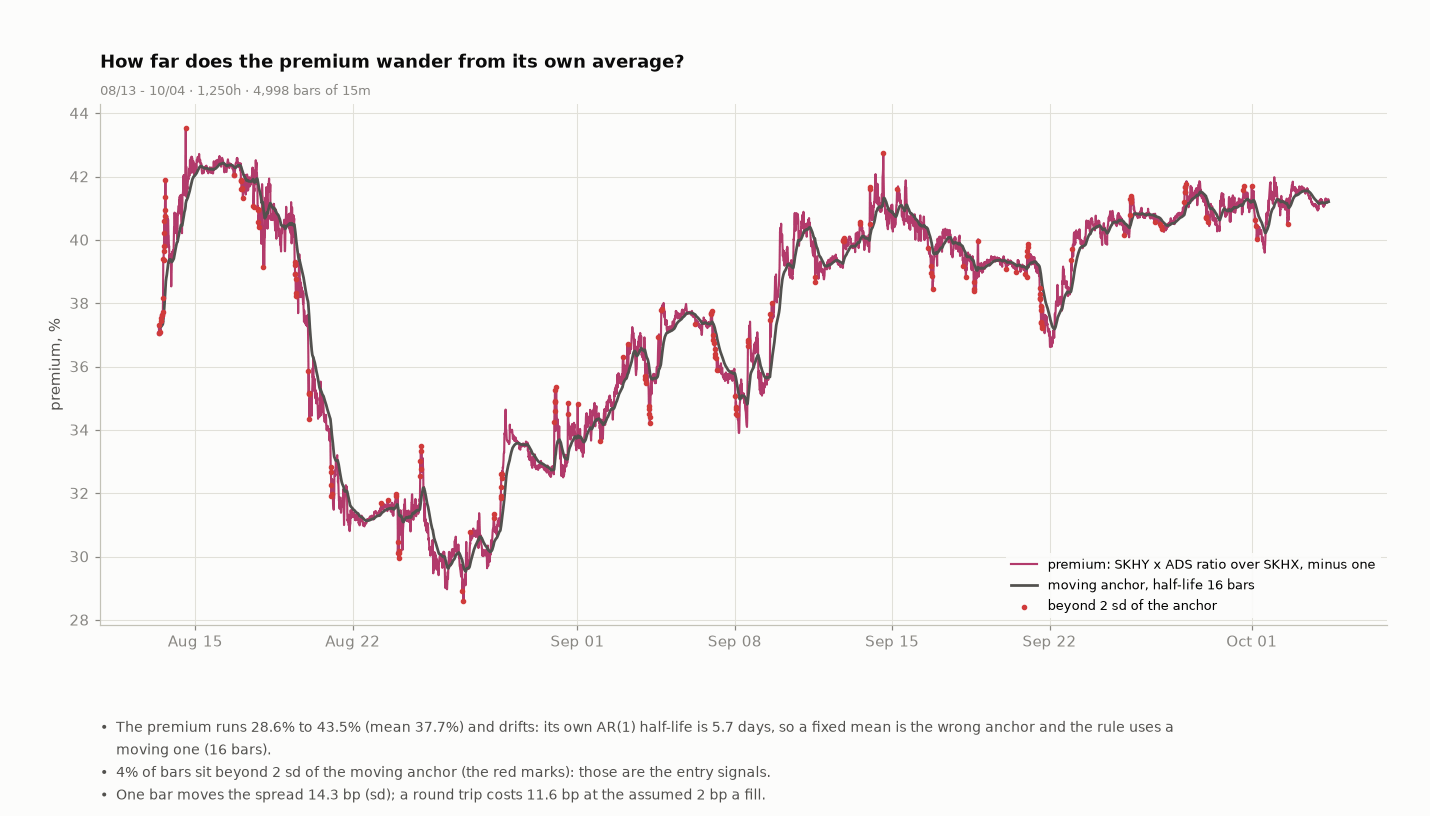

In [10]:
# ---- the premium and its anchor ----
S_ = RES["s"]; M_ = RES["m"]; Z_ = RES["z"]
prem = (np.exp(S_) - 1) * 100
anch = (np.exp(M_) - 1) * 100
ar1 = ST.ar1_fit(S_)
hl_h = ar1["half_life"] * STEP_MS / HOUR
big = np.abs(np.nan_to_num(Z_)) >= Z_IN
BUL = [f"The premium runs {prem.min():.1f}% to {prem.max():.1f}% (mean {prem.mean():.1f}%) and drifts: its own AR(1) half-life is {hl_h / 24:.1f} days, so a fixed mean is the wrong anchor and the rule uses a moving one ({HALF_LIFE} bars).",
       f"{big.mean() * 100:.0f}% of bars sit beyond {Z_IN:g} sd of the moving anchor (the red marks): those are the entry signals.",
       f"One bar moves the spread {np.std(np.diff(S_)) * 1e4:.1f} bp (sd); a round trip costs {RT_COST_BP:.1f} bp at the assumed {SLIP_BPS:g} bp a fill."]
fig, gs, top = mkfig(5.6, BUL)
ax = fig.add_subplot(gs[0])
ax.plot(IDX, prem, color=C_PREM_DK, linewidth=1.4, zorder=4, label="premium: SKHY x ADS ratio over SKHX, minus one")
ax.plot(IDX, anch, color=INK2, linewidth=1.8, zorder=5, label=f"moving anchor, half-life {HALF_LIFE} bars")
ax.scatter(IDX[big], prem[big], s=7, color=CRIT, zorder=6, label=f"beyond {Z_IN:g} sd of the anchor")
ax.set_ylabel("premium, %"); ax.legend(loc="lower right", fontsize=8.5, **LEG); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ask(ax, "How far does the premium wander from its own average?", WS)
figstyle.bullets(fig, BUL)
figstyle.show(fig, "fig:s2-premium", FIGURES)

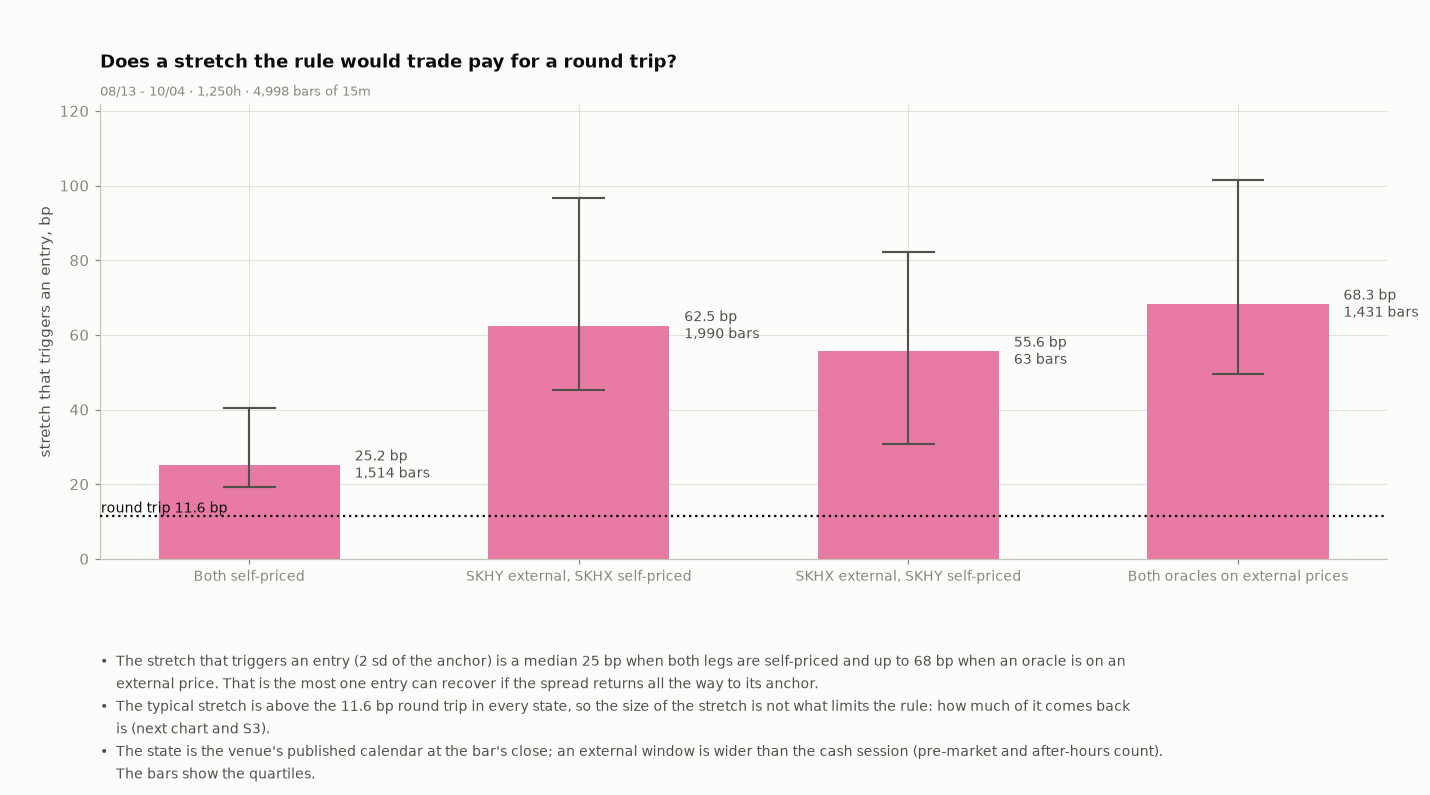

In [11]:
# ---- does a stretch the rule would trade pay for a round trip, by pricing state ----
stretch = Z_IN * RES["sd"] * 1e4                                    # the deviation from the anchor that triggers an entry, in bp: the most one entry can recover
okb = ~np.isnan(stretch)
order = [k for k in ("both_internal", "A_internal_B_external", "A_external_B_internal", "both_external") if ((STATE == k) & okb).sum() > 50]
med_ = {k: float(np.median(stretch[(STATE == k) & okb])) for k in order}
q1_ = {k: float(np.percentile(stretch[(STATE == k) & okb], 25)) for k in order}
q3_ = {k: float(np.percentile(stretch[(STATE == k) & okb], 75)) for k in order}
nb_ = {k: int(((STATE == k) & okb).sum()) for k in order}
pays = [k for k in order if med_[k] > RT_COST_BP]
BUL = [f"The stretch that triggers an entry ({Z_IN:g} sd of the anchor) is a median {min(med_.values()):.0f} bp when both legs are self-priced and up to {max(med_.values()):.0f} bp when an oracle is on an external price. That is the most one entry can recover if the spread returns all the way to its anchor.",
       (f"The typical stretch is above the {RT_COST_BP:.1f} bp round trip in every state, so the size of the stretch is not what limits the rule: how much of it comes back is (next chart and S3)." if len(pays) == len(order) else
        (f"Against a {RT_COST_BP:.1f} bp round trip, the typical stretch pays in: {', '.join(STATE_LABEL[k] for k in pays)}." if pays else f"No state has a typical stretch above the {RT_COST_BP:.1f} bp round trip.")
        + (f" It does not in: {', '.join(STATE_LABEL[k] for k in order if k not in pays)}." if len(pays) < len(order) else "")),
       "The state is the venue's published calendar at the bar's close; an external window is wider than the cash session (pre-market and after-hours count). The bars show the quartiles."]
fig, gs, top = mkfig(5.0, BUL)
ax = fig.add_subplot(gs[0])
xs = np.arange(len(order))
ax.bar(xs, [med_[k] for k in order], color=C_PREM, width=0.55, zorder=3, )
ax.vlines(xs, [q1_[k] for k in order], [q3_[k] for k in order], color=INK2, linewidth=1.4, zorder=5)
ax.hlines([q1_[k] for k in order] + [q3_[k] for k in order], np.r_[xs, xs] - 0.08, np.r_[xs, xs] + 0.08, color=INK2, linewidth=1.4, zorder=5)
for i, k in enumerate(order):
    ax.text(i + 0.32, med_[k], f"{med_[k]:.1f} bp\n{nb_[k]:,} bars", ha="left", va="center", fontsize=9, color=INK2)
ax.axhline(RT_COST_BP, color=INK, linewidth=1.5, linestyle=":", zorder=4); ax.text(-0.45, RT_COST_BP, f"round trip {RT_COST_BP:.1f} bp ", ha="left", va="bottom", color=INK, fontsize=9)
ax.set_xticks(xs); ax.set_xticklabels([STATE_LABEL[k] for k in order], fontsize=9); ax.set_ylabel("stretch that triggers an entry, bp"); ax.set_ylim(0, max(max(q3_.values()), RT_COST_BP) * 1.2)
ask(ax, "Does a stretch the rule would trade pay for a round trip?", WS)
figstyle.bullets(fig, BUL)
figstyle.show(fig, "fig:s2-vol", FIGURES)
STATS_VOL = {"med": med_, "n": nb_}

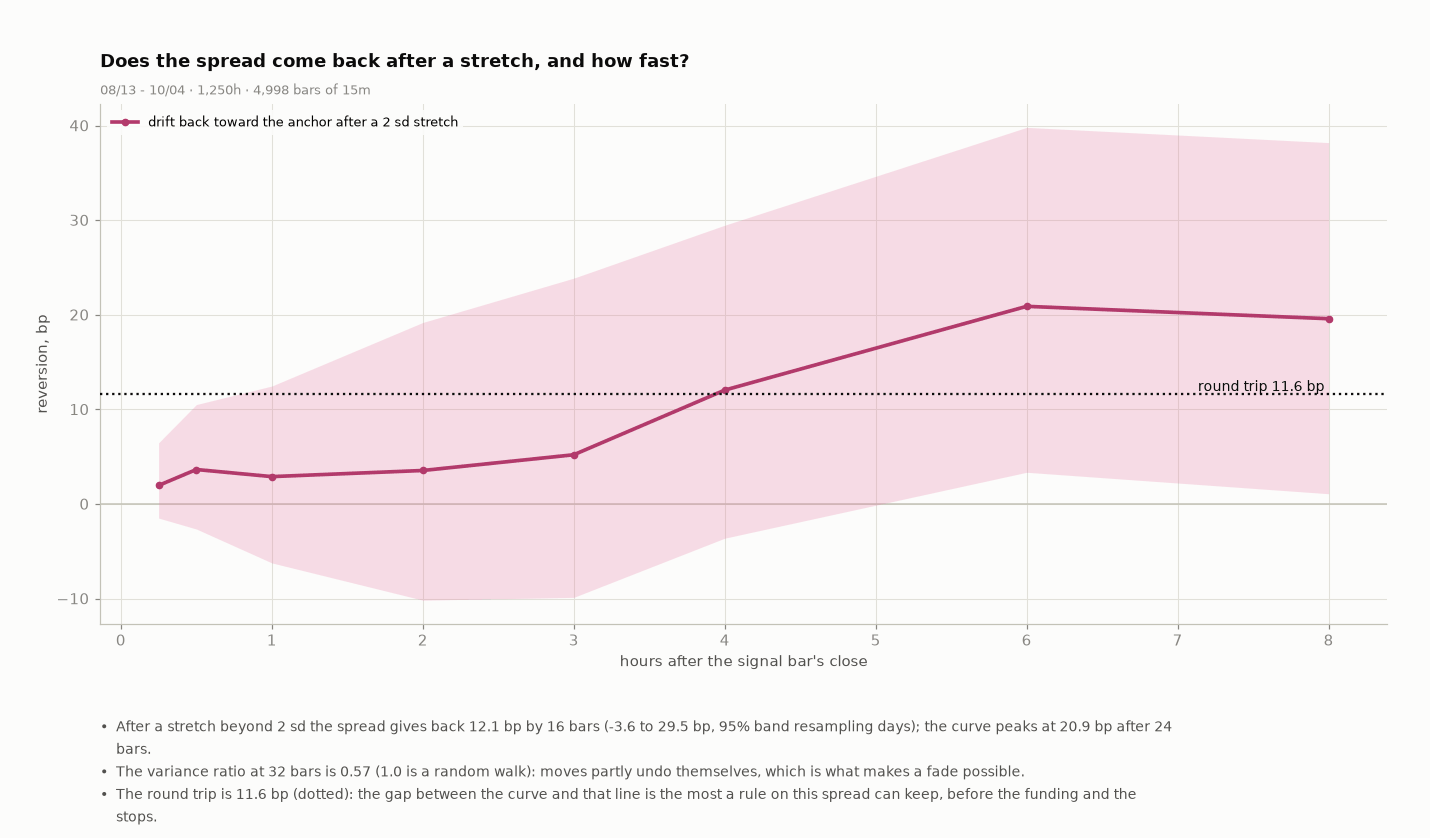

In [12]:
# ---- does the spread come back after a stretch: the thesis itself, before any rule ----
DAYID = (BARS["t"] // DAY).astype(int)
RC = SH.reversion_curve(S_, Z_, Z_IN, HORIZONS, DAYID, n_boot=NSHUF // 2, seed=SEED)
VR = SH.variance_ratio(S_, HORIZONS[1:])
hh = np.array(RC["h"]) * STEP_MS / HOUR
pk = int(np.nanargmax(RC["mean"]))
BUL = [f"After a stretch beyond {Z_IN:g} sd the spread gives back {RC['mean'][HORIZONS.index(MAX_HOLD)]:.1f} bp by {MAX_HOLD} bars ({RC['lo'][HORIZONS.index(MAX_HOLD)]:.1f} to {RC['hi'][HORIZONS.index(MAX_HOLD)]:.1f} bp, 95% band resampling days); the curve peaks at {RC['mean'][pk]:.1f} bp after {RC['h'][pk]} bars.",
       f"The variance ratio at {HORIZONS[-1]} bars is {VR[-1]:.2f} (1.0 is a random walk): moves partly undo themselves, which is what makes a fade possible.",
       f"The round trip is {RT_COST_BP:.1f} bp (dotted): the gap between the curve and that line is the most a rule on this spread can keep, before the funding and the stops."]
fig, gs, top = mkfig(5.6, BUL)
ax = fig.add_subplot(gs[0])
ax.fill_between(hh, RC["lo"], RC["hi"], color=C_PREM, alpha=0.25, linewidth=0, zorder=2)
ax.plot(hh, RC["mean"], color=C_PREM_DK, linewidth=2.4, marker="o", markersize=4, zorder=4, label=f"drift back toward the anchor after a {Z_IN:g} sd stretch")
ax.axhline(RT_COST_BP, color=INK, linewidth=1.5, linestyle=":", zorder=5); ax.text(hh[-1], RT_COST_BP, f"round trip {RT_COST_BP:.1f} bp ", ha="right", va="bottom", color=INK, fontsize=9)
ax.axhline(0, color=AXIS, linewidth=1, zorder=1)
ax.set_xlabel("hours after the signal bar's close"); ax.set_ylabel("reversion, bp"); ax.legend(loc="upper left", fontsize=8.5, **LEG)
ask(ax, "Does the spread come back after a stretch, and how fast?", WS)
figstyle.bullets(fig, BUL)
figstyle.show(fig, "fig:s2-reversion", FIGURES)

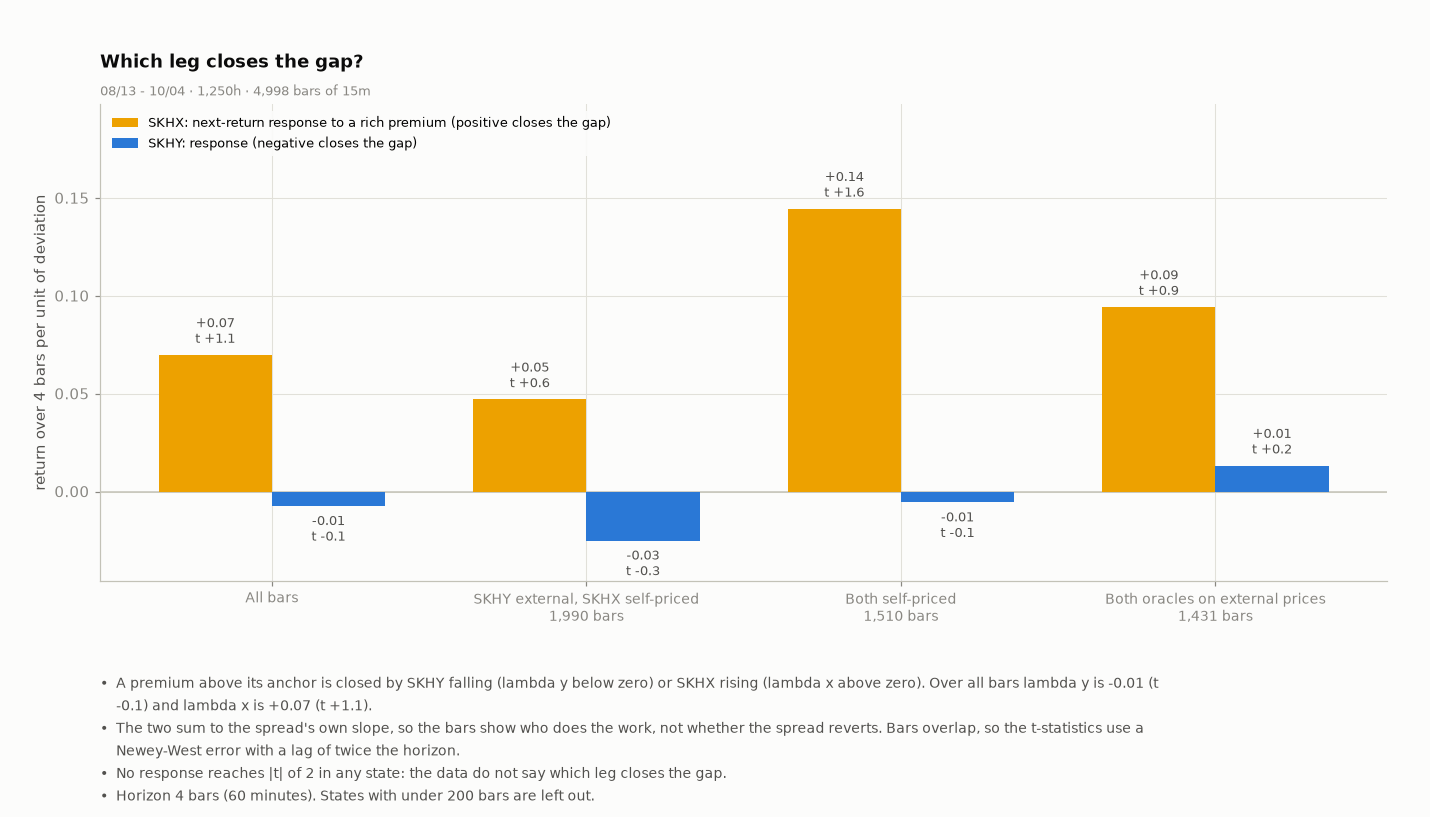

In [13]:
# ---- which leg closes the gap (the stale-leg reading): each leg's next-h-bar return on the spread's deviation from its anchor ----
DEV_ = S_ - M_
EC = {"all": SH.error_correction(BARS["cx"], BARS["cy"], DEV_, EC_H)}
for k in ("A_internal_B_external", "both_internal", "both_external", "A_external_B_internal"):
    r_ = SH.error_correction(BARS["cx"], BARS["cy"], DEV_, EC_H, mask=(STATE == k))
    if r_["n"] >= 200:
        EC[k] = r_
ks = list(EC)
BUL = [f"A premium above its anchor is closed by SKHY falling (lambda y below zero) or SKHX rising (lambda x above zero). Over all bars lambda y is {EC['all']['lam_y']:+.2f} (t {EC['all']['t_y']:+.1f}) and lambda x is {EC['all']['lam_x']:+.2f} (t {EC['all']['t_x']:+.1f}).",
       "The two sum to the spread's own slope, so the bars show who does the work, not whether the spread reverts. Bars overlap, so the t-statistics use a Newey-West error with a lag of twice the horizon.",
       (f"No response reaches |t| of 2 in any state: the data do not say which leg closes the gap." if max(max(abs(EC[k]["t_x"]), abs(EC[k]["t_y"])) for k in ks) < 2 else
        f"Responses reaching |t| of 2: " + ", ".join(f"{('All bars' if k == 'all' else STATE_LABEL[k])} ({'SKHX' if abs(EC[k]['t_x']) >= 2 else 'SKHY'})" for k in ks if max(abs(EC[k]['t_x']), abs(EC[k]['t_y'])) >= 2) + "."),
       f"Horizon {EC_H} bars ({EC_H * STEP_MS / 60000:.0f} minutes). States with under 200 bars are left out."]
fig, gs, top = mkfig(5.2, BUL)
ax = fig.add_subplot(gs[0])
w_ = 0.36
xs = np.arange(len(ks))
ax.bar(xs - w_ / 2, [EC[k]["lam_x"] for k in ks], width=w_, color=C_A, zorder=3, label="SKHX: next-return response to a rich premium (positive closes the gap)")
ax.bar(xs + w_ / 2, [EC[k]["lam_y"] for k in ks], width=w_, color=C_B, zorder=3, label="SKHY: response (negative closes the gap)")
for i, k in enumerate(ks):
    for dx, key, tk in ((-w_ / 2, "lam_x", "t_x"), (w_ / 2, "lam_y", "t_y")):
        v = EC[k][key]; ax.text(i + dx, v + (0.004 if v >= 0 else -0.004), f"{v:+.2f}\nt {EC[k][tk]:+.1f}", ha="center", va="bottom" if v >= 0 else "top", fontsize=8.5, color=INK2)
ax.axhline(0, color=AXIS, linewidth=1, zorder=1)
ax.set_xticks(xs); ax.set_xticklabels(["All bars" if k == "all" else f"{STATE_LABEL[k]}\n{EC[k]['n']:,} bars" for k in ks], fontsize=9)
ax.set_ylabel(f"return over {EC_H} bars per unit of deviation"); ax.legend(loc="upper left", fontsize=8.5, **LEG)
yl = ax.get_ylim(); ax.set_ylim(yl[0] - 0.012, yl[1] + 0.045)
ask(ax, "Which leg closes the gap?", WS)
figstyle.bullets(fig, BUL)
figstyle.show(fig, "fig:s2-leg", FIGURES)

## S3 · Core result

| Question | Gate to S4 |
|---|---|
| Does the fixed rule make money after every cost, unlevered, and is the spread P&L (the thesis) more than luck? | net P&L above the T-bill; the permutation p on the spread P&L below the gate |

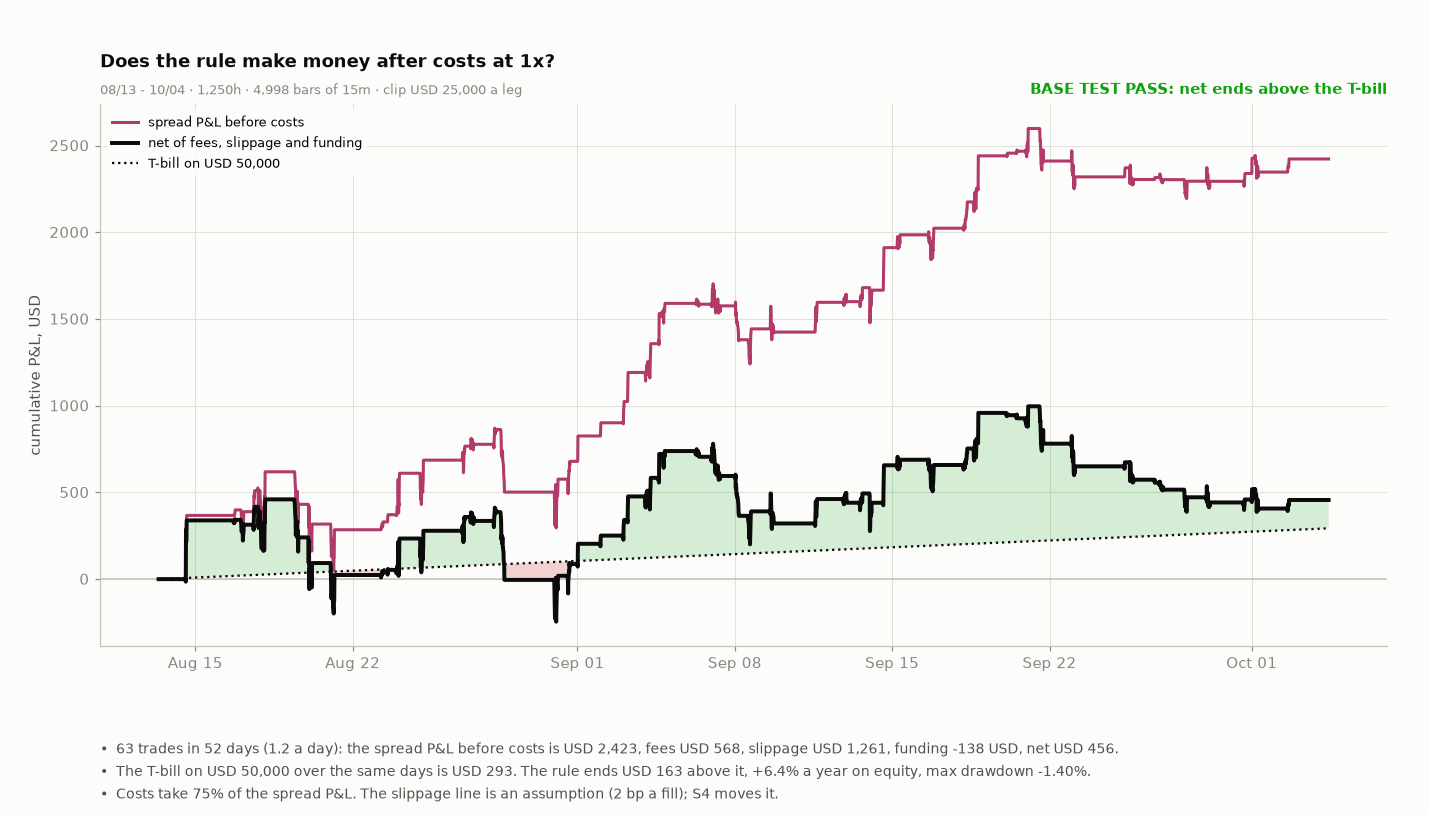

In [14]:
# ---- 1. the equity curve, gross and net, against the T-bill ----
cum_net = np.cumsum(NET_BAR)
cum_gross = np.cumsum(RES["comp"]["price"])
tb_curve = hurdle_curve = CAPITAL * HURDLE * ((BARS["t"] + STEP_MS - T0) / DAY) / 365.0
NET_USD, GROSS_USD = float(cum_net[-1]), float(cum_gross[-1])
HURDLE_USD_ALL = SH.hurdle_usd(CAPITAL, HURDLE, DAYS)
TS = SH.trade_stats(TR, CLIP_USD, DAYS)
assert abs(NET_USD - TS["net_usd"]) < 1e-6 * CAPITAL, "the bar P&L and the trade P&L must agree"
G_BASE = NET_USD > HURDLE_USD_ALL
DAILY = SH.daily(RES)
dr_ = DAILY.to_numpy() / CAPITAL
eq_ = CAPITAL + cum_net
MAXDD_PCT = float(((eq_ / np.maximum.accumulate(eq_)) - 1).min() * 100)
BUL = [f"{TS['n']} trades in {DAYS:.0f} days ({TS['per_day']:.1f} a day): the spread P&L before costs is {usd(GROSS_USD)}, fees {usd(-TS['fees_usd'])}, slippage {usd(-TS['slip_usd'])}, funding {sgn(TS['fund_usd'])} USD, net {usd(NET_USD)}.",
       f"The T-bill on {usd(CAPITAL)} over the same days is {usd(HURDLE_USD_ALL)}. The rule ends {usd(NET_USD - HURDLE_USD_ALL)} {'above' if G_BASE else 'below'} it, {NET_USD / CAPITAL * 365 / DAYS * 100:+.1f}% a year on equity, max drawdown {MAXDD_PCT:.2f}%.",
       f"Costs take {(-(TS['fees_usd'] + TS['slip_usd'])) / GROSS_USD * 100:.0f}% of the spread P&L. The slippage line is an assumption ({SLIP_BPS:g} bp a fill); S4 moves it."]
fig, gs, top = mkfig(5.8, BUL)
ax = fig.add_subplot(gs[0])
ax.plot(IDX, cum_gross, color=C_PREM_DK, linewidth=2.0, zorder=4, label="spread P&L before costs")
ax.plot(IDX, cum_net, color=INK, linewidth=2.6, zorder=5, label="net of fees, slippage and funding")
ax.plot(IDX, tb_curve, color=INK, linewidth=1.5, linestyle=":", zorder=3, label=f"T-bill on {usd(CAPITAL)}")
ax.fill_between(IDX, cum_net, tb_curve, where=(cum_net >= tb_curve), interpolate=True, color=GOOD, alpha=0.16, linewidth=0, zorder=2)
ax.fill_between(IDX, cum_net, tb_curve, where=(cum_net < tb_curve), interpolate=True, color=CRIT, alpha=0.22, linewidth=0, zorder=2)
ax.axhline(0, color=AXIS, linewidth=1, zorder=1)
ax.text(1.0, 1.012, "BASE TEST " + ("PASS: net ends above the T-bill" if G_BASE else "FAIL: net ends below the T-bill"), transform=ax.transAxes, ha="right", va="bottom", color=(GOOD if G_BASE else CRIT), fontsize=9.5, fontweight="bold")
ax.set_ylabel("cumulative P&L, USD"); ax.legend(loc="upper left", fontsize=8.5, **LEG); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ask(ax, "Does the rule make money after costs at 1x?", WS + f" · clip {usd(CLIP_USD)} a leg")
figstyle.bullets(fig, BUL)
figstyle.show(fig, "fig:s3-equity", FIGURES)

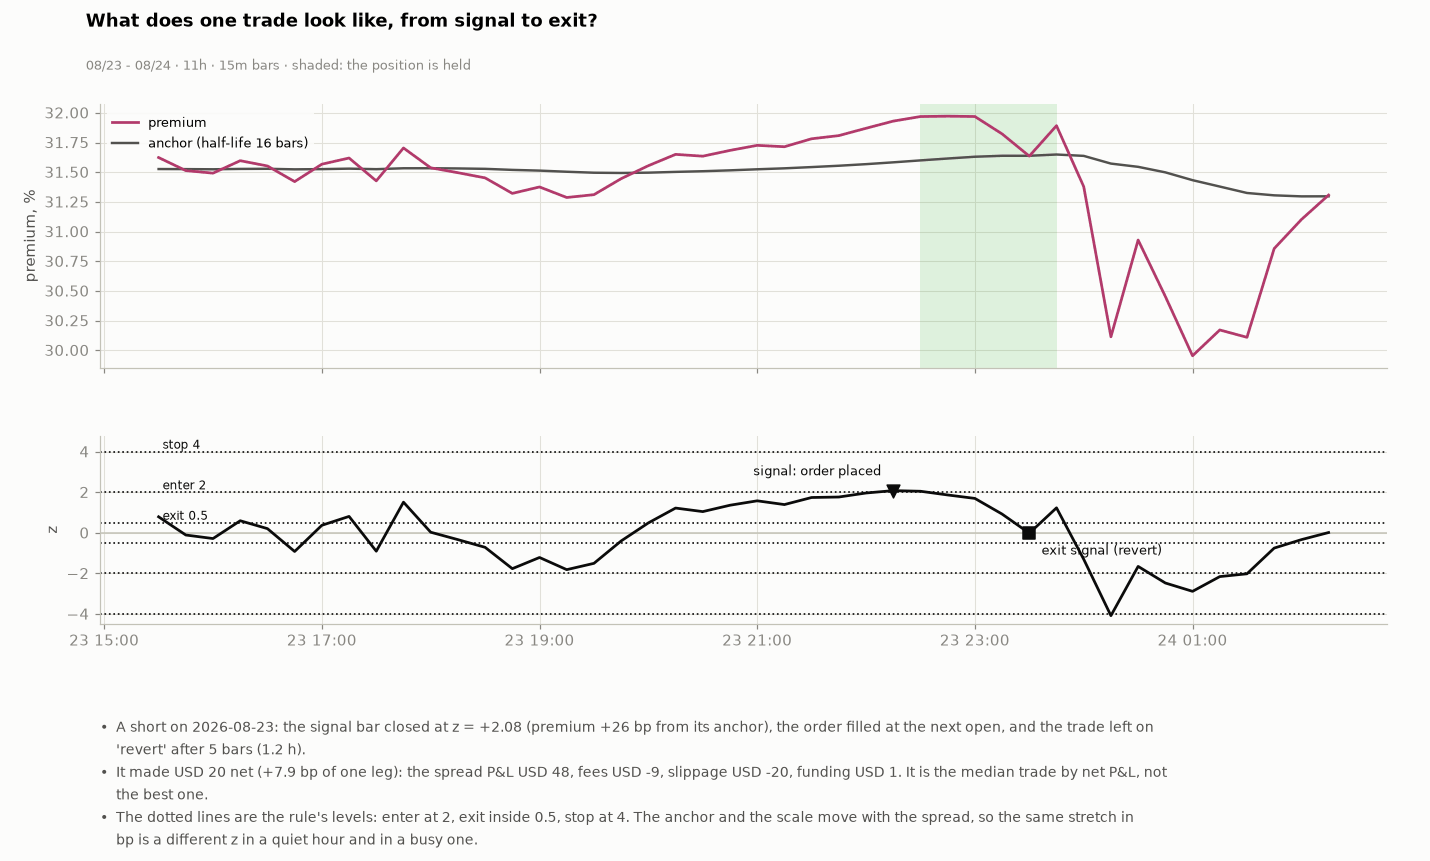

In [15]:
# ---- one trade, from signal to exit: the median trade by net P&L ----
Z_ = RES["z"]
ord_ = TR.sort_values("net").reset_index(drop=True)
EX = ord_.iloc[len(ord_) // 2]
j_, e_ = int(EX["entry_bar"]), int(EX["exit_bar"])
lo_, hi_ = max(j_ - 28, 0), min(e_ + 10, N_BARS - 1)
sl_ = slice(lo_, hi_ + 1)
xs_ = IDX[sl_]
BUL = [f"A {'short' if EX['side'] < 0 else 'long'} on {iso_(int(EX['entry_t']))[:10]}: the signal bar closed at z = {EX['z_entry']:+.2f} (premium {EX['dev_bp']:+.0f} bp from its anchor), the order filled at the next open, and the trade left on '{EX['exit_reason']}' after {int(EX['bars'])} bars ({EX['bars'] * STEP_MS / HOUR:.1f} h).",
       f"It made {usd(EX['net'])} net ({EX['net'] / CLIP_USD * 1e4:+.1f} bp of one leg): the spread P&L {usd(EX['price'])}, fees {usd(EX['fees'])}, slippage {usd(EX['slip'])}, funding {usd(EX['funding'])}. It is the median trade by net P&L, not the best one.",
       f"The dotted lines are the rule's levels: enter at {Z_IN:g}, exit inside {Z_OUT:g}, stop at {Z_STOP:g}. The anchor and the scale move with the spread, so the same stretch in bp is a different z in a quiet hour and in a busy one."]
fig, gs, top = mkfig(5.6, BUL, nrows=2, ncols=1, ratios=(1.4, 1.0), hspace=0.3)
ax1, ax2 = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])
ax1.plot(xs_, prem[sl_], color=C_PREM_DK, linewidth=1.8, zorder=4, label="premium")
ax1.plot(xs_, anch[sl_], color=INK2, linewidth=1.6, zorder=3, label=f"anchor (half-life {HALF_LIFE} bars)")
ax1.axvspan(IDX[j_], IDX[e_], color=GOOD if EX["net"] > 0 else CRIT, alpha=0.12, linewidth=0, zorder=1)
ax1.set_ylabel("premium, %"); ax1.legend(loc="upper left", fontsize=8.5, **LEG)
ax1.tick_params(labelbottom=False)
ax2.plot(xs_, Z_[sl_], color=INK, linewidth=1.8, zorder=4)
for lv_, sty_ in ((Z_IN, ":"), (-Z_IN, ":"), (Z_OUT, ":"), (-Z_OUT, ":"), (Z_STOP, ":"), (-Z_STOP, ":"), (0.0, "-")):
    ax2.axhline(lv_, color=INK if lv_ else AXIS, linewidth=1.1 if lv_ else 1.0, linestyle=sty_, zorder=2)
ax2.text(xs_[0], Z_IN, f" enter {Z_IN:g}", fontsize=8, va="bottom", color=INK); ax2.text(xs_[0], Z_OUT, f" exit {Z_OUT:g}", fontsize=8, va="bottom", color=INK); ax2.text(xs_[0], Z_STOP, f" stop {Z_STOP:g}", fontsize=8, va="bottom", color=INK)
sig_i, ex_i = j_ - 1, e_ - 1
ax2.scatter([IDX[sig_i]], [Z_[sig_i]], s=70, marker="v" if EX["side"] < 0 else "^", color=INK, zorder=6)
ax2.scatter([IDX[ex_i]], [Z_[ex_i]], s=70, marker="s", color=INK, zorder=6)
ax2.annotate("signal: order placed", (IDX[sig_i], Z_[sig_i]), textcoords="offset points", xytext=(-8, 10), ha="right", fontsize=8.5, color=INK)
ax2.annotate(f"exit signal ({EX['exit_reason']})", (IDX[ex_i], Z_[ex_i]), textcoords="offset points", xytext=(8, -14), ha="left", fontsize=8.5, color=INK)
ax2.set_ylabel("z"); ax2.set_ylim(min(Z_[sl_].min(), -Z_STOP) - 0.4, max(Z_[sl_].max(), Z_STOP) + 0.8)
for ax_ in (ax1, ax2):
    ax_.xaxis.set_major_locator(mdates.HourLocator(interval=2)); ax_.xaxis.set_major_formatter(mdates.DateFormatter("%d %H:%M"))
fig_ask(fig, "What does one trade look like, from signal to exit?", f"{iso_(int(BARS['t'][lo_]))[5:10].replace('-', '/')} - {iso_(int(BARS['t'][hi_]))[5:10].replace('-', '/')} \u00b7 {(hi_ - lo_ + 1) * STEP_MS / HOUR:,.0f}h \u00b7 {BAR} bars \u00b7 shaded: the position is held", top)
figstyle.bullets(fig, BUL)
figstyle.show(fig, "fig:s3-example", FIGURES)

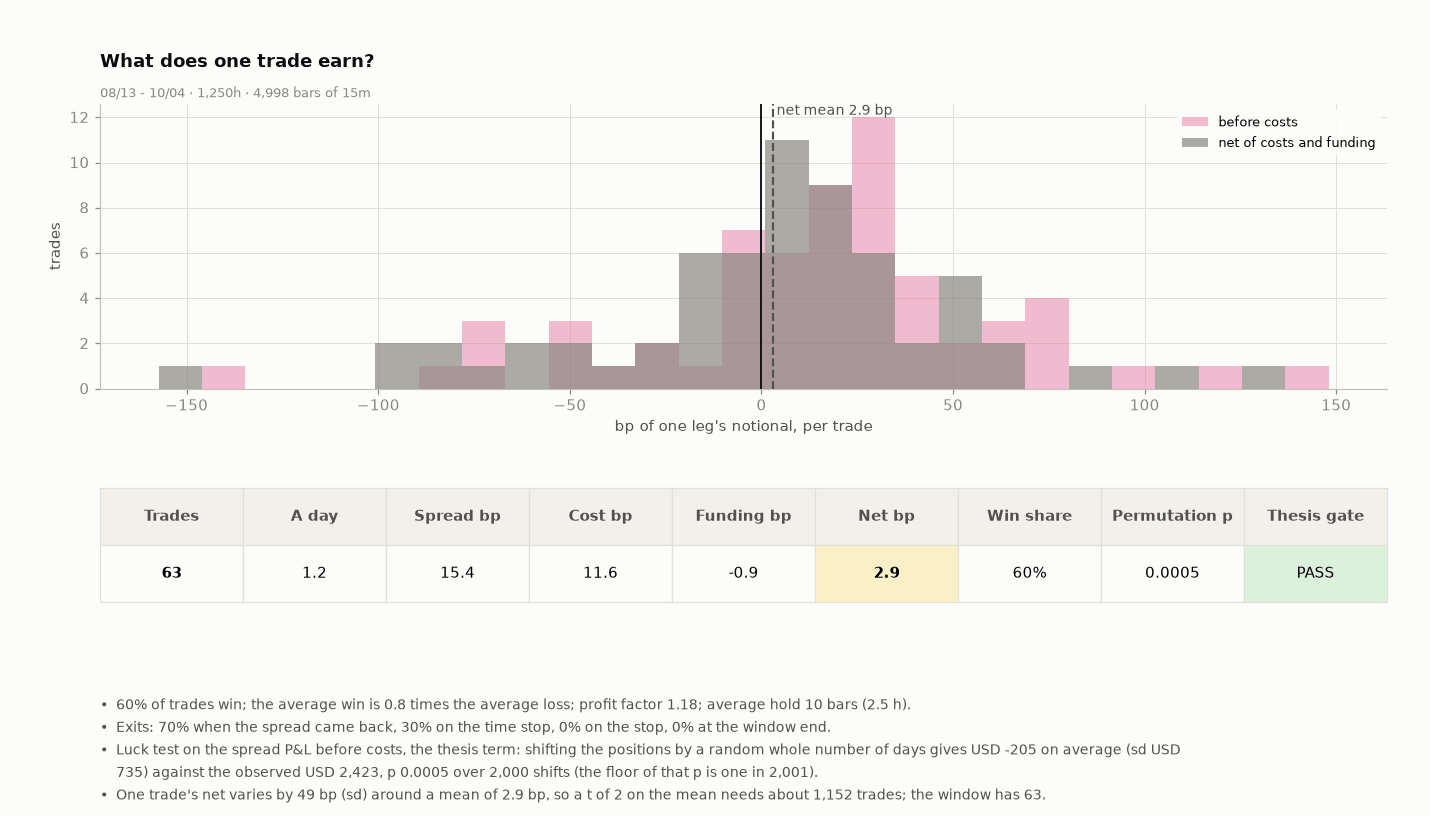

In [16]:
# ---- 2. what one trade earns, and the luck test on the thesis term ----
PERM = SH.permutation_gross(RES, BARS, CLIP_USD, int(DAY // STEP_MS), n=NSHUF, seed=SEED)
assert abs(PERM["observed"] - GROSS_USD) < 0.01 * max(1.0, abs(GROSS_USD)) + 5.0, (PERM["observed"], GROSS_USD)      # the constant-notional read equals the engine's exact price P&L
G_PERM = PERM["p"] < P_GATE
nb_ = TR["net"].to_numpy() / CLIP_USD * 1e4
gb_ = TR["price"].to_numpy() / CLIP_USD * 1e4
BUL = [f"{TS['hit'] * 100:.0f}% of trades win; the average win is {TS['payoff']:.1f} times the average loss; profit factor {TS['pf']:.2f}; average hold {TS['hold_bars']:.0f} bars ({TS['hold_bars'] * STEP_MS / HOUR:.1f} h).",
       f"Exits: {TS['revert'] * 100:.0f}% when the spread came back, {TS['time'] * 100:.0f}% on the time stop, {TS['stop'] * 100:.0f}% on the stop, {TS['end'] * 100:.0f}% at the window end.",
       f"Luck test on the spread P&L before costs, the thesis term: shifting the positions by a random whole number of days gives {usd(PERM['null_mean'])} on average (sd {usd(PERM['null_sd'])}) against the observed {usd(PERM['observed'])}, p {PERM['p']:.4f} over {NSHUF:,} shifts (the floor of that p is one in {NSHUF + 1:,}).",
       (f"One trade's net varies by {nb_.std(ddof=1):.0f} bp (sd) around a mean of {nb_.mean():.1f} bp, so a t of 2 on the mean needs about {(2 * nb_.std(ddof=1) / nb_.mean()) ** 2:,.0f} trades; the window has {len(nb_)}." if nb_.mean() > 0 else f"One trade's net varies by {nb_.std(ddof=1):.0f} bp (sd) around a mean that is not above zero.")]
fig, gs, top = mkfig(5.4, BUL, nrows=2, ncols=1, ratios=(2.5, 1.0), hspace=0.5)
ax, axt = fig.add_subplot(gs[0]), fig.add_subplot(gs[1]); axt.axis("off")
bins = np.linspace(min(nb_.min(), gb_.min()) - 1, max(nb_.max(), gb_.max()) + 1, 28)
ax.hist(gb_, bins=bins, color=C_PREM, alpha=0.5, zorder=2, label="before costs")
ax.hist(nb_, bins=bins, color=C_COST, alpha=0.7, zorder=3, label="net of costs and funding")
ax.axvline(0, color=INK, linewidth=1.2, zorder=4); ax.axvline(float(nb_.mean()), color=INK2, linewidth=1.4, linestyle="--", zorder=4)
ax.text(float(nb_.mean()), ax.get_ylim()[1], f" net mean {nb_.mean():.1f} bp", color=INK2, fontsize=9, va="top")
ax.set_xlabel("bp of one leg's notional, per trade"); ax.set_ylabel("trades"); ax.legend(loc="upper right", fontsize=8.5, **LEG)
ask(ax, "What does one trade earn?", WS)
cells = [[f"{TS['n']}", f"{TS['per_day']:.1f}", f"{TS['gross_bp']:.1f}", f"{TS['cost_bp']:.1f}", f"{TS['fund_bp']:+.1f}", f"{TS['net_bp']:.1f}", f"{TS['hit'] * 100:.0f}%", f"{PERM['p']:.4f}", "PASS" if G_PERM else "FAIL"]]
tb = figstyle.put_table(axt, cells, ["Trades", "A day", "Spread bp", "Cost bp", "Funding bp", "Net bp", "Win share", "Permutation p", "Thesis gate"], size=10)
figstyle.gold(tb, 1, 5); figstyle.tint(tb, 1, 8, "green" if G_PERM else "rose")
figstyle.bullets(fig, BUL)
figstyle.show(fig, "fig:s3-trades", FIGURES)

## S4 · Robustness

| Question | Gates to S6 |
|---|---|
| Is it real: out of sample, beyond luck against the T-bill, after more cost, a late fill and the number of settings we tried? Can it trade faster, and does a rule help? | out-of-sample above the T-bill; day-block p and the deflated Sharpe; no cost cell below 4 bp flips it; a one-bar delay holds |

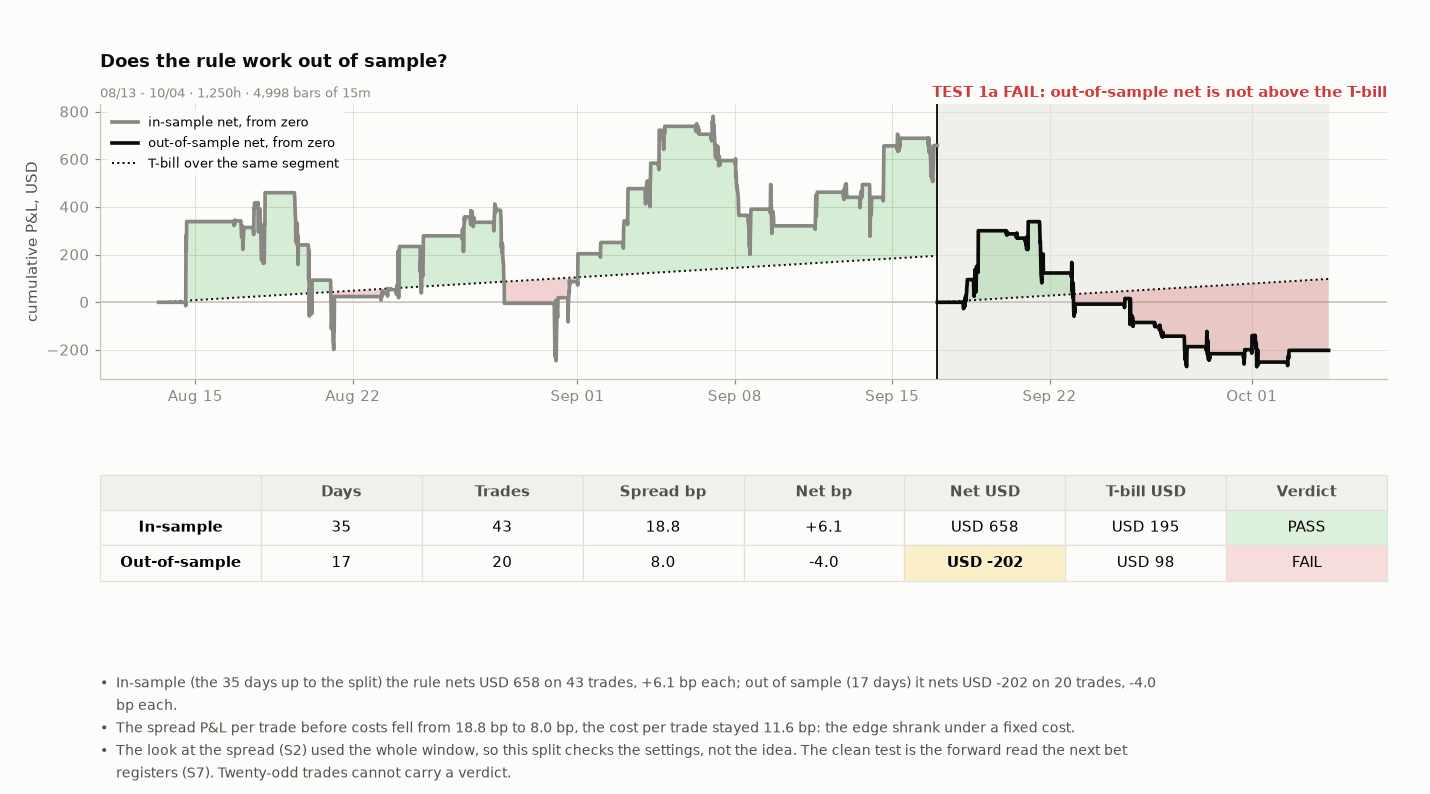

In [17]:
# ---- Test 1a: out of sample. The rule is the pre-registered one; the split only separates the days it was looked at from the last third ----
def seg(mask):
    return float(NET_BAR[mask].sum())
NET_IS, NET_OOS = seg(M_IS), seg(~M_IS)
HUR_IS, HUR_OOS = SH.hurdle_usd(CAPITAL, HURDLE, DAYS_IS), SH.hurdle_usd(CAPITAL, HURDLE, DAYS_OOS)
TR_IS, TR_OOS = TR[TR["entry_t"] < T_SPLIT], TR[TR["entry_t"] >= T_SPLIT]
TS_IS, TS_OOS = SH.trade_stats(TR_IS, CLIP_USD, DAYS_IS), SH.trade_stats(TR_OOS, CLIP_USD, DAYS_OOS)
G_OOS = NET_OOS > HUR_OOS
BUL = [f"In-sample (the {DAYS_IS:.0f} days up to the split) the rule nets {usd(NET_IS)} on {TS_IS['n']} trades, {TS_IS['net_bp']:+.1f} bp each; out of sample ({DAYS_OOS:.0f} days) it nets {usd(NET_OOS)} on {TS_OOS['n']} trades, {TS_OOS['net_bp']:+.1f} bp each.",
       f"The spread P&L per trade before costs fell from {TS_IS['gross_bp']:.1f} bp to {TS_OOS['gross_bp']:.1f} bp, the cost per trade stayed {TS_OOS['cost_bp']:.1f} bp: the edge shrank under a fixed cost.",
       "The look at the spread (S2) used the whole window, so this split checks the settings, not the idea. The clean test is the forward read the next bet registers (S7). Twenty-odd trades cannot carry a verdict."]
fig, gs, top = mkfig(5.2, BUL, nrows=2, ncols=1, ratios=(2.6, 1.0), hspace=0.5)
ax, axt = fig.add_subplot(gs[0]), fig.add_subplot(gs[1]); axt.axis("off")
sp_ts = pd.Timestamp(T_SPLIT, unit="ms", tz="UTC")
ax.axvspan(sp_ts, IDX[-1], color=AXIS, alpha=0.22, linewidth=0, zorder=0)
for m_, col_ in ((M_IS, MUTED), (~M_IS, INK)):
    c_ = np.cumsum(NET_BAR[m_]); t_ = CAPITAL * HURDLE * ((BARS["t"][m_] + STEP_MS - BARS["t"][m_][0]) / DAY) / 365.0
    ax.plot(IDX[m_], c_, color=col_, linewidth=2.4, zorder=4); ax.plot(IDX[m_], t_, color=INK, linewidth=1.3, linestyle=":", zorder=3)
    ax.fill_between(IDX[m_], c_, t_, where=(c_ >= t_), interpolate=True, color=GOOD, alpha=0.16, linewidth=0, zorder=2)
    ax.fill_between(IDX[m_], c_, t_, where=(c_ < t_), interpolate=True, color=CRIT, alpha=0.22, linewidth=0, zorder=2)
ax.plot([], [], color=MUTED, linewidth=2.4, label="in-sample net, from zero"); ax.plot([], [], color=INK, linewidth=2.4, label="out-of-sample net, from zero")
ax.plot([], [], color=INK, linewidth=1.3, linestyle=":", label="T-bill over the same segment")
ax.axhline(0, color=AXIS, linewidth=1, zorder=1); ax.axvline(sp_ts, color=INK, linewidth=1.2, zorder=3)
ax.text(1.0, 1.012, "TEST 1a " + ("PASS: out-of-sample net is above the T-bill" if G_OOS else "FAIL: out-of-sample net is not above the T-bill"), transform=ax.transAxes, ha="right", va="bottom", color=(GOOD if G_OOS else CRIT), fontsize=9.5, fontweight="bold")
ax.set_ylabel("cumulative P&L, USD"); ax.legend(loc="upper left", fontsize=8.5, **LEG); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ask(ax, "Does the rule work out of sample?", WS)
cells = [[nm, f"{d_:.0f}", f"{t_['n']}", f"{t_['gross_bp']:.1f}", f"{t_['net_bp']:+.1f}", usd(n_), usd(h_), "PASS" if n_ > h_ else "FAIL"]
         for nm, d_, t_, n_, h_ in (("In-sample", DAYS_IS, TS_IS, NET_IS, HUR_IS), ("Out-of-sample", DAYS_OOS, TS_OOS, NET_OOS, HUR_OOS))]
tb = figstyle.put_table(axt, cells, ["", "Days", "Trades", "Spread bp", "Net bp", "Net USD", "T-bill USD", "Verdict"], size=10)
figstyle.gold(tb, 2, 5); figstyle.tint(tb, 1, 7, "green" if cells[0][7] == "PASS" else "rose"); figstyle.tint(tb, 2, 7, "green" if cells[1][7] == "PASS" else "rose")
figstyle.bullets(fig, BUL)
figstyle.show(fig, "fig:s4-oos", FIGURES)

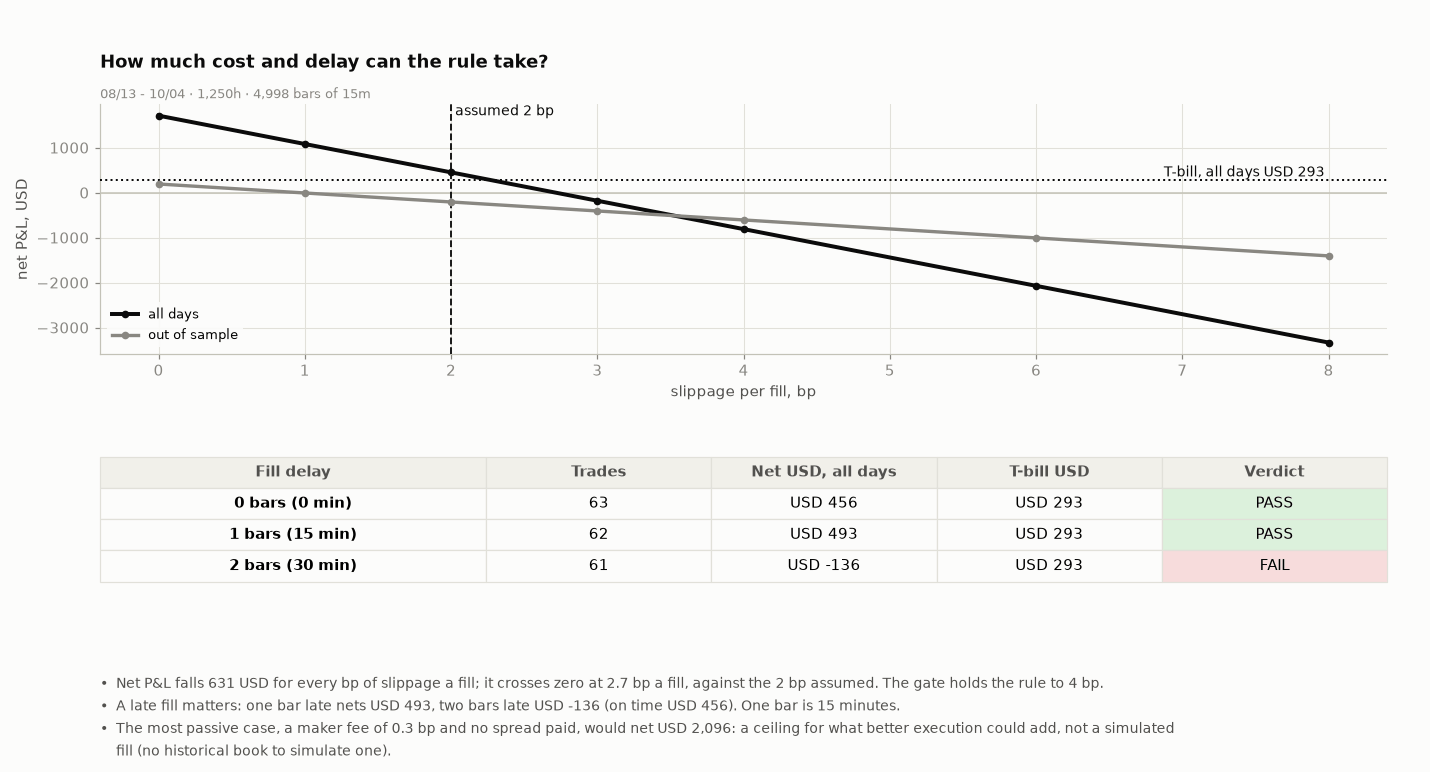

In [18]:
# ---- Test 1c: more cost, and a late fill ----
def net_at(res_bars, slip, delay=0, spec=SPEC, fx=FXA, fy=FYA, bars=BARS, no_entry=None):
    r_ = runv(bars, spec, SH.Costs(clip_usd=CLIP_USD, fee_bp=FEE_BPS, slip_bp=slip, delay_bars=delay), fx, fy, no_entry)
    return r_
SW = {s_: net_at(None, s_) for s_ in SLIP_SWEEP}
sw_all = [float(SW[s_]["bar_net"].sum()) for s_ in SLIP_SWEEP]
sw_oos = [float(SW[s_]["bar_net"][~M_IS].sum()) for s_ in SLIP_SWEEP]
BE_ALL = SH.breakeven_slip_bp(TR, FEE_BPS)
DL = {d_: net_at(None, SLIP_BPS, delay=d_) for d_ in DELAYS}
dl_net = {d_: float(DL[d_]["bar_net"].sum()) for d_ in DELAYS}
G_COST = all(float(SW[s_]["bar_net"].sum()) > 0 for s_ in SLIP_SWEEP if s_ <= SLIP_PASS)
G_DELAY = dl_net[1] > HURDLE_USD_ALL
cost_floor = runv(BARS, SPEC, SH.Costs(clip_usd=CLIP_USD, fee_bp=MAKER_BPS, slip_bp=0.0), FXA, FYA)       # the passive FLOOR: maker fee, no spread: a bound, not a fill model
FLOOR_NET = float(cost_floor["bar_net"].sum())
BUL = [f"Net P&L falls {abs((sw_all[1] - sw_all[0])):,.0f} USD for every bp of slippage a fill; it crosses zero at {BE_ALL:.1f} bp a fill, against the {SLIP_BPS:g} bp assumed. The gate holds the rule to {SLIP_PASS:g} bp.",
       f"A late fill matters: one bar late nets {usd(dl_net[1])}, two bars late {usd(dl_net[2])} (on time {usd(dl_net[0])}). One bar is {STEP_MS / 60000:.0f} minutes.",
       f"The most passive case, a maker fee of {MAKER_BPS:g} bp and no spread paid, would net {usd(FLOOR_NET)}: a ceiling for what better execution could add, not a simulated fill (no historical book to simulate one)."]
fig, gs, top = mkfig(5.2, BUL, nrows=2, ncols=1, ratios=(2.4, 1.2), hspace=0.55)
ax, axt = fig.add_subplot(gs[0]), fig.add_subplot(gs[1]); axt.axis("off")
ax.plot(SLIP_SWEEP, sw_all, color=INK, linewidth=2.6, marker="o", markersize=4, zorder=4, label="all days")
ax.plot(SLIP_SWEEP, sw_oos, color=MUTED, linewidth=2.2, marker="o", markersize=4, zorder=4, label="out of sample")
ax.axhline(0, color=AXIS, linewidth=1, zorder=1); ax.axhline(HURDLE_USD_ALL, color=INK, linewidth=1.3, linestyle=":", zorder=3)
ax.text(SLIP_SWEEP[-1], HURDLE_USD_ALL, f"T-bill, all days {usd(HURDLE_USD_ALL)} ", ha="right", va="bottom", color=INK, fontsize=9)
ax.axvline(SLIP_BPS, color=INK, linewidth=1.2, linestyle="--", zorder=3); ax.text(SLIP_BPS, ax.get_ylim()[1], f" assumed {SLIP_BPS:g} bp", color=INK, fontsize=9, va="top")
ax.set_xlabel("slippage per fill, bp"); ax.set_ylabel("net P&L, USD"); ax.legend(loc="lower left", fontsize=8.5, **LEG)
ask(ax, "How much cost and delay can the rule take?", WS)
cells = [[f"{d_} bars ({d_ * STEP_MS / 60000:.0f} min)", f"{len(DL[d_]['trades'])}", usd(dl_net[d_]), usd(HURDLE_USD_ALL), "PASS" if dl_net[d_] > HURDLE_USD_ALL else "FAIL"] for d_ in DELAYS]
tb = figstyle.put_table(axt, cells, ["Fill delay", "Trades", "Net USD, all days", "T-bill USD", "Verdict"], size=10, first=0.3)
for r_ in range(1, len(DELAYS) + 1):
    figstyle.tint(tb, r_, 4, "green" if cells[r_ - 1][4] == "PASS" else "rose")
figstyle.bullets(fig, BUL)
figstyle.show(fig, "fig:s4-costs", FIGURES)

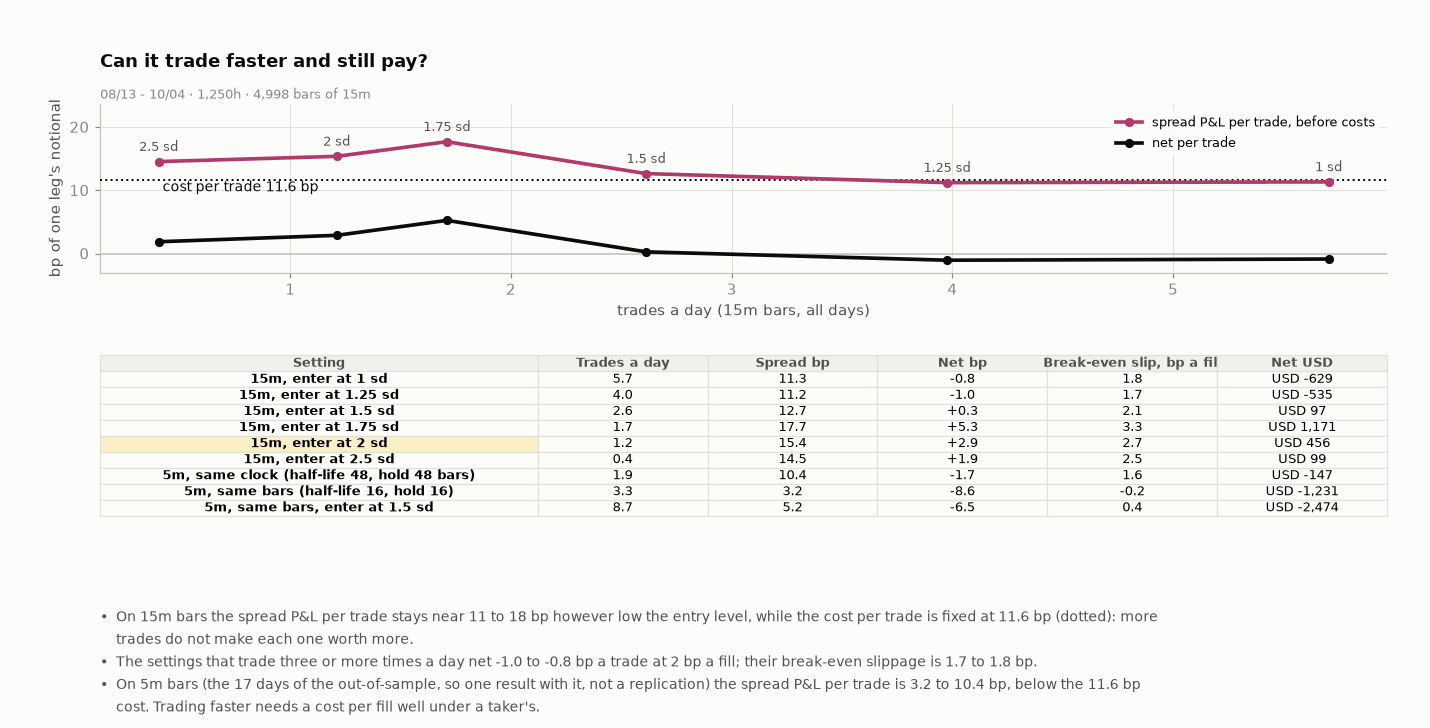

In [19]:
# ---- Test 2a: can it trade faster? the frequency ladder, then the 5m resolution (the same days as the out-of-sample, so ONE result with it) ----
LAD = []
for zi in LADDER_Z:
    r_ = runv(BARS, SH.Spec(half_life=HALF_LIFE, z_in=zi, z_out=Z_OUT, z_stop=Z_STOP, max_hold=MAX_HOLD), COSTS, FXA, FYA)
    t_ = SH.trade_stats(r_["trades"], CLIP_USD, DAYS)
    LAD.append({"label": f"15m, enter at {zi:g} sd", "n": t_["n"], "per_day": t_["per_day"], "gross": t_["gross_bp"], "net": t_["net_bp"], "be": SH.breakeven_slip_bp(r_["trades"], FEE_BPS), "usd": t_["net_usd"]})
D5 = (int(BARS5["t"][-1]) + STEP5_MS - int(BARS5["t"][0])) / DAY
f5 = (STEP_MS // STEP5_MS)
for lab, sp5 in ((f"5m, same clock (half-life {HALF_LIFE * f5}, hold {MAX_HOLD * f5} bars)", SH.Spec(half_life=HALF_LIFE * f5, z_in=Z_IN, z_out=Z_OUT, z_stop=Z_STOP, max_hold=MAX_HOLD * f5)),
                 (f"5m, same bars (half-life {HALF_LIFE}, hold {MAX_HOLD})", SH.Spec(half_life=HALF_LIFE, z_in=Z_IN, z_out=Z_OUT, z_stop=Z_STOP, max_hold=MAX_HOLD)),
                 (f"5m, same bars, enter at 1.5 sd", SH.Spec(half_life=HALF_LIFE, z_in=1.5, z_out=Z_OUT, z_stop=Z_STOP, max_hold=MAX_HOLD))):
    r_ = runv(BARS5, sp5, COSTS, FX5, FY5)
    t_ = SH.trade_stats(r_["trades"], CLIP_USD, D5)
    LAD.append({"label": lab, "n": t_["n"], "per_day": t_["per_day"], "gross": t_["gross_bp"], "net": t_["net_bp"], "be": SH.breakeven_slip_bp(r_["trades"], FEE_BPS), "usd": t_["net_usd"]})
L15, L5 = LAD[:len(LADDER_Z)], LAD[len(LADDER_Z):]
fast = [r_ for r_ in L15 if r_["per_day"] >= 3]
FAST_NET = [r_["net"] for r_ in fast] or [float("nan")]
BUL = [f"On 15m bars the spread P&L per trade stays near {min(r_['gross'] for r_ in L15):.0f} to {max(r_['gross'] for r_ in L15):.0f} bp however low the entry level, while the cost per trade is fixed at {RT_COST_BP:.1f} bp (dotted): more trades do not make each one worth more.",
       (f"The settings that trade three or more times a day net {min(r_['net'] for r_ in fast):+.1f} to {max(r_['net'] for r_ in fast):+.1f} bp a trade at {SLIP_BPS:g} bp a fill; their break-even slippage is {min(r_['be'] for r_ in fast):.1f} to {max(r_['be'] for r_ in fast):.1f} bp." if fast else "No 15m setting trades three times a day."),
       f"On 5m bars (the {D5:.0f} days of the out-of-sample, so one result with it, not a replication) the spread P&L per trade is {min(r_['gross'] for r_ in L5):.1f} to {max(r_['gross'] for r_ in L5):.1f} bp, {'below' if max(r_['gross'] for r_ in L5) < RT_COST_BP else 'not below'} the {RT_COST_BP:.1f} bp cost. Trading faster needs a cost per fill well under a taker's."]
fig, gs, top = mkfig(4.6, BUL, nrows=2, ncols=1, ratios=(2.0, 1.9), hspace=0.5)
ax, axt = fig.add_subplot(gs[0]), fig.add_subplot(gs[1]); axt.axis("off")
xs = [r_["per_day"] for r_ in L15]
ax.plot(xs, [r_["gross"] for r_ in L15], color=C_PREM_DK, linewidth=2.4, marker="o", markersize=5, zorder=4, label="spread P&L per trade, before costs")
ax.plot(xs, [r_["net"] for r_ in L15], color=INK, linewidth=2.4, marker="o", markersize=5, zorder=5, label="net per trade")
ax.axhline(RT_COST_BP, color=INK, linewidth=1.3, linestyle=":", zorder=3); ax.text(min(xs), RT_COST_BP, f" cost per trade {RT_COST_BP:.1f} bp", ha="left", va="top", color=INK, fontsize=9)
ax.axhline(0, color=AXIS, linewidth=1, zorder=1)
ax.set_ylim(min(-3, min(r_["net"] for r_ in L15) - 2), max(r_["gross"] for r_ in L15) + 6)
for r_, zi in zip(L15, LADDER_Z):
    ax.annotate(f"{zi:g} sd", (r_["per_day"], r_["gross"]), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8.5, color=INK2)
ax.set_xlabel("trades a day (15m bars, all days)"); ax.set_ylabel("bp of one leg's notional"); ax.legend(loc="upper right", fontsize=8.5, **LEG)
ask(ax, "Can it trade faster and still pay?", WS)
cells = [[r_["label"], f"{r_['per_day']:.1f}", f"{r_['gross']:.1f}", f"{r_['net']:+.1f}", f"{r_['be']:.1f}", usd(r_["usd"])] for r_ in LAD]
tb = figstyle.put_table(axt, cells, ["Setting", "Trades a day", "Spread bp", "Net bp", "Break-even slip, bp a fill", "Net USD"], size=8.5, first=0.34)
figstyle.gold(tb, 1 + [r_["label"] for r_ in LAD].index(f"15m, enter at {Z_IN:g} sd"), 0)
figstyle.bullets(fig, BUL)
figstyle.show(fig, "fig:s4-frequency", FIGURES)

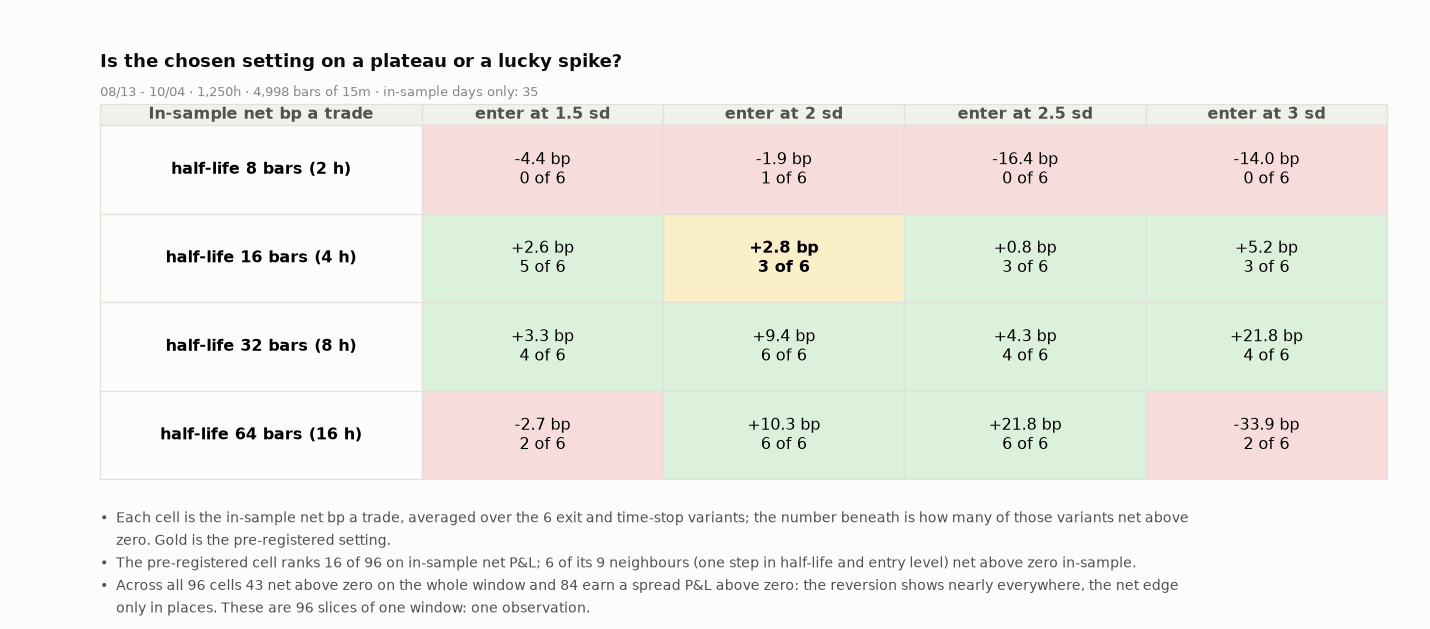

In [20]:
# ---- is the setting on a plateau: the in-sample net bp per trade, averaged over exit level and time stop (the six variants of each cell) ----
GRID_DF, gp_, gt_ = SH.run_grid(BARS, PARAM_GRID, COSTS, FXA, FYA, T_SPLIT, CAPITAL, stop=Z_STOP)
VER["passed"] += gp_; VER["total"] += gt_; VER["books"] += len(GRID_DF)
assert gp_ == gt_, "a grid run failed its checks"
import itertools
for hl_, zi_, zo_, mh_ in itertools.product(PARAM_GRID["half_life"], PARAM_GRID["z_in"], PARAM_GRID["z_out"], PARAM_GRID["max_hold"]):
    TRIALS.add((STEP_MS, hl_, zi_, zo_, Z_STOP, mh_, 0.0, False))
G = GRID_DF
pt = G.groupby(["half_life", "z_in"]).agg(bp=("bp_is", "mean"), pos=("bp_is", lambda v: int((v > 0).sum())), n=("n_is", "mean")).reset_index()
primary = G[(G.half_life == HALF_LIFE) & (G.z_in == Z_IN) & (G.z_out == Z_OUT) & (G.max_hold == MAX_HOLD)].iloc[0]
rank_ = int((G["net_is"] > primary["net_is"]).sum()) + 1
nbrs = pt[(pt.half_life.isin([h for h in PARAM_GRID["half_life"] if abs(PARAM_GRID["half_life"].index(h) - PARAM_GRID["half_life"].index(HALF_LIFE)) <= 1])) &
          (pt.z_in.isin([z for z in PARAM_GRID["z_in"] if abs(PARAM_GRID["z_in"].index(z) - PARAM_GRID["z_in"].index(Z_IN)) <= 1]))]
nb_pos = int((nbrs["bp"] > 0).sum())
BUL = [f"Each cell is the in-sample net bp a trade, averaged over the {len(PARAM_GRID['z_out']) * len(PARAM_GRID['max_hold'])} exit and time-stop variants; the number beneath is how many of those variants net above zero. Gold is the pre-registered setting.",
       f"The pre-registered cell ranks {rank_} of {len(G)} on in-sample net P&L; {nb_pos} of its {len(nbrs)} neighbours (one step in half-life and entry level) net above zero in-sample.",
       f"Across all {len(G)} cells {int((G['net'] > 0).sum())} net above zero on the whole window and {int((G['gross'] > 0).sum())} earn a spread P&L above zero: the reversion shows nearly everywhere, the net edge only in places. These are {len(G)} slices of one window: one observation."]
HP_ = 4.2 + figstyle.nlines(BUL) * 0.205 + 0.5
fig = plt.figure(figsize=(13, HP_))
bm = figstyle.bullet_margin(fig, figstyle.nlines(BUL)) + 0.02
gs = fig.add_gridspec(1, 1, left=0.07, right=0.97, top=1 - 0.95 / HP_, bottom=bm)
axt = fig.add_subplot(gs[0]); axt.axis("off")
hl_ = list(PARAM_GRID["half_life"]); zl_ = list(PARAM_GRID["z_in"])
cells = []
for h_ in hl_:
    row = [f"half-life {h_} bars ({h_ * STEP_MS / HOUR:.0f} h)"]
    for z_ in zl_:
        r_ = pt[(pt.half_life == h_) & (pt.z_in == z_)].iloc[0]
        row.append(f"{r_['bp']:+.1f} bp\n{int(r_['pos'])} of {len(PARAM_GRID['z_out']) * len(PARAM_GRID['max_hold'])}")
    cells.append(row)
tb = figstyle.put_table(axt, cells, ["In-sample net bp a trade"] + [f"enter at {z_:g} sd" for z_ in zl_], size=10.5, first=0.25)
for i_, h_ in enumerate(hl_, 1):
    for j_, z_ in enumerate(zl_, 1):
        r_ = pt[(pt.half_life == h_) & (pt.z_in == z_)].iloc[0]
        figstyle.tint(tb, i_, j_, "green" if r_["bp"] > 0 else "rose")
        if h_ == HALF_LIFE and z_ == Z_IN:
            figstyle.gold(tb, i_, j_)
for (r_, c_), cell in tb.get_celld().items():
    if r_ > 0:
        cell.set_height(1.0 / (len(hl_) + 1))
ask(axt, "Is the chosen setting on a plateau or a lucky spike?", f"{WS} · in-sample days only: {DAYS_IS:.0f}")
figstyle.bullets(fig, BUL)
figstyle.show(fig, "fig:s4-plateau", FIGURES)

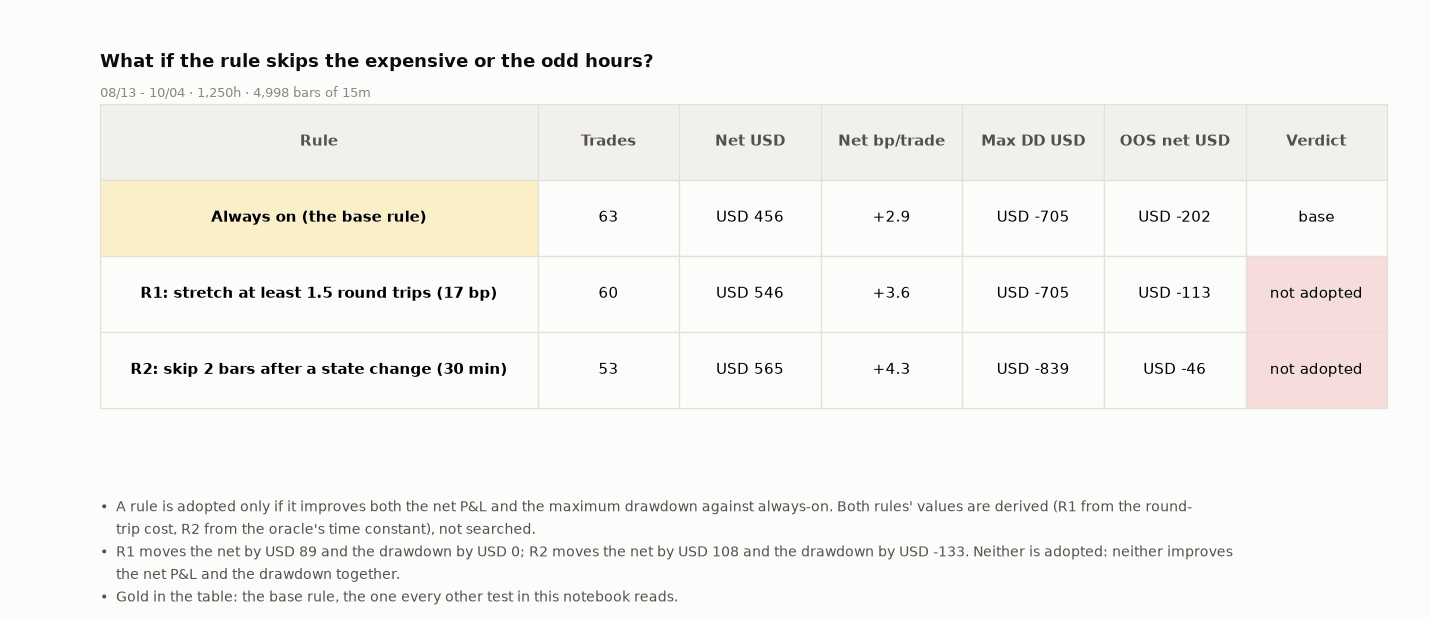

In [21]:
# ---- Test 2b: rules against always-on. A rule is adopted ONLY if it improves BOTH the net P&L and the maximum drawdown (no parameter search: both values come from costs and the oracle's time constant) ----
MIN_DEV_BP = MIN_DEV_MULT * RT_COST_BP
chg = np.r_[False, STATE[1:] != STATE[:-1]]
c_ = np.cumsum(chg.astype(int))
NO_ENTRY = (c_ - np.r_[np.zeros(B_BARS, int), c_[:-B_BARS]]) > 0                       # a state change in the last B_BARS bars
RULES_RUN = {"Always on (the base rule)": RES,
             f"R1: stretch at least {MIN_DEV_MULT:g} round trips ({MIN_DEV_BP:.0f} bp)": runv(BARS, SH.Spec(half_life=HALF_LIFE, z_in=Z_IN, z_out=Z_OUT, z_stop=Z_STOP, max_hold=MAX_HOLD, min_dev_bp=MIN_DEV_BP), COSTS, FXA, FYA),
             f"R2: skip {B_BARS} bars after a state change ({TAU_MIN} min)": runv(BARS, SPEC, COSTS, FXA, FYA, NO_ENTRY)}
def maxdd_usd(res_):
    e_ = CAPITAL + np.cumsum(res_["bar_net"])
    return float((e_ - np.maximum.accumulate(e_)).min())
RR = []
for nm, r_ in RULES_RUN.items():
    t_ = SH.trade_stats(r_["trades"], CLIP_USD, DAYS)
    RR.append({"name": nm, "n": t_["n"], "net": float(r_["bar_net"].sum()), "bp": t_["net_bp"], "dd": maxdd_usd(r_), "oos": float(r_["bar_net"][~M_IS].sum())})
for r_ in RR[1:]:
    r_["adopt"] = bool(r_["net"] > RR[0]["net"] and r_["dd"] > RR[0]["dd"])
G_RULE_ADOPTED = [r_["name"] for r_ in RR[1:] if r_["adopt"]]
BUL = ["A rule is adopted only if it improves both the net P&L and the maximum drawdown against always-on. Both rules' values are derived (R1 from the round-trip cost, R2 from the oracle's time constant), not searched.",
       " ".join(f"{r_['name'].split(':')[0]} moves the net by {usd(r_['net'] - RR[0]['net'])} and the drawdown by {usd(r_['dd'] - RR[0]['dd'])}" + ("." if i_ == len(RR) - 2 else ";") for i_, r_ in enumerate(RR[1:])) + " "
       + (f"Adopted: {'; '.join(G_RULE_ADOPTED)}." if G_RULE_ADOPTED else "Neither is adopted: neither improves the net P&L and the drawdown together."),
       "Gold in the table: the base rule, the one every other test in this notebook reads."]
fig, gs, top = mkfig(3.6, BUL)
axt = fig.add_subplot(gs[0]); axt.axis("off")
cells = [[r_["name"], f"{r_['n']}", usd(r_["net"]), f"{r_['bp']:+.1f}", usd(r_["dd"]), usd(r_["oos"]), "base" if i_ == 0 else ("ADOPT" if r_["adopt"] else "not adopted")] for i_, r_ in enumerate(RR)]
tb = figstyle.put_table(axt, cells, ["Rule", "Trades", "Net USD", "Net bp/trade", "Max DD USD", "OOS net USD", "Verdict"], size=9.5, first=0.34)
figstyle.gold(tb, 1, 0)
for i_, r_ in enumerate(RR[1:], 2):
    figstyle.tint(tb, i_, 6, "green" if r_["adopt"] else "rose")
ask(axt, "What if the rule skips the expensive or the odd hours?", WS)
figstyle.bullets(fig, BUL)
figstyle.show(fig, "fig:s4-rules", FIGURES)

pulling through fundplat.data.handle: xyz:SKHX, xyz:SKHY 1h candles 2026-07-11 00:00 -> 2026-10-04 10:00, and hourly funding from 2026-07-11 00:00


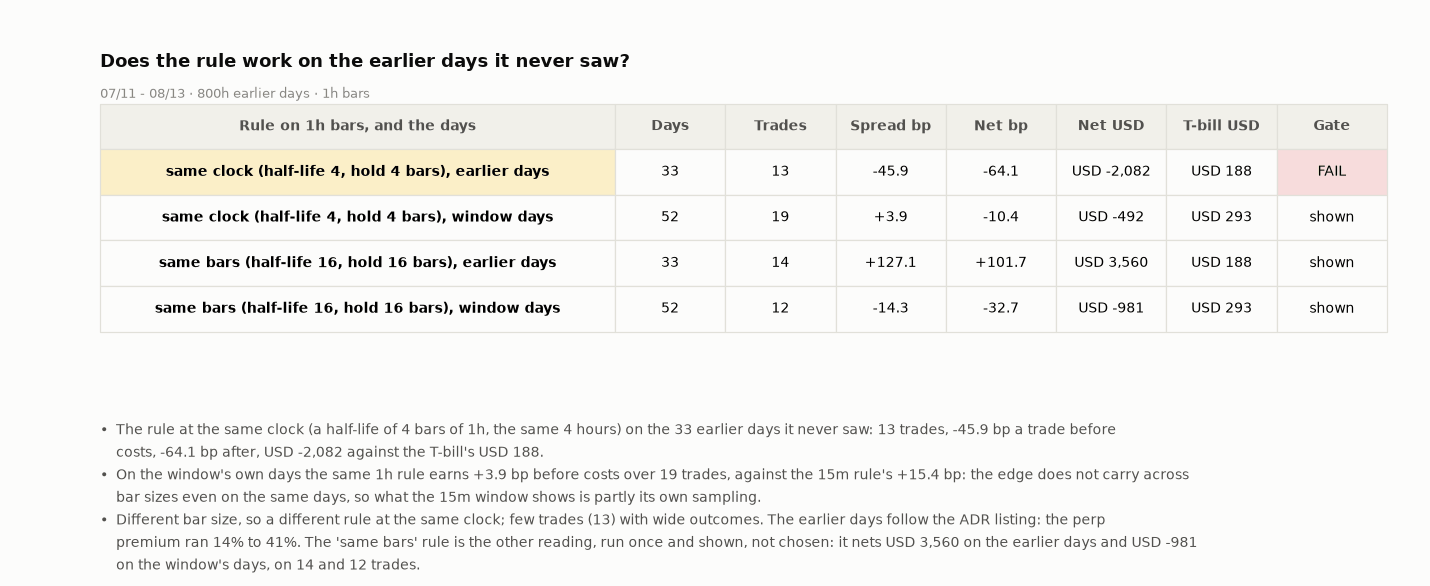

In [22]:
# ---- Test 1c: the earlier days. The same rule, on 1h bars, from the first full day after the ADR conversion to the start of the 15m window: days it has never seen ----
print(f"pulling through fundplat.data.handle: {COIN_A}, {COIN_B} {BAR_E} candles {EARLY_START} -> {END_DATE}, and hourly funding from {EARLY_START}")
BARS_E, _, _ = pair_bars(BAR_E, T_EARLY, T_END, STEP_E_MS)
FXE, FYE = funding_of(COIN_A, T_EARLY, T1), funding_of(COIN_B, T_EARLY, T1)
FXEA, FYEA = SH.align_funding(BARS_E["t"], FXE), SH.align_funding(BARS_E["t"], FYE)
TE0 = int(BARS_E["t"][0])
DAYS_E, DAYS_W1 = (T0 - TE0) / DAY, (T1 - T0) / DAY
HOURS_E = (T0 - TE0) / HOUR
PREM_E = (np.exp(SH.log_spread(BARS_E["cx"], BARS_E["cy"])[BARS_E["t"] < T0]) - 1) * 100
f_ = STEP_MS / STEP_E_MS                                          # 15m bars per 1h bar: 0.25
EARLY = {}
for lab, spec_e in (("same clock", SH.Spec(half_life=int(round(HALF_LIFE * f_)), z_in=Z_IN, z_out=Z_OUT, z_stop=Z_STOP, max_hold=int(round(MAX_HOLD * f_)))),
                    ("same bars", SH.Spec(half_life=HALF_LIFE, z_in=Z_IN, z_out=Z_OUT, z_stop=Z_STOP, max_hold=MAX_HOLD))):
    r_e = runv(BARS_E, spec_e, COSTS, FXEA, FYEA, fd=(FXE, FYE))
    tr_e = r_e["trades"]
    for wlab, sub, d_ in (("earlier days", tr_e[tr_e["entry_t"] < T0], DAYS_E), ("window days", tr_e[tr_e["entry_t"] >= T0], DAYS_W1)):
        t_e = SH.trade_stats(sub, CLIP_USD, d_)
        EARLY[(lab, wlab)] = {"spec": spec_e, "days": d_, "n": t_e["n"], "gross": t_e.get("gross_bp", float("nan")), "net_bp": t_e.get("net_bp", float("nan")), "net": t_e.get("net_usd", 0.0), "hur": SH.hurdle_usd(CAPITAL, HURDLE, d_)}
K_ = ("same clock", "earlier days")
G_EARLY = EARLY[K_]["net"] > EARLY[K_]["hur"]
w_ = EARLY[("same clock", "window days")]
BUL = [f"The rule at the same clock (a half-life of {EARLY[K_]['spec'].half_life} bars of {BAR_E}, the same {EARLY[K_]['spec'].half_life * STEP_E_MS / HOUR:.0f} hours) on the {DAYS_E:.0f} earlier days it never saw: {EARLY[K_]['n']} trades, {EARLY[K_]['gross']:+.1f} bp a trade before costs, {EARLY[K_]['net_bp']:+.1f} bp after, {usd(EARLY[K_]['net'])} against the T-bill's {usd(EARLY[K_]['hur'])}.",
       f"On the window's own days the same {BAR_E} rule earns {w_['gross']:+.1f} bp before costs over {w_['n']} trades, against the {BAR} rule's {TS['gross_bp']:+.1f} bp: the edge does not carry across bar sizes even on the same days, so what the {BAR} window shows is partly its own sampling.",
       f"Different bar size, so a different rule at the same clock; few trades ({EARLY[K_]['n']}) with wide outcomes. The earlier days follow the ADR listing: the perp premium ran {PREM_E.min():.0f}% to {PREM_E.max():.0f}%. The 'same bars' rule is the other reading, run once and shown, not chosen: it nets {usd(EARLY[("same bars", "earlier days")]['net'])} on the earlier days and {usd(EARLY[("same bars", "window days")]['net'])} on the window's days, on {EARLY[("same bars", "earlier days")]['n']} and {EARLY[("same bars", "window days")]['n']} trades."]
fig, gs, top = mkfig(2.9, BUL)
axt = fig.add_subplot(gs[0]); axt.axis("off")
cells = []
for (lab, wlab), r_ in EARLY.items():
    cells.append([f"{lab} (half-life {r_['spec'].half_life}, hold {r_['spec'].max_hold} bars), {wlab}", f"{r_['days']:.0f}", f"{r_['n']}", f"{r_['gross']:+.1f}", f"{r_['net_bp']:+.1f}", usd(r_["net"]), usd(r_["hur"]),
                  ("PASS" if r_["net"] > r_["hur"] else "FAIL") if (lab, wlab) == K_ else "shown"])
tb = figstyle.put_table(axt, cells, ["Rule on 1h bars, and the days", "Days", "Trades", "Spread bp", "Net bp", "Net USD", "T-bill USD", "Gate"], size=9, first=0.4)
figstyle.gold(tb, 1, 0)
for i_, c_ in enumerate(cells, 1):
    if c_[7] in ("PASS", "FAIL"):
        figstyle.tint(tb, i_, 7, "green" if c_[7] == "PASS" else "rose")
ask(axt, "Does the rule work on the earlier days it never saw?", f"{iso_(TE0)[5:10].replace('-', '/')} - {iso_(T0)[5:10].replace('-', '/')} \u00b7 {HOURS_E:,.0f}h earlier days \u00b7 {BAR_E} bars")
figstyle.bullets(fig, BUL)
figstyle.show(fig, "fig:s4-earlier", FIGURES)

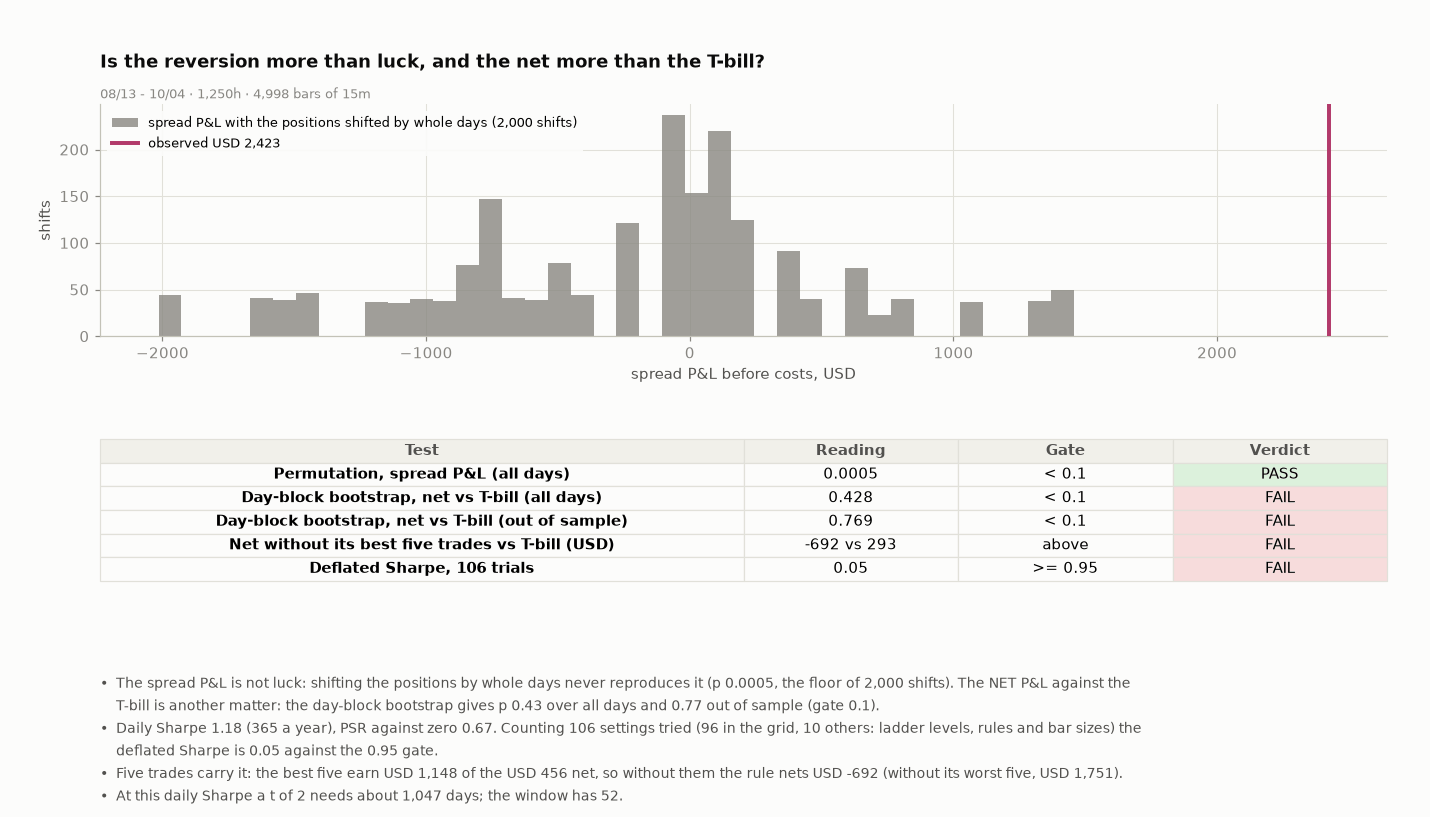

In [23]:
# ---- Test 1b: beyond luck, against the T-bill, and given the number of settings tried ----
N_TRIALS = len(TRIALS)                                            # every distinct setting run above: grid cells, ladder levels, rules, bar sizes
SR_VAR = float(np.var(GRID_DF["sr_day"], ddof=1))
RNG = np.random.default_rng(SEED)
hd_ = CAPITAL * HURDLE / 365.0
x_all = list(DAILY.to_numpy() - hd_)
BOOT_ALL = ST.bootstrap_p_one_sided(x_all, BOOT_BLOCK_D, NSHUF, RNG)
d_oos = DAILY[DAILY.index >= pd.Timestamp(T_SPLIT, unit="ms", tz="UTC")]
BOOT_OOS = ST.bootstrap_p_one_sided(list(d_oos.to_numpy() - hd_), BOOT_BLOCK_D, NSHUF, RNG)
PSR0 = ST.psr(list(dr_))
DSR_ = ST.dsr(list(dr_), N_TRIALS, SR_VAR)
SHARPE_D = ST.sharpe(list(dr_), 365)
need_days = (2.0 / (np.mean(dr_) / np.std(dr_, ddof=1))) ** 2 if np.mean(dr_) > 0 else float("inf")
G_BOOT, G_DSR = BOOT_ALL["p"] < P_GATE, DSR_ >= DSR_GATE
TOP5_USD = float(TR["net"].nlargest(5).sum()); NET_NO_TOP5 = NET_USD - TOP5_USD; NET_NO_BOT5 = NET_USD - float(TR["net"].nsmallest(5).sum())
G_TOP5 = NET_NO_TOP5 > HURDLE_USD_ALL
BUL = [f"The spread P&L is not luck: shifting the positions by whole days never reproduces it (p {PERM['p']:.4f}, the floor of {NSHUF:,} shifts). The NET P&L against the T-bill is another matter: the day-block bootstrap gives p {BOOT_ALL['p']:.2f} over all days and {BOOT_OOS['p']:.2f} out of sample (gate {P_GATE:g}).",
       f"Daily Sharpe {SHARPE_D:.2f} (365 a year), PSR against zero {PSR0:.2f}. Counting {N_TRIALS} settings tried ({len(GRID_DF)} in the grid, {N_TRIALS - len(GRID_DF)} others: ladder levels, rules and bar sizes) the deflated Sharpe is {DSR_:.2f} against the {DSR_GATE:g} gate.",
       f"Five trades carry it: the best five earn {usd(TOP5_USD)} of the {usd(NET_USD)} net, so without them the rule nets {usd(NET_NO_TOP5)} (without its worst five, {usd(NET_NO_BOT5)}).",
       (f"At this daily Sharpe a t of 2 needs about {need_days:,.0f} days; the window has {DAYS:.0f}." if np.isfinite(need_days) else f"The mean daily P&L is not above zero, so no sample length confirms it; the window has {DAYS:.0f} days.")]
fig, gs, top = mkfig(5.2, BUL, nrows=2, ncols=1, ratios=(2.3, 1.4), hspace=0.55)
ax, axt = fig.add_subplot(gs[0]), fig.add_subplot(gs[1]); axt.axis("off")
ax.hist(PERM["null"], bins=40, color=C_COST, alpha=0.8, zorder=2, label=f"spread P&L with the positions shifted by whole days ({NSHUF:,} shifts)")
ax.axvline(PERM["observed"], color=C_PREM_DK, linewidth=2.6, zorder=4, label=f"observed {usd(PERM['observed'])}")
ax.set_xlabel("spread P&L before costs, USD"); ax.set_ylabel("shifts"); ax.legend(loc="upper left", fontsize=8.5, **LEG)
ask(ax, "Is the reversion more than luck, and the net more than the T-bill?", WS)
cells = [["Permutation, spread P&L (all days)", f"{PERM['p']:.4f}", f"< {P_GATE:g}", "PASS" if G_PERM else "FAIL"],
         ["Day-block bootstrap, net vs T-bill (all days)", f"{BOOT_ALL['p']:.3f}", f"< {P_GATE:g}", "PASS" if G_BOOT else "FAIL"],
         ["Day-block bootstrap, net vs T-bill (out of sample)", f"{BOOT_OOS['p']:.3f}", f"< {P_GATE:g}", "PASS" if BOOT_OOS["p"] < P_GATE else "FAIL"],
         ["Net without its best five trades vs T-bill (USD)", f"{NET_NO_TOP5:,.0f} vs {HURDLE_USD_ALL:,.0f}", "above", "PASS" if G_TOP5 else "FAIL"],
         [f"Deflated Sharpe, {N_TRIALS} trials", f"{DSR_:.2f}", f">= {DSR_GATE:g}", "PASS" if G_DSR else "FAIL"]]
tb = figstyle.put_table(axt, cells, ["Test", "Reading", "Gate", "Verdict"], size=10, first=0.5)
for r_ in range(1, 6):
    figstyle.tint(tb, r_, 3, "green" if cells[r_ - 1][3] == "PASS" else "rose")
figstyle.bullets(fig, BUL)
figstyle.show(fig, "fig:s4-luck", FIGURES)

In [24]:
# ---- determinism: the pinned window must give the 2026-10-04 build's headline readings and verify() counts BEFORE anything new is drawn. A re-run on the same pinned data is a determinism check, not a replication. ----
HEAD_NOW = {"n_trades": TS["n"], "net_usd": NET_USD, "gross_bp": TS["gross_bp"], "net_bp": TS["net_bp"], "sharpe": SHARPE_D, "psr": PSR0, "dsr": DSR_, "boot_p": BOOT_ALL["p"], "perm_p": PERM["p"], "trials": N_TRIALS, "be": BE_ALL}
HEAD_DIFF = {k_: abs(HEAD_NOW[k_] - PINNED_HEAD[k_]) for k_ in HEAD_NOW}
assert all(v_ < 1e-6 for v_ in HEAD_DIFF.values()) and (VER["passed"], VER["total"], VER["books"]) == PINNED_HEAD["verify"], (HEAD_DIFF, VER)
_planted = dict(HEAD_NOW, net_usd=HEAD_NOW["net_usd"] + 1.0)                       # break it once on purpose: one USD of drift must turn the comparison red
assert not all(abs(_planted[k_] - PINNED_HEAD[k_]) < 1e-6 for k_ in HEAD_NOW), "the determinism check cannot see a one-dollar change"
print(f"determinism: {len(HEAD_NOW)} headline readings equal the 2026-10-04 build's (largest difference {max(HEAD_DIFF.values()):.1e}); verify() {VER['passed']}/{VER['total']} over {VER['books']} runs, equal. A planted one-USD drift turns the check red. "
      "The window is pinned, so this re-run reads the same bars: it is not a second sample.")

determinism: 11 headline readings equal the 2026-10-04 build's (largest difference 0.0e+00); verify() 1134/1134 over 121 runs, equal. A planted one-USD drift turns the check red. The window is pinned, so this re-run reads the same bars: it is not a second sample.


In [25]:
# ---- multiple testing: the trial ledger behind the deflated Sharpe, counted from the runs the notebook made ----
_grid = {(STEP_MS, h_, z_, o_, Z_STOP, m_, 0.0, False) for h_, z_, o_, m_ in itertools.product(PARAM_GRID["half_life"], PARAM_GRID["z_in"], PARAM_GRID["z_out"], PARAM_GRID["max_hold"])}
_rules = {t_ for t_ in TRIALS if t_[6] > 0 or t_[7]}
_rest = TRIALS - _rules
LEDGER = [("Grid cells on 15m bars (half-life, entry level, exit level, time stop)", len(_rest & _grid)),
          ("Entry levels of the frequency ladder that are not grid cells", len({t_ for t_ in _rest if t_[0] == STEP_MS and t_ not in _grid})),
          ("Reruns on 5m bars (the same days as the out-of-sample)", len({t_ for t_ in _rest if t_[0] == STEP5_MS})),
          ("Reruns on 1h bars (the earlier days)", len({t_ for t_ in _rest if t_[0] == STEP_E_MS})),
          ("Rules R1 and R2 (a cost-aware entry, a skip after a state change)", len(_rules))]
assert sum(n_ for _, n_ in LEDGER) == N_TRIALS == len(TRIALS) == PINNED_HEAD["trials"], (LEDGER, N_TRIALS)
COST_VARIANTS = len([s_ for s_ in SLIP_SWEEP if s_ != SLIP_BPS]) + len([d_ for d_ in DELAYS if d_ != 0]) + 1          # slippage sweep, late fills, the maker floor: the same signal at another cost
DSR_ALT = {"as gated": (N_TRIALS, DSR_), "grid cells only": (LEDGER[0][1], ST.dsr(list(dr_), LEDGER[0][1], SR_VAR)), "with the cost and delay variants": (N_TRIALS + COST_VARIANTS, ST.dsr(list(dr_), N_TRIALS + COST_VARIANTS, SR_VAR))}
EMAX_ANN = ST.expected_max_sr(N_TRIALS, SR_VAR) * math.sqrt(365)
display(Markdown("| Trials counted in the deflated Sharpe | Runs |\n|---|---|\n" + "\n".join(f"| {a} | {b} |" for a, b in LEDGER) + f"\n| **Total** | **{N_TRIALS}** |"))
display(Markdown(f"The count equals the previous build's {PINNED_HEAD['trials']} and the sum of the lines above. Not counted: {COST_VARIANTS} runs of the same signal at another cost (the slippage sweep, the late fills, the maker floor), because they change the price paid and not the signal. "
                 f"The deflated Sharpe is {DSR_ALT['as gated'][1]:.2f} as gated, {DSR_ALT['grid cells only'][1]:.2f} counting the {DSR_ALT['grid cells only'][0]} grid cells alone and {DSR_ALT['with the cost and delay variants'][1]:.2f} counting the cost variants too ({DSR_ALT['with the cost and delay variants'][0]} runs): no honest count moves it near the {DSR_GATE:g} gate. "
                 f"The best of {N_TRIALS} zero-skill settings is expected to show an annual Sharpe of {EMAX_ANN:.2f} on the grid's own spread of results, against this rule's {SHARPE_D:.2f}. "
                 "The count is a floor: the ideas dropped before the first run (the fade itself, the 15m bar) are on no ledger [U]. The grid, the ladder, the rules and the splits are one window re-sliced, so the trials are not independent either."))

| Trials counted in the deflated Sharpe | Runs |
|---|---|
| Grid cells on 15m bars (half-life, entry level, exit level, time stop) | 96 |
| Entry levels of the frequency ladder that are not grid cells | 3 |
| Reruns on 5m bars (the same days as the out-of-sample) | 3 |
| Reruns on 1h bars (the earlier days) | 2 |
| Rules R1 and R2 (a cost-aware entry, a skip after a state change) | 2 |
| **Total** | **106** |

The count equals the previous build's 106 and the sum of the lines above. Not counted: 9 runs of the same signal at another cost (the slippage sweep, the late fills, the maker floor), because they change the price paid and not the signal. The deflated Sharpe is 0.05 as gated, 0.05 counting the 96 grid cells alone and 0.05 counting the cost variants too (115 runs): no honest count moves it near the 0.95 gate. The best of 106 zero-skill settings is expected to show an annual Sharpe of 5.48 on the grid's own spread of results, against this rule's 1.18. The count is a floor: the ideas dropped before the first run (the fade itself, the 15m bar) are on no ledger [U]. The grid, the ladder, the rules and the splits are one window re-sliced, so the trials are not independent either.

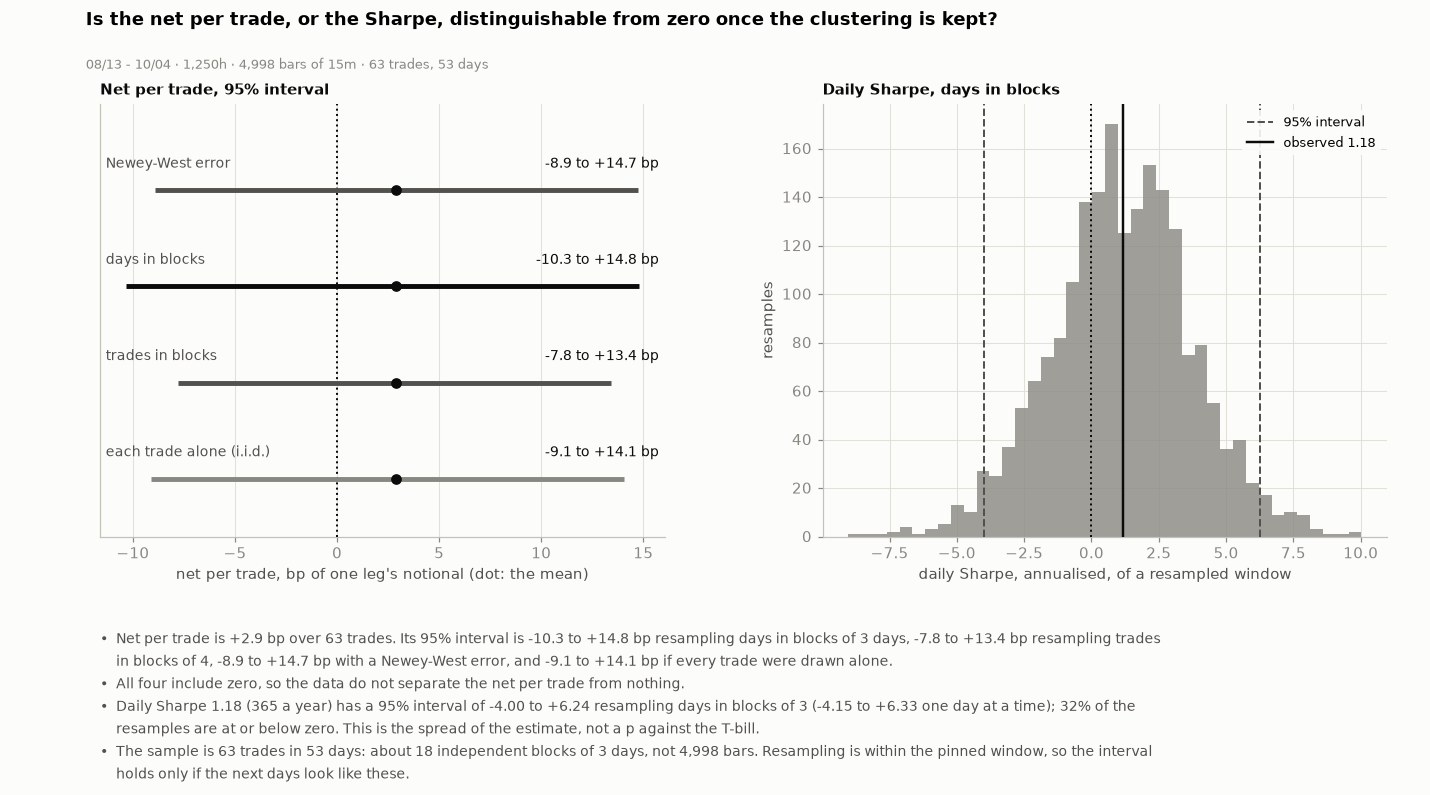

In [26]:
# ---- an interval on the net per trade and on the daily Sharpe that keeps the clustering in time (blocks, not i.i.d. draws) ----
from fundplat.quant.crypto.backtest.carry import xvf_hf as XH


def boot_ci(x, mean_block, seed, n=NSHUF):
    """95% percentile interval of the mean of x, a stationary bootstrap with this mean block (1 is the i.i.d. draw); the resampling is fundplat.quant.core.stats'."""
    m = np.array(ST.stationary_bootstrap_sums(list(x), mean_block, n, seed)) / len(x)
    return float(ST.percentile(m, 2.5)), float(ST.percentile(m, 97.5)), m


X_BP = TR["net"].to_numpy() / CLIP_USD * 1e4
X_N = len(X_BP)
X_L_T = max(1, int(round(BOOT_BLOCK_D * TS["per_day"])))                       # the day block expressed in trades
X_MEAN = float(X_BP.mean())
CI_IID, CI_TBLK = boot_ci(X_BP, 1, CI_SEED), boot_ci(X_BP, X_L_T, CI_SEED)
CI_DAYB = XH.mean_ci([{"t_exit": int(r_.exit_t), "net_bps": float(b_), "hold_h": float(r_.bars * STEP_MS / HOUR)} for r_, b_ in zip(TR.itertuples(), X_BP)], n=NSHUF, seed=CI_SEED, block_days=BOOT_BLOCK_D)
HAC = ST.newey_west(list(X_BP))
X_CI_LO, X_CI_HI = float(CI_DAYB[0]), float(CI_DAYB[1])
# the Sharpe: the resampled sums of x and of x squared must come from the SAME resampled indices; one seed gives one set of draws whatever x is. Proven in the function, and broken once on purpose.
X_T = len(dr_)
def sr_boot(mean_block, seed):
    s1 = np.array(ST.stationary_bootstrap_sums(list(dr_), mean_block, NSHUF, seed))
    s2 = np.array(ST.stationary_bootstrap_sums([v_ * v_ for v_ in dr_], mean_block, NSHUF, seed))
    sh = np.array(ST.stationary_bootstrap_sums([v_ + 1.0 for v_ in dr_], mean_block, NSHUF, seed))
    other = np.array(ST.stationary_bootstrap_sums([v_ + 1.0 for v_ in dr_], mean_block, NSHUF, seed + 1))
    assert np.allclose(sh - s1, X_T), "the paired resamples do not share their indices"
    assert not np.allclose(other - s1, X_T), "a different seed must break the pairing, and it did not"
    m_ = s1 / X_T
    v_ = (s2 / X_T - m_ ** 2) * X_T / (X_T - 1)
    return m_ / np.sqrt(v_) * math.sqrt(365)
SR_BLK, SR_IID = sr_boot(BOOT_BLOCK_D, CI_SEED), sr_boot(1, CI_SEED)
SR_PT = float(np.mean(dr_) / np.std(dr_, ddof=1) * math.sqrt(365))
assert abs(SR_PT - SHARPE_D) < 1e-9, (SR_PT, SHARPE_D)
SR_LO, SR_HI = float(ST.percentile(SR_BLK, 2.5)), float(ST.percentile(SR_BLK, 97.5))
SR_IID_LO, SR_IID_HI = float(ST.percentile(SR_IID, 2.5)), float(ST.percentile(SR_IID, 97.5))
SR_BELOW0 = float((SR_BLK <= 0).mean())
X_BLOCKS = int(math.ceil(X_T / BOOT_BLOCK_D))
X_INTS = ((CI_DAYB[0], CI_DAYB[1]), (CI_TBLK[0], CI_TBLK[1]), (HAC["ci_low"], HAC["ci_high"]), (CI_IID[0], CI_IID[1]))
BUL = [f"Net per trade is {X_MEAN:+.1f} bp over {X_N} trades. Its 95% interval is {X_CI_LO:+.1f} to {X_CI_HI:+.1f} bp resampling days in blocks of {BOOT_BLOCK_D} days, {CI_TBLK[0]:+.1f} to {CI_TBLK[1]:+.1f} bp resampling trades in blocks of {X_L_T}, "
       f"{HAC['ci_low']:+.1f} to {HAC['ci_high']:+.1f} bp with a Newey-West error, and {CI_IID[0]:+.1f} to {CI_IID[1]:+.1f} bp if every trade were drawn alone.",
       ("All four include zero, so the data do not separate the net per trade from nothing." if all(lo_ <= 0 <= hi_ for lo_, hi_ in X_INTS) else
        ("None of the four includes zero." if all(not (lo_ <= 0 <= hi_) for lo_, hi_ in X_INTS) else "The four intervals disagree on zero: the block ones are the ones to read.")),
       f"Daily Sharpe {SR_PT:.2f} (365 a year) has a 95% interval of {SR_LO:+.2f} to {SR_HI:+.2f} resampling days in blocks of {BOOT_BLOCK_D} ({SR_IID_LO:+.2f} to {SR_IID_HI:+.2f} one day at a time); {SR_BELOW0 * 100:.0f}% of the resamples are at or below zero. This is the spread of the estimate, not a p against the T-bill.",
       f"The sample is {X_N} trades in {X_T} days: about {X_BLOCKS} independent blocks of {BOOT_BLOCK_D} days, not {N_BARS:,} bars. Resampling is within the pinned window, so the interval holds only if the next days look like these."]
fig, gs, top = mkfig(4.8, BUL, nrows=1, ncols=2, wspace=0.28)
ax1, ax2 = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1])
rows_ = [("each trade alone (i.i.d.)", CI_IID[0], CI_IID[1], MUTED), ("trades in blocks", CI_TBLK[0], CI_TBLK[1], INK2), ("days in blocks", X_CI_LO, X_CI_HI, INK), ("Newey-West error", HAC["ci_low"], HAC["ci_high"], INK2)]
for i_, (lab_, lo_, hi_, col_) in enumerate(rows_):
    ax1.hlines(i_, lo_, hi_, color=col_, linewidth=3.2, zorder=4)
    ax1.text(0.01, i_ + 0.2, lab_, transform=ax1.get_yaxis_transform(), fontsize=9, color=INK2, va="bottom", ha="left")
    ax1.text(0.99, i_ + 0.2, f"{lo_:+.1f} to {hi_:+.1f} bp", transform=ax1.get_yaxis_transform(), fontsize=9, color=INK, va="bottom", ha="right")
ax1.scatter([X_MEAN] * len(rows_), range(len(rows_)), s=36, color=INK, zorder=6)
ax1.axvline(0, color=INK, linewidth=1.3, linestyle=":", zorder=3)
ax1.set_yticks([]); ax1.set_ylim(-0.6, len(rows_) - 0.1); ax1.grid(axis="y", visible=False)
ax1.set_xlabel("net per trade, bp of one leg's notional (dot: the mean)"); ax1.set_title("Net per trade, 95% interval", fontsize=10, loc="left")
ax2.hist(SR_BLK, bins=40, color=C_COST, alpha=0.8, zorder=2)
ax2.axvline(SR_LO, color=INK2, linewidth=1.3, linestyle="--", zorder=4, label="95% interval"); ax2.axvline(SR_HI, color=INK2, linewidth=1.3, linestyle="--", zorder=4)
ax2.axvline(SR_PT, color=INK, linewidth=1.6, zorder=4, label=f"observed {SR_PT:.2f}")
ax2.axvline(0, color=INK, linewidth=1.3, linestyle=":", zorder=3)
ax2.set_xlabel("daily Sharpe, annualised, of a resampled window"); ax2.set_ylabel("resamples"); ax2.legend(loc="upper right", fontsize=8.5, **LEG); ax2.set_title("Daily Sharpe, days in blocks", fontsize=10, loc="left")
fig_ask(fig, "Is the net per trade, or the Sharpe, distinguishable from zero once the clustering is kept?", WS + f" · {X_N} trades, {X_T} days", top)
figstyle.bullets(fig, BUL)
figstyle.show(fig, "fig:s4-ci", FIGURES)

In [27]:
# ---- every p and interval with the sample behind it, and the sample-size disclosure ----
X_ACTIVE = int((DAILY != 0).sum())
SAMPLE_ROWS = [
    ("Permutation p, spread P&L before costs (S3)", f"{PERM['p']:.4f}", f"positions shifted by whole days, {NSHUF:,} shifts (p floor {1 / (NSHUF + 1):.4f})", f"{TS['n']} trades, {len(DAILY)} days"),
    ("Day-block bootstrap p, net vs T-bill, all days", f"{BOOT_ALL['p']:.2f}", f"days in blocks of {BOOT_BLOCK_D}, {NSHUF:,} draws", f"{len(x_all)} days, about {int(math.ceil(len(x_all) / BOOT_BLOCK_D))} blocks"),
    ("Day-block bootstrap p, net vs T-bill, out of sample", f"{BOOT_OOS['p']:.2f}", f"days in blocks of {BOOT_BLOCK_D}, {NSHUF:,} draws", f"{len(d_oos)} days, about {int(math.ceil(len(d_oos) / BOOT_BLOCK_D))} blocks, {TS_OOS['n']} trades"),
    ("Newey-West p, mean daily P&L (S5)", f"{ST.newey_west(list(dr_))['p']:.2f}", f"the daily series, {ST.newey_west(list(dr_))['lags']} lags", f"{len(dr_)} days"),
    ("95% interval, net per trade (this section)", f"{X_CI_LO:+.1f} to {X_CI_HI:+.1f} bp", f"days in blocks of {BOOT_BLOCK_D}, {NSHUF:,} draws", f"{X_N} trades, {X_ACTIVE} days with a trade"),
    ("95% interval, daily Sharpe (this section)", f"{SR_LO:+.2f} to {SR_HI:+.2f}", f"days in blocks of {BOOT_BLOCK_D}, {NSHUF:,} draws", f"{X_T} days, about {X_BLOCKS} blocks"),
    ("Probabilistic Sharpe vs zero", f"{PSR0:.2f}", "an i.i.d. formula with the days' skew and kurtosis", f"{X_T} days"),
    (f"Deflated Sharpe, {N_TRIALS} trials", f"{DSR_:.2f}", "the same formula against the best of the trials", f"{X_T} days, {N_TRIALS} settings of one window"),
]
display(Markdown("| Test | Reading | What is resampled | Sample behind it |\n|---|---|---|---|\n" + "\n".join(f"| {a} | {b} | {c} | {d} |" for a, b, c, d in SAMPLE_ROWS)))
X_SD = float(X_BP.std(ddof=1))
display(Markdown(f"**Sample size.** {TS['n']} trades in {len(dr_)} daily observations, {X_ACTIVE} of them with a trade: the independent bets number about {X_BLOCKS} blocks, and the trades inside a day share one regime. "
                 + (f"A t of 2 on the mean trade needs about {(2 * X_SD / X_MEAN) ** 2:,.0f} trades at this spread of outcomes ({X_SD:.0f} bp sd), and a t of 2 on the daily mean needs about {need_days:,.0f} days; the window has {TS['n']} and {DAYS:.0f}. " if X_MEAN > 0 and np.isfinite(need_days) else "The mean is not above zero, so no sample length confirms it. ")
                 + "A window of this size can reject a rule and cannot confirm one. Not computed here, for want of a function in `fundplat`: the minimum track-record length, a drawdown bootstrap and a Monte Carlo of the trade sequence (board items B-0491, B-0492, B-0493), and a library call for the Sharpe interval, which here rests on a same-seed pairing the cell asserts (B-0494); the correlation with the fund's other books (B-0496) and an impact model (B-0497) are not in the study either."))

| Test | Reading | What is resampled | Sample behind it |
|---|---|---|---|
| Permutation p, spread P&L before costs (S3) | 0.0005 | positions shifted by whole days, 2,000 shifts (p floor 0.0005) | 63 trades, 53 days |
| Day-block bootstrap p, net vs T-bill, all days | 0.43 | days in blocks of 3, 2,000 draws | 53 days, about 18 blocks |
| Day-block bootstrap p, net vs T-bill, out of sample | 0.77 | days in blocks of 3, 2,000 draws | 18 days, about 6 blocks, 20 trades |
| Newey-West p, mean daily P&L (S5) | 0.67 | the daily series, 3 lags | 53 days |
| 95% interval, net per trade (this section) | -10.3 to +14.8 bp | days in blocks of 3, 2,000 draws | 63 trades, 42 days with a trade |
| 95% interval, daily Sharpe (this section) | -4.00 to +6.24 | days in blocks of 3, 2,000 draws | 53 days, about 18 blocks |
| Probabilistic Sharpe vs zero | 0.67 | an i.i.d. formula with the days' skew and kurtosis | 53 days |
| Deflated Sharpe, 106 trials | 0.05 | the same formula against the best of the trials | 53 days, 106 settings of one window |

**Sample size.** 63 trades in 53 daily observations, 42 of them with a trade: the independent bets number about 18 blocks, and the trades inside a day share one regime. A t of 2 on the mean trade needs about 1,152 trades at this spread of outcomes (49 bp sd), and a t of 2 on the daily mean needs about 1,047 days; the window has 63 and 52. A window of this size can reject a rule and cannot confirm one. Not computed here, for want of a function in `fundplat`: the minimum track-record length, a drawdown bootstrap and a Monte Carlo of the trade sequence (board items B-0491, B-0492, B-0493), and a library call for the Sharpe interval, which here rests on a same-seed pairing the cell asserts (B-0494); the correlation with the fund's other books (B-0496) and an impact model (B-0497) are not in the study either.

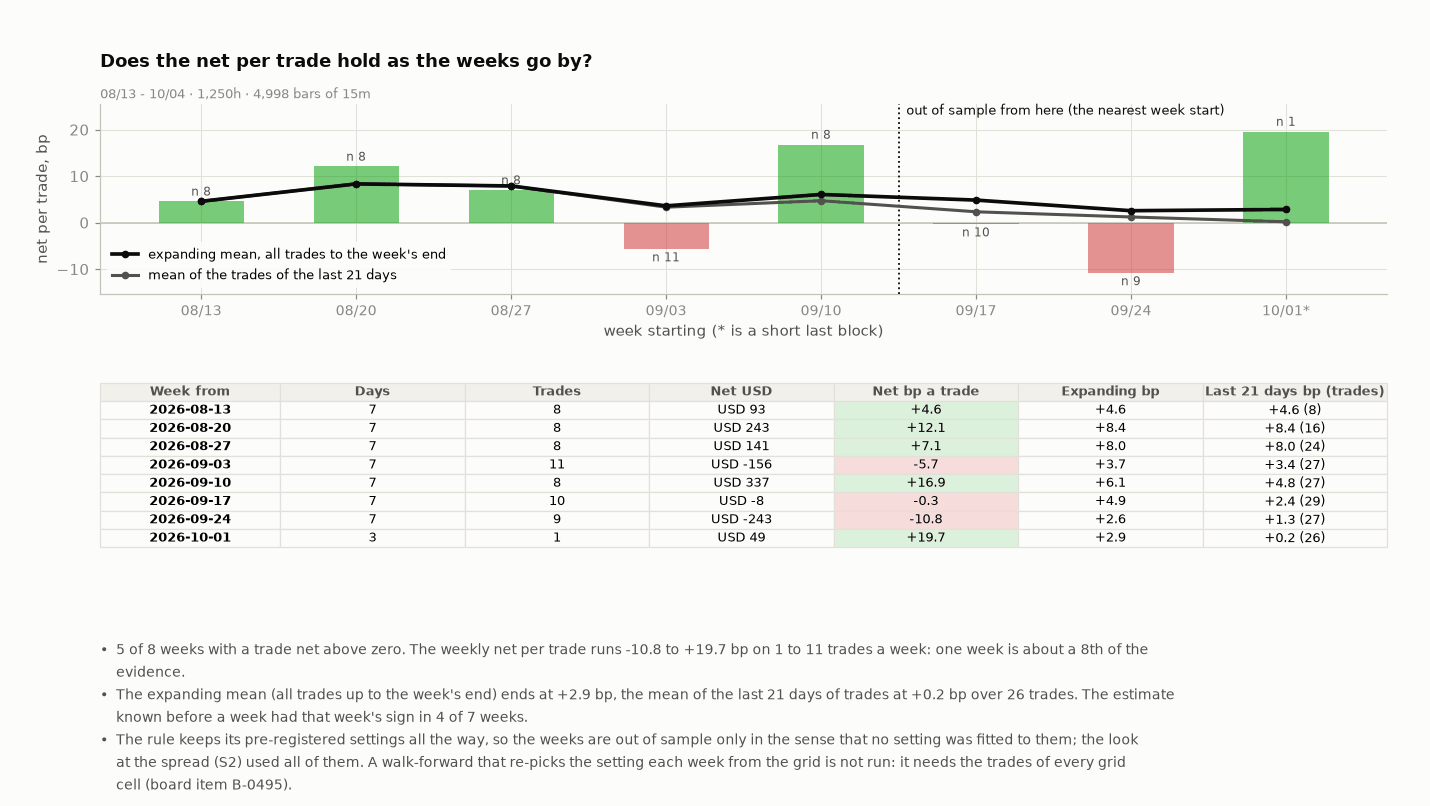

In [28]:
# ---- walk-forward by week: the net per trade as time moves on (the rule is fixed, so this is a time-ordered read, not a refit) ----
X_NWK = int(math.ceil(DAYS / WEEK_D))
X_ET = TR["entry_t"].to_numpy()
WF = []
for k_ in range(X_NWK):
    t_lo, t_hi = T0 + k_ * WEEK_D * DAY, min(T0 + (k_ + 1) * WEEK_D * DAY, T1)
    w_m = (X_ET >= t_lo) & (X_ET < t_hi)
    e_m = X_ET < t_hi
    r_m = (X_ET >= t_hi - WF_ROLL_DAYS * DAY) & (X_ET < t_hi)
    WF.append({"k": k_, "from": t_lo, "days": (t_hi - t_lo) / DAY, "n": int(w_m.sum()), "usd": float(TR["net"].to_numpy()[w_m].sum()), "bp": float(X_BP[w_m].mean()) if w_m.any() else float("nan"),
               "exp_n": int(e_m.sum()), "exp": float(X_BP[e_m].mean()) if e_m.any() else float("nan"), "roll_n": int(r_m.sum()), "roll": float(X_BP[r_m].mean()) if r_m.any() else float("nan")})
assert sum(w_["n"] for w_ in WF) == X_N and abs(sum(w_["usd"] for w_ in WF) - NET_USD) < 1e-6, "the weeks must tile the trades"
X_TRAIL, X_TRAIL_N = WF[-1]["roll"], WF[-1]["roll_n"]                             # the trailing read at the window's end
X_POSW = sum(1 for w_ in WF if w_["n"] and w_["bp"] > 0)
X_WKN = sum(1 for w_ in WF if w_["n"])
X_CALL = [(WF[k_ - 1]["exp"] > 0) == (WF[k_]["bp"] > 0) for k_ in range(1, X_NWK) if WF[k_]["n"] and WF[k_ - 1]["n"]]
X_WSPLIT = min(range(X_NWK), key=lambda k_: abs(WF[k_]["from"] - T_SPLIT))
BUL = [f"{X_POSW} of {X_WKN} weeks with a trade net above zero. The weekly net per trade runs {min(w_['bp'] for w_ in WF if w_['n']):+.1f} to {max(w_['bp'] for w_ in WF if w_['n']):+.1f} bp on {min(w_['n'] for w_ in WF if w_['n'])} to {max(w_['n'] for w_ in WF)} trades a week: one week is about a {X_NWK}th of the evidence.",
       f"The expanding mean (all trades up to the week's end) ends at {WF[-1]['exp']:+.1f} bp, the mean of the last {WF_ROLL_DAYS:g} days of trades at {X_TRAIL:+.1f} bp over {X_TRAIL_N} trades. The estimate known before a week had that week's sign in {sum(X_CALL)} of {len(X_CALL)} weeks.",
       "The rule keeps its pre-registered settings all the way, so the weeks are out of sample only in the sense that no setting was fitted to them; the look at the spread (S2) used all of them. A walk-forward that re-picks the setting each week from the grid is not run: it needs the trades of every grid cell (board item B-0495)."]
fig, gs, top = mkfig(4.9, BUL, nrows=2, ncols=1, ratios=(2.2, 1.9), hspace=0.5)
ax, axt = fig.add_subplot(gs[0]), fig.add_subplot(gs[1]); axt.axis("off")
xs_ = np.arange(X_NWK)
ax.bar(xs_, [0 if not w_["n"] else w_["bp"] for w_ in WF], color=[GOOD if w_["n"] and w_["bp"] > 0 else CRIT for w_ in WF], width=0.55, zorder=2, alpha=0.55)
ax.plot(xs_, [w_["exp"] for w_ in WF], color=INK, linewidth=2.4, marker="o", markersize=4, zorder=5, label="expanding mean, all trades to the week's end")
ax.plot(xs_, [w_["roll"] for w_ in WF], color=INK2, linewidth=2.0, marker="o", markersize=4, zorder=4, label=f"mean of the trades of the last {WF_ROLL_DAYS:g} days")
for i_, w_ in enumerate(WF):
    if w_["n"]:
        ax.text(i_, w_["bp"] + (0.6 if w_["bp"] >= 0 else -0.6), f"n {w_['n']}", ha="center", va="bottom" if w_["bp"] >= 0 else "top", fontsize=8, color=INK2)
ax.axhline(0, color=AXIS, linewidth=1, zorder=1)
_yv = [w_["bp"] for w_ in WF if w_["n"]] + [w_["exp"] for w_ in WF] + [w_["roll"] for w_ in WF if w_["roll_n"]]
ax.set_ylim(min(_yv + [0]) - 4.5, max(_yv + [0]) + 6.0)
ax.axvline(X_WSPLIT - 0.5, color=INK, linewidth=1.2, linestyle=":", zorder=3); ax.text(X_WSPLIT - 0.45, ax.get_ylim()[1], "out of sample from here (the nearest week start)", fontsize=8.5, color=INK, va="top")
ax.set_xticks(xs_); ax.set_xticklabels([iso_(w_["from"])[5:10].replace("-", "/") + ("*" if w_["days"] < WEEK_D else "") for w_ in WF], fontsize=9)
ax.set_xlabel("week starting (* is a short last block)"); ax.set_ylabel("net per trade, bp"); ax.legend(loc="lower left", fontsize=8.5, **LEG)
ask(ax, "Does the net per trade hold as the weeks go by?", WS)
cells = [[iso_(w_["from"])[:10], f"{w_['days']:.0f}", f"{w_['n']}", usd(w_["usd"]), f"{w_['bp']:+.1f}" if w_["n"] else "n/a", f"{w_['exp']:+.1f}", f"{w_['roll']:+.1f} ({w_['roll_n']})" if w_["roll_n"] else "n/a"] for w_ in WF]
tb = figstyle.put_table(axt, cells, ["Week from", "Days", "Trades", "Net USD", "Net bp a trade", "Expanding bp", f"Last {WF_ROLL_DAYS:g} days bp (trades)"], size=8.5, first=0.14)
for i_, w_ in enumerate(WF, 1):
    if w_["n"]:
        figstyle.tint(tb, i_, 4, "green" if w_["bp"] > 0 else "rose")
figstyle.bullets(fig, BUL)
figstyle.show(fig, "fig:s4-walkforward", FIGURES)

## S5 · Risk and diagnostics

| Question | Answer form |
|---|---|
| Where does it earn and leak, how far does a trade go against us, and how deep is the drawdown? | by pricing state and hour, an excursion scatter, a risk table |

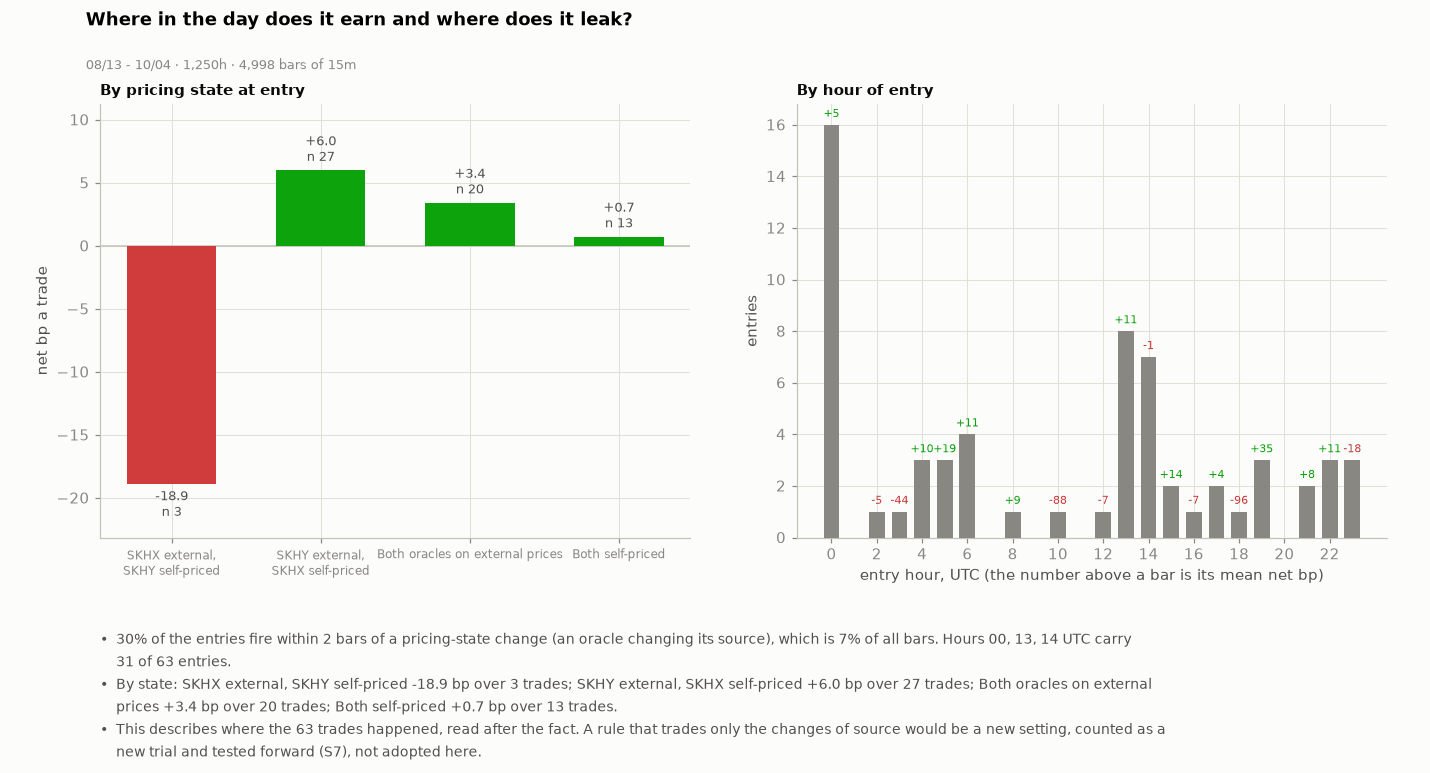

In [29]:
# ---- where in the day does it earn ----
TRS = TR.copy()
TRS["state"] = [HP.pricing_state(int(t) , CAL_A, CAL_B) for t in TRS["entry_t"]]
TRS["hour"] = ((TRS["entry_t"] // HOUR) % 24).astype(int)
TRS["net_bp"] = TRS["net"] / CLIP_USD * 1e4
gs_ = TRS.groupby("state").agg(n=("net", "size"), bp=("net_bp", "mean")).reset_index()
gh_ = TRS.groupby("hour").agg(n=("net", "size"), bp=("net_bp", "mean")).reindex(range(24)).fillna({"n": 0})
top_h = gh_["n"].sort_values(ascending=False).head(3)
sig_bar = (TR["entry_bar"] - 1).to_numpy()
near_share, base_share = float(NO_ENTRY[sig_bar].mean()), float(NO_ENTRY[2 * HALF_LIFE:].mean())
BUL = [f"{near_share * 100:.0f}% of the entries fire within {B_BARS} bars of a pricing-state change (an oracle changing its source), which is {base_share * 100:.0f}% of all bars. Hours {', '.join(f'{int(h_):02d}' for h_ in top_h.index)} UTC carry {int(top_h.sum())} of {len(TRS)} entries.",
       f"By state: " + "; ".join(f"{STATE_LABEL[r_['state']]} {r_['bp']:+.1f} bp over {int(r_['n'])} trades" for _, r_ in gs_.iterrows()) + ".",
       f"This describes where the {len(TRS)} trades happened, read after the fact. A rule that trades only the changes of source would be a new setting, counted as a new trial and tested forward (S7), not adopted here."]
fig, gs, top = mkfig(4.8, BUL, nrows=1, ncols=2, wspace=0.18)
ax1, ax2 = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1])
ax1.bar(range(len(gs_)), gs_["bp"], color=[GOOD if v > 0 else CRIT for v in gs_["bp"]], width=0.6, zorder=3)
for i_, r_ in gs_.iterrows():
    ax1.text(i_, r_["bp"] + (0.4 if r_["bp"] >= 0 else -0.4), f"{r_['bp']:+.1f}\nn {int(r_['n'])}", ha="center", va="bottom" if r_["bp"] >= 0 else "top", fontsize=8.5, color=INK2)
ax1.set_xticks(range(len(gs_))); ax1.set_xticklabels([STATE_LABEL[s_].replace(", ", ",\n") for s_ in gs_["state"]], fontsize=8)
ax1.axhline(0, color=AXIS, linewidth=1); ax1.set_ylabel("net bp a trade"); ax1.set_title("By pricing state at entry", fontsize=10, loc="left")
yl = ax1.get_ylim(); ax1.set_ylim(yl[0] - 3, yl[1] + 4)
hv = gh_["bp"].fillna(0)
ax2.bar(gh_.index, gh_["n"], color=C_COST, width=0.7, zorder=3)
for h_, n_ in gh_["n"].items():
    if n_ > 0:
        ax2.text(h_, n_ + 0.2, f"{hv[h_]:+.0f}", ha="center", va="bottom", fontsize=7.5, color=GOOD if hv[h_] > 0 else CRIT)
ax2.set_xticks(range(0, 24, 2)); ax2.set_xlabel("entry hour, UTC (the number above a bar is its mean net bp)"); ax2.set_ylabel("entries"); ax2.set_title("By hour of entry", fontsize=10, loc="left")
fig_ask(fig, "Where in the day does it earn and where does it leak?", WS, top)
figstyle.bullets(fig, BUL)
figstyle.show(fig, "fig:s5-when", FIGURES)

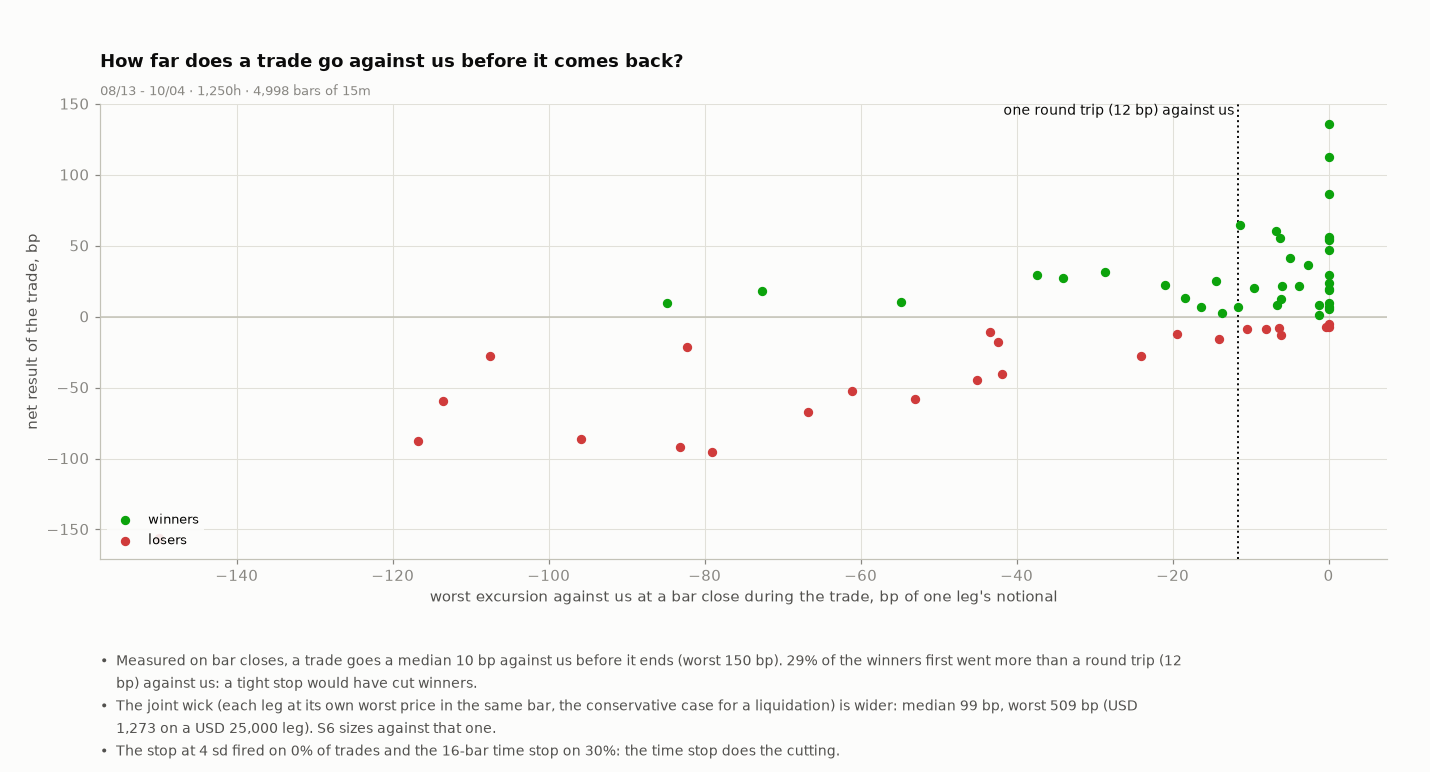

In [30]:
# ---- how far against us before it comes back: bar closes (what the rule's stop sees) and the joint wick (what a liquidation sees) ----
mae = TR["mae_close_usd"].to_numpy() / CLIP_USD * 1e4
mae_w = TR["mae_usd"].to_numpy() / CLIP_USD * 1e4
win_ = TR["net"].to_numpy() > 0
went = float((mae[win_] < -RT_COST_BP).mean()) if win_.any() else float("nan")
WORST_WICK_USD = float(TR["mae_usd"].min())
BUL = [f"Measured on bar closes, a trade goes a median {abs(np.median(mae)):.0f} bp against us before it ends (worst {abs(mae.min()):.0f} bp). {went * 100:.0f}% of the winners first went more than a round trip ({RT_COST_BP:.0f} bp) against us: a tight stop would have cut winners.",
       f"The joint wick (each leg at its own worst price in the same bar, the conservative case for a liquidation) is wider: median {abs(np.median(mae_w)):.0f} bp, worst {abs(mae_w.min()):.0f} bp ({usd(-WORST_WICK_USD)} on a {usd(CLIP_USD)} leg). S6 sizes against that one.",
       f"The stop at {Z_STOP:g} sd fired on {TS['stop'] * 100:.0f}% of trades and the {MAX_HOLD}-bar time stop on {TS['time'] * 100:.0f}%: the time stop does the cutting."]
fig, gs, top = mkfig(5.0, BUL)
ax = fig.add_subplot(gs[0])
ax.scatter(mae[win_], TR["net"].to_numpy()[win_] / CLIP_USD * 1e4, s=26, color=GOOD, zorder=4, label="winners")
ax.scatter(mae[~win_], TR["net"].to_numpy()[~win_] / CLIP_USD * 1e4, s=26, color=CRIT, zorder=4, label="losers")
ax.axhline(0, color=AXIS, linewidth=1, zorder=1); ax.axvline(-RT_COST_BP, color=INK, linewidth=1.3, linestyle=":", zorder=3)
ax.text(-RT_COST_BP, ax.get_ylim()[1], f"one round trip ({RT_COST_BP:.0f} bp) against us ", color=INK, fontsize=9, va="top", ha="right")
ax.set_xlabel("worst excursion against us at a bar close during the trade, bp of one leg's notional"); ax.set_ylabel("net result of the trade, bp"); ax.legend(loc="lower left", fontsize=8.5, **LEG)
ask(ax, "How far does a trade go against us before it comes back?", WS)
figstyle.bullets(fig, BUL)
figstyle.show(fig, "fig:s5-excursion", FIGURES)

In [31]:
# ---- where the P&L comes from: by side, and by concentration ----
SIDE = TR.groupby("side").agg(n=("net", "size"), net=("net", "sum"), bp=("net", lambda v: v.mean() / CLIP_USD * 1e4), gross=("price", lambda v: v.mean() / CLIP_USD * 1e4))
SIDE_N = {int(k_): r_ for k_, r_ in SIDE.iterrows()}
PREM1 = float(prem[-1])
display(Markdown("| Cut of the trades | Trades | Net USD | Net bp a trade | Spread bp a trade |\n|---|---|---|---|---|\n" +
                 "\n".join(f"| {nm} | {int(r_['n'])} | {usd(r_['net'])} | {r_['bp']:+.1f} | {r_['gross']:+.1f} |" for nm, r_ in (("Long the spread (buy SKHY, sell SKHX): the premium looked cheap", SIDE_N[1]), ("Short the spread (sell SKHY, buy SKHX): the premium looked rich", SIDE_N[-1]))) +
                 f"\n| All trades | {TS['n']} | {usd(NET_USD)} | {TS['net_bp']:+.1f} | {TS['gross_bp']:+.1f} |\n| Without the best five trades | {TS['n'] - 5} | {usd(NET_NO_TOP5)} | | |\n| Without the worst five trades | {TS['n'] - 5} | {usd(NET_NO_BOT5)} | | |"))
display(Markdown(f"The two sides are not alike: long-the-spread trades net {usd(SIDE_N[1]['net'])} and short-the-spread trades {usd(SIDE_N[-1]['net'])}. Over the window the perp premium went from {prem[0]:.0f}% to {PREM1:.0f}% (low {prem.min():.0f}%, high {prem.max():.0f}%). "
                 "This describes one window, read after the fact; it does not say why the sides differ."))

| Cut of the trades | Trades | Net USD | Net bp a trade | Spread bp a trade |
|---|---|---|---|---|
| Long the spread (buy SKHY, sell SKHX): the premium looked cheap | 33 | USD -454 | -5.5 | +6.1 |
| Short the spread (sell SKHY, buy SKHX): the premium looked rich | 30 | USD 911 | +12.1 | +25.6 |
| All trades | 63 | USD 456 | +2.9 | +15.4 |
| Without the best five trades | 58 | USD -692 | | |
| Without the worst five trades | 58 | USD 1,751 | | |

The two sides are not alike: long-the-spread trades net USD -454 and short-the-spread trades USD 911. Over the window the perp premium went from 37% to 41% (low 29%, high 44%). This describes one window, read after the fact; it does not say why the sides differ.

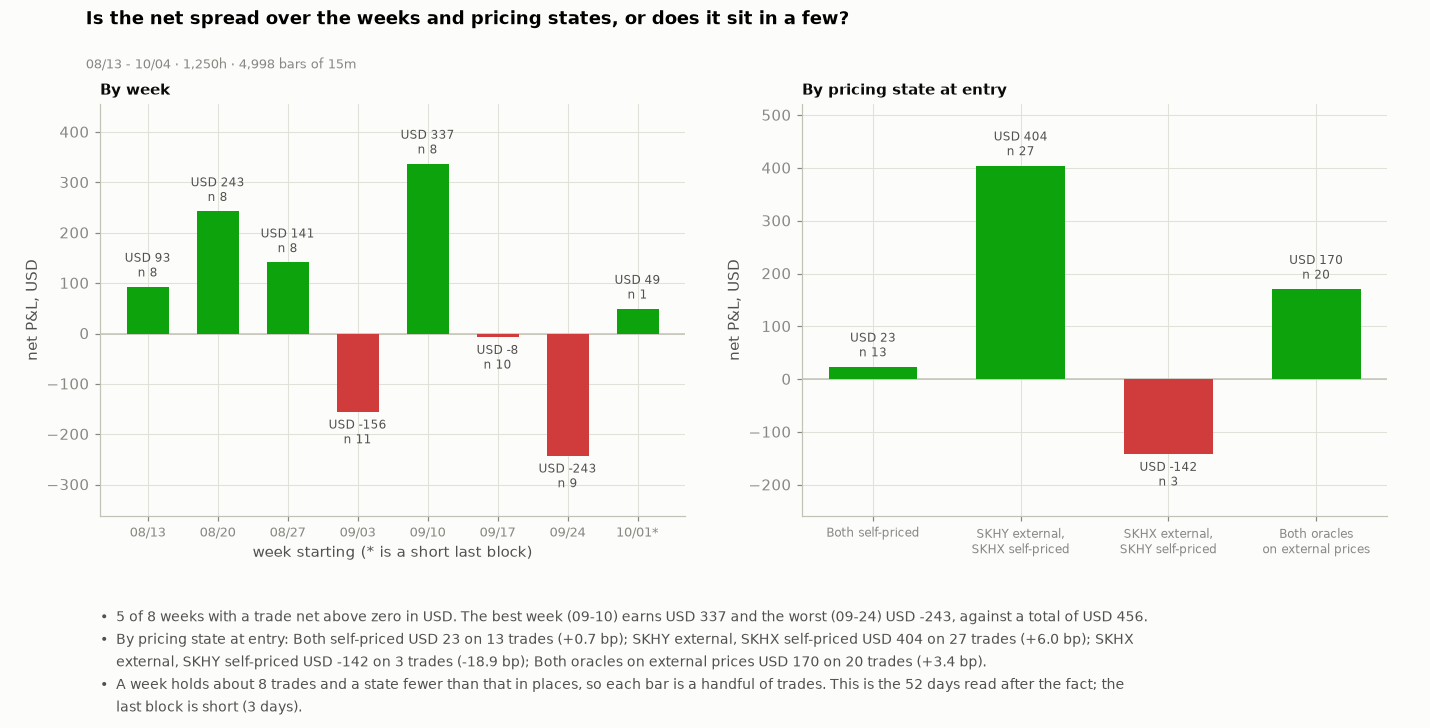

Net USD (trades) by week and pricing state at entry:

| Week from | Both self-priced | SKHY external, SKHX self-priced | SKHX external, SKHY self-priced | Both oracles on external prices | All |
|---|---|---|---|---|---|
| 2026-08-13 | USD 3 (1) | USD 175 (4) | USD 0 (0) | USD -85 (3) | USD 93 (8) |
| 2026-08-20 | USD 49 (3) | USD 124 (2) | USD 0 (0) | USD 70 (3) | USD 243 (8) |
| 2026-08-27 | USD 0 (0) | USD -273 (3) | USD 24 (1) | USD 390 (4) | USD 141 (8) |
| 2026-09-03 | USD 22 (2) | USD 111 (4) | USD -165 (2) | USD -123 (3) | USD -156 (11) |
| 2026-09-10 | USD 32 (2) | USD 273 (5) | USD 0 (0) | USD 32 (1) | USD 337 (8) |
| 2026-09-17 | USD -25 (3) | USD -10 (3) | USD 0 (0) | USD 28 (4) | USD -8 (10) |
| 2026-09-24 | USD -57 (2) | USD -45 (5) | USD 0 (0) | USD -141 (2) | USD -243 (9) |
| 2026-10-01 | USD 0 (0) | USD 49 (1) | USD 0 (0) | USD 0 (0) | USD 49 (1) |

In [32]:
# ---- regime: the net by week and by pricing state at entry, over the whole window ----
TRS["wk"] = ((TRS["entry_t"] - T0) // (WEEK_D * DAY)).astype(int)
WKG = TRS.groupby("wk").agg(n=("net", "size"), net=("net", "sum"), bp=("net_bp", "mean")).reindex(range(X_NWK)).fillna({"n": 0, "net": 0.0})
assert abs(WKG["net"].sum() - NET_USD) < 1e-6 and int(WKG["n"].sum()) == len(TRS), "the weeks must tile the trades"
STG = TRS.groupby("state").agg(n=("net", "size"), net=("net", "sum"), bp=("net_bp", "mean")).reindex([k_ for k_ in ("both_internal", "A_internal_B_external", "A_external_B_internal", "both_external") if k_ in set(TRS["state"])])
assert abs(STG["net"].sum() - NET_USD) < 1e-6
PIV = TRS.pivot_table(index="wk", columns="state", values="net", aggfunc=["sum", "size"], fill_value=0).reindex(range(X_NWK), fill_value=0)
best_w, worst_w = int(WKG["net"].idxmax()), int(WKG["net"].idxmin())
BUL = [f"{int((WKG['net'] > 0).sum())} of {int((WKG['n'] > 0).sum())} weeks with a trade net above zero in USD. The best week ({iso_(WF[best_w]['from'])[5:10]}) earns {usd(WKG['net'][best_w])} and the worst ({iso_(WF[worst_w]['from'])[5:10]}) {usd(WKG['net'][worst_w])}, against a total of {usd(NET_USD)}.",
       "By pricing state at entry: " + "; ".join(f"{STATE_LABEL[k_]} {usd(r_['net'])} on {int(r_['n'])} trades ({r_['bp']:+.1f} bp)" for k_, r_ in STG.iterrows()) + ".",
       f"A week holds about {WKG['n'].mean():.0f} trades and a state fewer than that in places, so each bar is a handful of trades. This is the {DAYS:.0f} days read after the fact; the last block is short ({WF[-1]['days']:.0f} days)."]
fig, gs, top = mkfig(4.6, BUL, nrows=1, ncols=2, wspace=0.2, ratios=None)
ax1, ax2 = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1])
ax1.bar(range(X_NWK), WKG["net"], color=[GOOD if v_ > 0 else CRIT for v_ in WKG["net"]], width=0.6, zorder=3)
for i_, (v_, n_) in enumerate(zip(WKG["net"], WKG["n"])):
    ax1.text(i_, v_ + (12 if v_ >= 0 else -12), f"{usd(v_)}\nn {int(n_)}", ha="center", va="bottom" if v_ >= 0 else "top", fontsize=8, color=INK2)
ax1.set_xticks(range(X_NWK)); ax1.set_xticklabels([iso_(w_["from"])[5:10].replace("-", "/") + ("*" if w_["days"] < WEEK_D else "") for w_ in WF], fontsize=8.5)
ax1.axhline(0, color=AXIS, linewidth=1); ax1.set_ylabel("net P&L, USD"); ax1.set_xlabel("week starting (* is a short last block)"); ax1.set_title("By week", fontsize=10, loc="left")
yl_ = ax1.get_ylim(); ax1.set_ylim(yl_[0] - 90, yl_[1] + 90)
ax2.bar(range(len(STG)), STG["net"], color=[GOOD if v_ > 0 else CRIT for v_ in STG["net"]], width=0.6, zorder=3)
for i_, (v_, n_) in enumerate(zip(STG["net"], STG["n"])):
    ax2.text(i_, v_ + (12 if v_ >= 0 else -12), f"{usd(v_)}\nn {int(n_)}", ha="center", va="bottom" if v_ >= 0 else "top", fontsize=8, color=INK2)
ax2.set_xticks(range(len(STG))); ax2.set_xticklabels([STATE_LABEL[k_].replace(", ", ",\n").replace(" on ", "\non ") for k_ in STG.index], fontsize=8)
ax2.axhline(0, color=AXIS, linewidth=1); ax2.set_ylabel("net P&L, USD"); ax2.set_title("By pricing state at entry", fontsize=10, loc="left")
yl_ = ax2.get_ylim(); ax2.set_ylim(yl_[0] - 90, yl_[1] + 90)
fig_ask(fig, "Is the net spread over the weeks and pricing states, or does it sit in a few?", WS, top)
figstyle.bullets(fig, BUL)
figstyle.show(fig, "fig:s5-regime", FIGURES)
display(Markdown("Net USD (trades) by week and pricing state at entry:\n\n| Week from | " + " | ".join(STATE_LABEL[k_] for k_ in STG.index) + " | All |\n|---|" + "---|" * (len(STG) + 1) + "\n" +
                 "\n".join(f"| {iso_(w_['from'])[:10]} | " + " | ".join(f"{usd(PIV['sum'][k_][w_['k']])} ({int(PIV['size'][k_][w_['k']])})" if k_ in PIV['sum'].columns else "n/a" for k_ in STG.index) + f" | {usd(WKG['net'][w_['k']])} ({int(WKG['n'][w_['k']])}) |" for w_ in WF)))

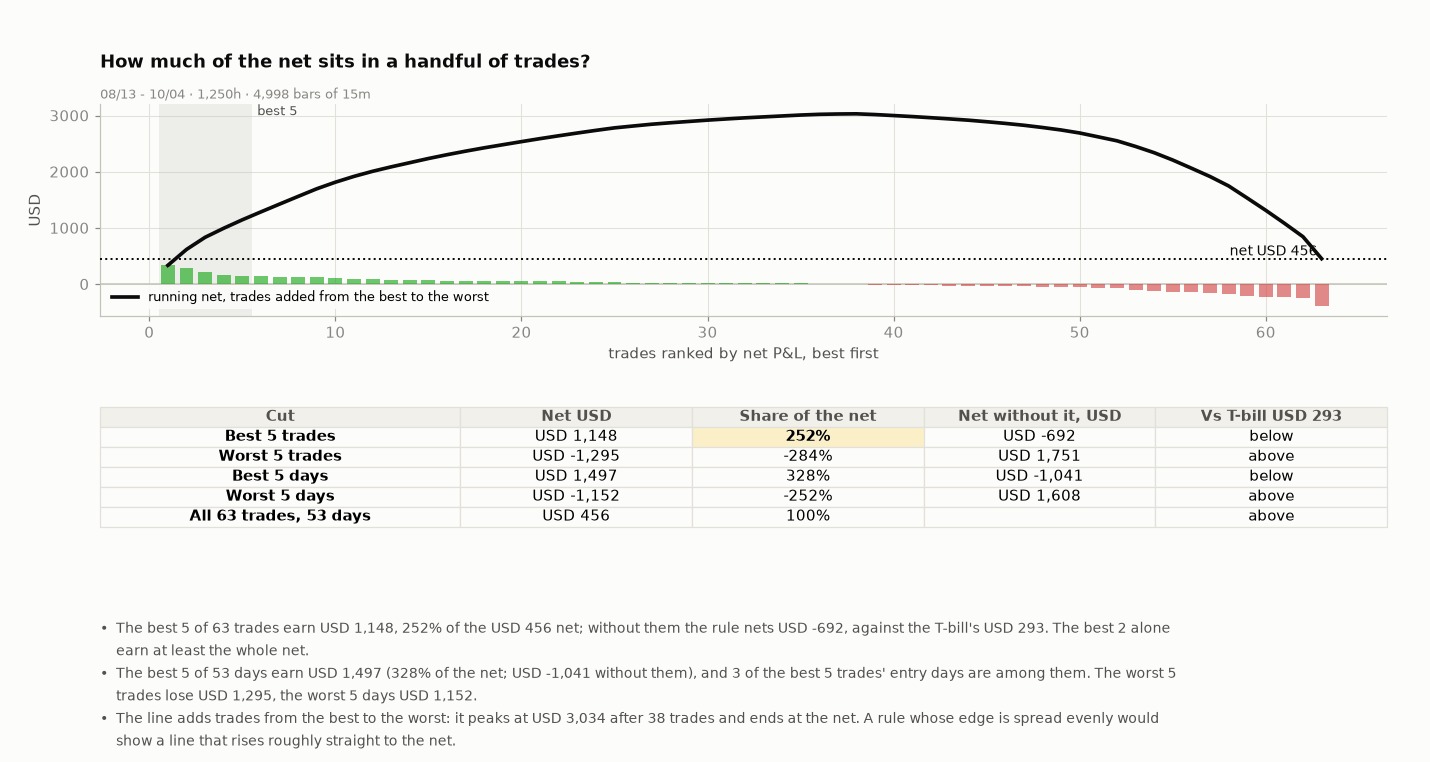

In [33]:
# ---- concentration: how much of the net sits in the best few trades and days ----
X_SORT = TR["net"].sort_values(ascending=False).to_numpy()
X_CUM = np.cumsum(X_SORT)
X_KMIN = int(np.argmax(X_CUM >= NET_USD)) + 1                                     # the fewest best trades that alone earn at least the whole net
DAY_NET = DAILY.sort_values(ascending=False)
TOPD, BOTD = float(DAY_NET.head(TOP_K).sum()), float(DAY_NET.tail(TOP_K).sum())
TOPT, BOTT = float(X_SORT[:TOP_K].sum()), float(X_SORT[-TOP_K:].sum())
_eday = pd.to_datetime(TR["entry_t"], unit="ms", utc=True).dt.floor("D")
_best_t_days = set(_eday.loc[TR["net"].nlargest(TOP_K).index])
OVERLAP = len(_best_t_days & set(DAY_NET.head(TOP_K).index))
CONC_ROWS = [(f"Best {TOP_K} trades", TOPT), (f"Worst {TOP_K} trades", BOTT), (f"Best {TOP_K} days", TOPD), (f"Worst {TOP_K} days", BOTD)]
BUL = [f"The best {TOP_K} of {len(TR)} trades earn {usd(TOPT)}, {TOPT / NET_USD * 100:.0f}% of the {usd(NET_USD)} net; without them the rule nets {usd(NET_USD - TOPT)}, against the T-bill's {usd(HURDLE_USD_ALL)}. The best {X_KMIN} alone earn at least the whole net.",
       f"The best {TOP_K} of {len(DAILY)} days earn {usd(TOPD)} ({TOPD / NET_USD * 100:.0f}% of the net; {usd(NET_USD - TOPD)} without them), and {OVERLAP} of the best {TOP_K} trades' entry days are among them. The worst {TOP_K} trades lose {usd(-BOTT)}, the worst {TOP_K} days {usd(-BOTD)}.",
       f"The line adds trades from the best to the worst: it peaks at {usd(X_CUM.max())} after {int(np.argmax(X_CUM)) + 1} trades and ends at the net. A rule whose edge is spread evenly would show a line that rises roughly straight to the net."]
fig, gs, top = mkfig(4.7, BUL, nrows=2, ncols=1, ratios=(2.3, 1.3), hspace=0.55)
ax, axt = fig.add_subplot(gs[0]), fig.add_subplot(gs[1]); axt.axis("off")
xs_ = np.arange(1, len(X_SORT) + 1)
ax.bar(xs_, X_SORT, color=[GOOD if v_ > 0 else CRIT for v_ in X_SORT], width=0.75, zorder=3, alpha=0.6)
ax.plot(xs_, X_CUM, color=INK, linewidth=2.4, zorder=5, label="running net, trades added from the best to the worst")
ax.axhline(NET_USD, color=INK, linewidth=1.3, linestyle=":", zorder=3); ax.text(len(X_SORT), NET_USD, f"net {usd(NET_USD)} ", ha="right", va="bottom", color=INK, fontsize=9)
ax.axhline(0, color=AXIS, linewidth=1, zorder=1)
ax.axvspan(0.5, TOP_K + 0.5, color=AXIS, alpha=0.25, linewidth=0, zorder=1); ax.text(TOP_K + 0.8, ax.get_ylim()[1], f"best {TOP_K}", fontsize=8.5, color=INK2, va="top")
ax.set_xlabel("trades ranked by net P&L, best first"); ax.set_ylabel("USD"); ax.legend(loc="lower left", fontsize=8.5, **LEG)
ask(ax, "How much of the net sits in a handful of trades?", WS)
cells = [[nm_, usd(v_), f"{v_ / NET_USD * 100:.0f}%", usd(NET_USD - v_), "above" if NET_USD - v_ > HURDLE_USD_ALL else "below"] for nm_, v_ in CONC_ROWS] + [[f"All {len(TR)} trades, {len(DAILY)} days", usd(NET_USD), "100%", "", "above" if NET_USD > HURDLE_USD_ALL else "below"]]
tb = figstyle.put_table(axt, cells, ["Cut", "Net USD", "Share of the net", "Net without it, USD", f"Vs T-bill {usd(HURDLE_USD_ALL)}"], size=9.5, first=0.28)
figstyle.gold(tb, 1, 2)
figstyle.bullets(fig, BUL)
figstyle.show(fig, "fig:s5-concentration", FIGURES)

In [34]:
# ---- long against short: the split with an interval, by half of the window ----
SIDE_ROWS = []
for nm_, sd_ in (("Long the spread (buy SKHY, sell SKHX)", 1), ("Short the spread (sell SKHY, buy SKHX)", -1)):
    sub_ = TR[TR["side"] == sd_]
    xb_ = sub_["net"].to_numpy() / CLIP_USD * 1e4
    lo_, hi_, _ = boot_ci(xb_, max(1, min(X_L_T, len(xb_) // 3)), CI_SEED)
    a_, b_ = sub_[sub_["entry_t"] < T_SPLIT], sub_[sub_["entry_t"] >= T_SPLIT]
    SIDE_ROWS.append({"nm": nm_, "n": len(sub_), "usd": float(sub_["net"].sum()), "bp": float(xb_.mean()), "lo": lo_, "hi": hi_, "gross": float(sub_["price"].mean() / CLIP_USD * 1e4),
                      "is_bp": float(a_["net"].mean() / CLIP_USD * 1e4) if len(a_) else float("nan"), "is_n": len(a_), "oos_bp": float(b_["net"].mean() / CLIP_USD * 1e4) if len(b_) else float("nan"), "oos_n": len(b_)})
SIDE_OVERLAP = not (SIDE_ROWS[0]["hi"] < SIDE_ROWS[1]["lo"] or SIDE_ROWS[1]["hi"] < SIDE_ROWS[0]["lo"])
display(Markdown("| Side | Trades | Net USD | Net bp a trade (95% interval) | Spread bp a trade | In-sample bp (trades) | Out-of-sample bp (trades) |\n|---|---|---|---|---|---|---|\n" +
                 "\n".join(f"| {r_['nm']} | {r_['n']} | {usd(r_['usd'])} | {r_['bp']:+.1f} ({r_['lo']:+.1f} to {r_['hi']:+.1f}) | {r_['gross']:+.1f} | {r_['is_bp']:+.1f} ({r_['is_n']}) | {r_['oos_bp']:+.1f} ({r_['oos_n']}) |" for r_ in SIDE_ROWS)))
display(Markdown(f"The two intervals {'overlap' if SIDE_OVERLAP else 'do not overlap'}, so with {SIDE_ROWS[0]['n']} and {SIDE_ROWS[1]['n']} trades the data {'cannot' if SIDE_OVERLAP else 'can'} tell the sides apart by their net alone. The premium went from {prem[0]:.0f}% to {PREM1:.0f}% over the window: "
                 "one window cannot say whether the gap between the sides is structural or a product of that path."))

| Side | Trades | Net USD | Net bp a trade (95% interval) | Spread bp a trade | In-sample bp (trades) | Out-of-sample bp (trades) |
|---|---|---|---|---|---|---|
| Long the spread (buy SKHY, sell SKHX) | 33 | USD -454 | -5.5 (-16.8 to +6.4) | +6.1 | -4.8 (20) | -6.7 (13) |
| Short the spread (sell SKHY, buy SKHX) | 30 | USD 911 | +12.1 (-3.7 to +27.0) | +25.6 | +15.6 (23) | +0.8 (7) |

The two intervals overlap, so with 33 and 30 trades the data cannot tell the sides apart by their net alone. The premium went from 37% to 41% over the window: one window cannot say whether the gap between the sides is structural or a product of that path.

In [35]:
# ---- the risk table: drawdown, tails and what is not on a chart ----
eq_d = CAPITAL + np.cumsum(DAILY.to_numpy())
dd_d = eq_d / np.maximum.accumulate(eq_d) - 1
under = 0; best_u = 0
for v_ in dd_d:
    under = under + 1 if v_ < 0 else 0
    best_u = max(best_u, under)
worst_day = float(DAILY.min()); worst_trade = float(TR["net"].min())
DD_OK = abs(MAXDD_PCT) <= DD_LIMIT_PCT
RISK = {"max_dd_pct": MAXDD_PCT, "max_dd_days": float(best_u), "worst_day": worst_day, "worst_trade": worst_trade, "ann_vol_pct": float(np.std(dr_, ddof=1) * math.sqrt(365) * 100)}
def f_(v, d=2, suf=""):
    return "n/a" if v is None or (isinstance(v, float) and not math.isfinite(v)) else f"{v:,.{d}f}{suf}"


ANN_RET = NET_USD / CAPITAL * 365 / DAYS * 100
TAIL = ST.tail_stats(list(dr_))
DD_DAYS = ST.max_dd_days(list(eq_d), list(DAILY.index))
REC_DAYS = ST.recovery_days(list(eq_d), list(DAILY.index))
SORTINO, CALMAR = ST.sortino(list(dr_), 365), ST.calmar(list(dr_), 365)
DD_DAILY_PCT = float(dd_d.min() * 100)
EXPOSURE = ST.time_in_market(list(RES["pos"])) * 100
TURNOVER = TS["n"] * 4 * CLIP_USD / CAPITAL * 365 / DAYS
nb_all = TR["net"].to_numpy() / CLIP_USD * 1e4
STATS_FULL = [
    ("Return and risk", "daily P&L on equity, 365 days a year, 1x", [
        ("Annual return", f_(ANN_RET, 1, "%")), ("Excess over the T-bill", f_(ANN_RET - HURDLE * 100, 1, " pts")), ("Annualised volatility", f_(RISK["ann_vol_pct"], 1, "%")),
        ("Sharpe", f_(SHARPE_D)), ("Sortino", f_(SORTINO)), ("Calmar", f_(CALMAR)), ("Probabilistic Sharpe vs 0", f_(PSR0)), (f"Deflated Sharpe ({N_TRIALS} trials)", f_(DSR_)),
        ("Daily skew / kurtosis", f"{f_(TAIL['skew'])} / {f_(TAIL['kurtosis'])}"), ("Days", f"{len(dr_)}")]),
    ("Drawdown and tails", "", [
        ("Max drawdown, daily marks", f_(DD_DAILY_PCT, 2, "%")), ("Max drawdown, bar marks (open to open)", f"{MAXDD_PCT:.2f}% ({usd(maxdd_usd(RES))}); limit {DD_LIMIT_PCT:g}% [U]: {'inside' if DD_OK else 'OUTSIDE'}"),
        ("Longest time under the high", f_(DD_DAYS, 0, " days")), ("Recovery of the deepest drawdown", f_(REC_DAYS, 0, " days")),
        ("Worst day", f"{usd(worst_day)} ({worst_day / CAPITAL * 100:.2f}% of equity)"), ("Daily VaR / CVaR, 95%", f"{f_(-TAIL['VaR 95%'] * 100, 2, '%')} / {f_(-TAIL['CVaR 95%'] * 100, 2, '%')} of equity"),
        ("Worst joint wick inside a trade", f"{usd(-WORST_WICK_USD)} on a {usd(CLIP_USD)} leg")]),
    ("Trades", "one trade = a round trip of both legs", [
        ("Trades, a day", f"{TS['n']}, {TS['per_day']:.1f}"), ("Hit rate", f_(TS["hit"] * 100, 0, "%")), ("Win / loss ratio", f_(TS["payoff"])), ("Profit factor", f_(TS["pf"])),
        ("Expectancy, mean / median", f"{TS['net_bp']:+.1f} / {np.median(nb_all):+.1f} bp of one leg"), ("Best / worst trade", f"{usd(TR['net'].max())} / {usd(worst_trade)}"),
        ("Average hold", f_(TS["hold_bars"] * STEP_MS / HOUR, 1, " h")), ("Time in the market", f_(EXPOSURE, 1, "%")),
        ("Turnover, a year", f_(TURNOVER, 0, "x equity")), ("Costs as a share of the spread P&L", f_(-(TS["fees_usd"] + TS["slip_usd"]) / TS["gross_usd"] * 100, 0, "%"))]),
]
# ---- the rest of the industry-standard set: compound return, excess Sharpe, the mean's t-stat, pain ratios, drawdown shape, and neutrality to each leg ----
TOTAL_RET = NET_USD / CAPITAL * 100
CAGR = ((1 + TOTAL_RET / 100) ** (365 / DAYS) - 1) * 100
EXC_SHARPE = ST.sharpe([r_ - HURDLE / 365 for r_ in dr_], 365)
NW = ST.newey_west(list(dr_))
GTP = float(np.sum(dr_) / -np.sum(np.minimum(dr_, 0.0))) if np.any(np.array(dr_) < 0) else float("nan")
TAIL_RATIO = float(abs(np.percentile(dr_, 95) / np.percentile(dr_, 5))) if np.percentile(dr_, 5) != 0 else float("nan")
ULCER = float(np.sqrt(np.mean(dd_d ** 2)) * 100)
SPELLS = ST.drawdown_spells(list(eq_d), list(DAILY.index))
AVG_DD = float(np.mean([sp_["depth"] for sp_ in SPELLS]) * 100) if SPELLS else 0.0
run_l = best_l = 0
for v_ in TR["net"]:
    run_l = run_l + 1 if v_ < 0 else 0
    best_l = max(best_l, run_l)
IDX_O = pd.to_datetime(BARS["t"], unit="ms", utc=True)                       # a bar by its OPEN, the clock the daily P&L uses
lx_ = np.log(pd.Series(BARS["cx"], index=IDX_O).groupby(IDX_O.floor("D")).last()).diff()
ly_ = np.log(pd.Series(BARS["cy"], index=IDX_O).groupby(IDX_O.floor("D")).last()).diff()
NB = pd.DataFrame({"p": DAILY.reindex(lx_.index).fillna(0.0).values / CAPITAL, "x": lx_.values, "y": ly_.values}, index=lx_.index).dropna()
NB["sp"] = NB["y"] - NB["x"]
beta_ = lambda c_: float(np.cov(NB["p"], NB[c_])[0, 1] / np.var(NB[c_], ddof=1))
corr_ = lambda c_: float(NB["p"].corr(NB[c_]))
STATS_FULL[0][2].extend([("Total return / compound annual return (CAGR)", f"{TOTAL_RET:.2f}% / {CAGR:.1f}%"), ("Sharpe of the excess over the T-bill (information ratio)", f_(EXC_SHARPE)),
                         ("t-stat of the mean daily P&L (Newey-West)", f"{f_(NW['t'])} (p {NW['p']:.2f}, {NW['lags']} lags)"), ("Positive days", f"{(DAILY > 0).mean() * 100:.0f}% of {len(DAILY)} days; {(DAILY != 0).sum()} days with a trade"),
                         ("Gain-to-pain ratio (sum of daily returns over the sum of losing days)", f_(GTP)), ("Tail ratio (95th over 5th percentile of daily P&L)", f_(TAIL_RATIO))])
STATS_FULL[1][2].extend([("Average drawdown, ulcer index", f"{f_(AVG_DD, 2, '%')}, {f_(ULCER, 2)}"), ("Longest run of losing trades", f"{best_l} in a row")])
STATS_FULL.insert(2, ("Market neutrality", "daily P&L on equity against each leg's daily log return", [
    ("Beta to SKHX / SKHY", f"{beta_('x'):+.3f} / {beta_('y'):+.3f}"), ("Correlation with SKHX / SKHY", f"{corr_('x'):+.2f} / {corr_('y'):+.2f}"),
    ("Beta to the spread's own move (SKHY minus SKHX)", f"{beta_('sp'):+.3f} (correlation {corr_('sp'):+.2f})")]))
display(Markdown("| Statistic | Reading |\n|---|---|\n" + "\n".join(
    f"| **{g_} ({n_})** | |\n" + "\n".join(f"| {a} | {b} |" for a, b in rows_) if n_ else f"| **{g_}** | |\n" + "\n".join(f"| {a} | {b} |" for a, b in rows_) for g_, n_, rows_ in STATS_FULL)))
display(Markdown(f"Read the ratios with care: Sharpe, Sortino, Calmar and the annual return annualise {DAYS:.0f} days, and the mean daily P&L has a Newey-West t of {NW['t']:.2f}, so none of them is distinguishable from zero. Not in this window: the July oracle incident (a one-leg mark move of the order of a fifth), the discovery bound, a Korean holiday week with the hours that follow; the window has one regime."))

| Statistic | Reading |
|---|---|
| **Return and risk (daily P&L on equity, 365 days a year, 1x)** | |
| Annual return | 6.4% |
| Excess over the T-bill | 2.3 pts |
| Annualised volatility | 5.3% |
| Sharpe | 1.18 |
| Sortino | 1.89 |
| Calmar | 4.62 |
| Probabilistic Sharpe vs 0 | 0.67 |
| Deflated Sharpe (106 trials) | 0.05 |
| Daily skew / kurtosis | 0.34 / 3.52 |
| Days | 53 |
| Total return / compound annual return (CAGR) | 0.91% / 6.6% |
| Sharpe of the excess over the T-bill (information ratio) | 0.41 |
| t-stat of the mean daily P&L (Newey-West) | 0.43 (p 0.67, 3 lags) |
| Positive days | 42% of 53 days; 42 days with a trade |
| Gain-to-pain ratio (sum of daily returns over the sum of losing days) | 0.20 |
| Tail ratio (95th over 5th percentile of daily P&L) | 1.38 |
| **Drawdown and tails** | |
| Max drawdown, daily marks | -1.36% |
| Max drawdown, bar marks (open to open) | -1.40% (USD -705); limit 5% [U]: inside |
| Longest time under the high | 16 days |
| Recovery of the deepest drawdown | 4 days |
| Worst day | USD -340 (-0.68% of equity) |
| Daily VaR / CVaR, 95% | 0.42% / 0.52% of equity |
| Worst joint wick inside a trade | USD 1,273 on a USD 25,000 leg |
| Average drawdown, ulcer index | -0.91%, 0.63 |
| Longest run of losing trades | 5 in a row |
| **Market neutrality (daily P&L on equity against each leg's daily log return)** | |
| Beta to SKHX / SKHY | -0.007 / -0.009 |
| Correlation with SKHX / SKHY | -0.10 / -0.11 |
| Beta to the spread's own move (SKHY minus SKHX) | -0.006 (correlation -0.02) |
| **Trades (one trade = a round trip of both legs)** | |
| Trades, a day | 63, 1.2 |
| Hit rate | 60% |
| Win / loss ratio | 0.77 |
| Profit factor | 1.18 |
| Expectancy, mean / median | +2.9 / +7.9 bp of one leg |
| Best / worst trade | USD 339 / USD -391 |
| Average hold | 2.5 h |
| Time in the market | 12.4% |
| Turnover, a year | 883x equity |
| Costs as a share of the spread P&L | 75% |

Read the ratios with care: Sharpe, Sortino, Calmar and the annual return annualise 52 days, and the mean daily P&L has a Newey-West t of 0.43, so none of them is distinguishable from zero. Not in this window: the July oracle incident (a one-leg mark move of the order of a fifth), the discovery bound, a Korean holiday week with the hours that follow; the window has one regime.

## S6 · Decision

| Question | Decision rule |
|---|---|
| If it passed: what size, can the book fill it, what are the limits? | size only after every S3 and S4 gate passed, else the rung is information only |

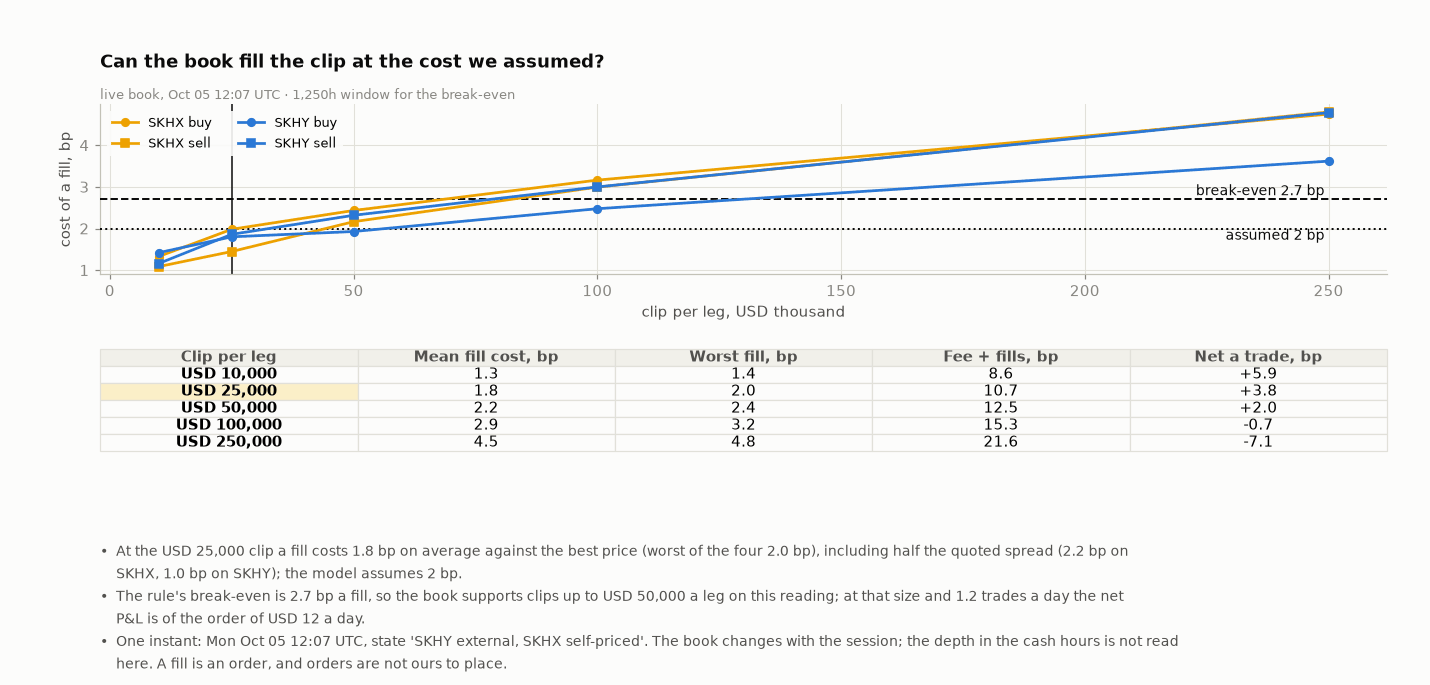

In [36]:
# ---- can the book fill the clip at the cost we assumed? A LIVE reading: one instant, stored nowhere ----
SIZES = (10_000.0, 25_000.0, 50_000.0, 100_000.0, 250_000.0)
BK = HP.book_depth((COIN_A, COIN_B), sizes=SIZES)
assert all(BK[c_] for c_ in (COIN_A, COIN_B)), "no book"
NOW_UTC = dt.datetime.now(dt.timezone.utc)
live_state = HP.pricing_state(int(NOW_UTC.timestamp() * 1000), CAL_A, CAL_B)
def per_fill(sz):
    out = []
    for c_ in (COIN_A, COIN_B):
        half = (BK[c_]["spread_bps"] or 0.0) / 2.0
        for side in ("buy", "sell"):
            f = BK[c_]["fills"][sz][side]
            out.append(f["slippage_bps"] + half if f["filled"] else float("nan"))
    return out
PF = {sz: per_fill(sz) for sz in SIZES}
avg_ = {sz: float(np.nanmean(v)) for sz, v in PF.items()}
worst_ = {sz: float(np.nanmax(v)) if not np.isnan(v).all() else float("nan") for sz, v in PF.items()}
clip_k = CLIP_USD if CLIP_USD in SIZES else SIZES[1]
G_FILL = avg_[clip_k] <= SLIP_BPS
cap_clip = max([sz for sz in SIZES if avg_[sz] <= BE_ALL], default=None)
BUL = [f"At the {usd(CLIP_USD)} clip a fill costs {avg_[clip_k]:.1f} bp on average against the best price (worst of the four {worst_[clip_k]:.1f} bp), including half the quoted spread ({BK[COIN_A]['spread_bps']:.1f} bp on SKHX, {BK[COIN_B]['spread_bps']:.1f} bp on SKHY); the model assumes {SLIP_BPS:g} bp.",
       (f"The rule's break-even is {BE_ALL:.1f} bp a fill, so the book supports clips up to {usd(cap_clip)} a leg on this reading; at that size and {TS['per_day']:.1f} trades a day the net P&L is of the order of {usd((TS['gross_bp'] + TS['fund_bp'] - 4 * (FEE_BPS + avg_[cap_clip])) / 1e4 * cap_clip * TS['per_day'])} a day." if cap_clip else f"The rule's break-even is {BE_ALL:.1f} bp a fill, below the cheapest clip read."),
       f"One instant: {NOW_UTC:%a %b %d %H:%M} UTC, state '{STATE_LABEL[live_state]}'. The book changes with the session; the depth in the cash hours is not read here. A fill is an order, and orders are not ours to place."]
fig, gs, top = mkfig(4.0, BUL, nrows=2, ncols=1, ratios=(2.0, 1.2), hspace=0.55)
ax, axt = fig.add_subplot(gs[0]), fig.add_subplot(gs[1]); axt.axis("off")
for i_, (c_, col_) in enumerate(((COIN_A, C_A), (COIN_B, C_B))):
    for j_, (side, mk_) in enumerate((("buy", "o"), ("sell", "s"))):
        ys = [BK[c_]["fills"][sz][side]["slippage_bps"] + (BK[c_]["spread_bps"] or 0) / 2 if BK[c_]["fills"][sz][side]["filled"] else np.nan for sz in SIZES]
        ax.plot([sz / 1e3 for sz in SIZES], ys, color=col_, linewidth=1.8, marker=mk_, markersize=5, zorder=4, label=f"{c_.split(':')[1]} {side}")
ax.axhline(SLIP_BPS, color=INK, linewidth=1.3, linestyle=":", zorder=3); ax.text(SIZES[-1] / 1e3, SLIP_BPS, f"assumed {SLIP_BPS:g} bp ", ha="right", va="top", color=INK, fontsize=9)
ax.axhline(BE_ALL, color=INK, linewidth=1.3, linestyle="--", zorder=3); ax.text(SIZES[-1] / 1e3, BE_ALL, f"break-even {BE_ALL:.1f} bp ", ha="right", va="bottom", color=INK, fontsize=9)
ax.axvline(CLIP_USD / 1e3, color=INK, linewidth=1.0, zorder=2)
ax.set_xlabel("clip per leg, USD thousand"); ax.set_ylabel("cost of a fill, bp"); ax.legend(loc="upper left", fontsize=8.5, ncol=2, **LEG)
ask(ax, "Can the book fill the clip at the cost we assumed?", f"live book, {NOW_UTC:%b %d %H:%M} UTC · {HOURS:,.0f}h window for the break-even")
cells = [[usd(sz), f"{avg_[sz]:.1f}", f"{worst_[sz]:.1f}", f"{4 * (FEE_BPS + avg_[sz]):.1f}", f"{TS['gross_bp'] + TS['fund_bp'] - 4 * (FEE_BPS + avg_[sz]):+.1f}"] for sz in SIZES]
tb = figstyle.put_table(axt, cells, ["Clip per leg", "Mean fill cost, bp", "Worst fill, bp", "Fee + fills, bp", "Net a trade, bp"], size=9.5, first=0.2)
figstyle.gold(tb, SIZES.index(clip_k) + 1, 0)
figstyle.bullets(fig, BUL)
figstyle.show(fig, "fig:s6-fill", FIGURES)

In [37]:
# ---- the decision rule reads the falsifier written in S0: each line is evaluated here, and a line left unevaluated stops the run ----
def read_falsifier(ci_lo, trail, trail_n, no_top5, be, slip):
    """Each F line as (tripped, reading); None is pending (a forward read not yet possible)."""
    return {"F1": (ci_lo <= 0, f"lower end of the interval {ci_lo:+.1f} bp"),
            "F2": ((not trail > 0) if trail_n else None, f"{trail:+.1f} bp over {trail_n} trades" if trail_n else "no trade in those days"),
            "F3": (no_top5 <= 0, f"{usd(no_top5)} without the best {TOP_K}"),
            "F4": (be <= slip, f"break-even {be:.1f} bp, assumed {slip:g} bp"),
            "F5": (None, "the days are not yet in")}
FALS_READ = read_falsifier(X_CI_LO, X_TRAIL, X_TRAIL_N, NET_NO_TOP5, BE_ALL, SLIP_BPS)
assert set(FALS_READ) == {f_["id"] for f_ in FALSIFIER}, "a falsifier line has no reading, or a reading has no line"
_clear = read_falsifier(+1.0, +1.0, 5, +1.0, SLIP_BPS + 1.0, SLIP_BPS)             # break it once on purpose: favourable readings must clear every line that can be read
assert not any(t_ for k_, (t_, _) in _clear.items() if k_ != "F5" and t_ is not None) and FALS_READ["F5"][0] is None
FALS_TRIPPED = [k_ for k_, (t_, _) in FALS_READ.items() if t_ is True]
FALS_PENDING = [k_ for k_, (t_, _) in FALS_READ.items() if t_ is None]
display(Markdown("| Id | The study ends if (fixed in S0) | Reading | Status |\n|---|---|---|---|\n" + "\n".join(
    f"| {f_['id']} | {f_['ends_if']} | {FALS_READ[f_['id']][1]} | **{'TRIPPED' if FALS_READ[f_['id']][0] is True else ('pending' if FALS_READ[f_['id']][0] is None else 'clear')}** |" for f_ in FALSIFIER)))
display(Markdown(("**The falsifier holds: " + ", ".join(FALS_TRIPPED) + " tripped.** By its own terms the study ends here: no size, and the rule is not re-run on this window. " if FALS_TRIPPED else "**No readable falsifier line holds.** ")
                 + f"{', '.join(FALS_PENDING)} stays open: it needs days that do not exist yet, and it is the only line read on new data."))

| Id | The study ends if (fixed in S0) | Reading | Status |
|---|---|---|---|
| F1 | the 95% interval of the net per trade (days resampled in blocks) includes zero or lies below it | lower end of the interval -10.3 bp | **TRIPPED** |
| F2 | the net per trade of the trades entered in the last 21 days of the window is zero or below | +0.2 bp over 26 trades | **clear** |
| F3 | without its best five trades the net is zero or below | USD -692 without the best 5 | **TRIPPED** |
| F4 | the break-even cost per fill is at or below the cost assumed | break-even 2.7 bp, assumed 2 bp | **clear** |
| F5 | on 2026-10-05 to 2026-11-04, new days, the spread P&L per trade before costs is zero or below | the days are not yet in | **pending** |

**The falsifier holds: F1, F3 tripped.** By its own terms the study ends here: no size, and the rule is not re-run on this window. F5 stays open: it needs days that do not exist yet, and it is the only line read on new data.

In [38]:
# ---- sizing, last: only when every S3 and S4 gate passed. Otherwise the rungs below are information only ----
SIZE_GATES = {"thesis (permutation)": G_PERM, "base: net above the T-bill": G_BASE, "out of sample": G_OOS, "earlier days": G_EARLY, "day-block bootstrap": G_BOOT, "not five trades": G_TOP5, "survives cost": G_COST, "survives a late fill": G_DELAY, "deflated Sharpe": G_DSR, "no falsifier tripped": not FALS_TRIPPED}
SIZED = all(SIZE_GATES.values())
GLITCH = 0.187                                  # a one-leg mark move of the July size (card: the SKHX mark fell about 18.7% [V]); the mirror move is the adverse one for a short
rungs = []
for L in (1, 2, 3, 5, MAXLEV):
    margin = 2 * CLIP_USD / L
    left_wick = margin + WORST_WICK_USD
    mm = MMR * 2 * CLIP_USD
    left_glitch = margin - GLITCH * CLIP_USD
    rungs.append({"L": L, "margin": margin, "ret": NET_USD / (2 * CLIP_USD / L) * 365 / DAYS * 100, "wick_ok": left_wick > mm, "glitch_ok": left_glitch > mm, "wick_ratio": left_wick / mm, "glitch_ratio": left_glitch / mm})
SIZE_WORD = f"{'SIZED' if SIZED else 'INFORMATION ONLY'}"
display(Markdown(f"**Sizing: {SIZE_WORD}.** " + ("Every S3 and S4 gate passed." if SIZED else "Failed: " + ", ".join(k_ for k_, v_ in SIZE_GATES.items() if not v_) + ". The rungs below are not a recommendation.")))
display(Markdown("| Leverage | Margin, both legs | Net return a year on that margin | Equity left at the worst wick vs maintenance | Equity left under a July-size one-leg mark move vs maintenance |\n|---|---|---|---|---|\n" +
                 "\n".join(f"| {r_['L']}x | {usd(r_['margin'])} | {r_['ret']:+.1f}% | {r_['wick_ratio']:.1f}x ({'ok' if r_['wick_ok'] else 'LIQUIDATED'}) | {r_['glitch_ratio']:.1f}x ({'ok' if r_['glitch_ok'] else 'LIQUIDATED'}) |" for r_ in rungs)))
display(Markdown(f"**Limits that would apply:** clip at most {usd(cap_clip) if cap_clip else 'the smallest read'} a leg on this reading; no new entry within {B_BARS} bars of an oracle state change is NOT adopted (S4); a daily loss stop is not tested here. "
                 f"Leverage buys nothing here: the margin is cheap and the clip is capped by the book, not by the account."))

**Sizing: INFORMATION ONLY.** Failed: out of sample, earlier days, day-block bootstrap, not five trades, survives cost, deflated Sharpe, no falsifier tripped. The rungs below are not a recommendation.

| Leverage | Margin, both legs | Net return a year on that margin | Equity left at the worst wick vs maintenance | Equity left under a July-size one-leg mark move vs maintenance |
|---|---|---|---|---|
| 1x | USD 50,000 | +6.4% | 19.5x (ok) | 18.1x (ok) |
| 2x | USD 25,000 | +12.8% | 9.5x (ok) | 8.1x (ok) |
| 3x | USD 16,667 | +19.2% | 6.2x (ok) | 4.8x (ok) |
| 5x | USD 10,000 | +32.0% | 3.5x (ok) | 2.1x (ok) |
| 10x | USD 5,000 | +64.0% | 1.5x (ok) | 0.1x (LIQUIDATED) |

**Limits that would apply:** clip at most USD 50,000 a leg on this reading; no new entry within 2 bars of an oracle state change is NOT adopted (S4); a daily loss stop is not tested here. Leverage buys nothing here: the margin is cheap and the clip is capped by the book, not by the account.

## S7 · Verdict

The gates, the conclusion and the manifest are rendered below from the run's own objects.

In [39]:
# ---- the gates as DATA: the table, the verdict and the manifest all render from this one list ----
GATES = [
    {"id": "G0", "section": "S2", "label": "Data is the venue's", "name": "every funding rate equals the venue's history; no gap in the bars", "reading": f"{G0_FUND:,} rates equal", "verdict": "PASS" if G0_PASS else "FAIL",
     "would_change": "a stored rate that differs from the venue's, or a gap in the bars"},
    {"id": "G1", "section": "S3", "label": "Reversion is not luck", "name": f"permutation p on the spread P&L below {P_GATE:g}", "reading": f"p {PERM['p']:.4f}", "verdict": "PASS" if G_PERM else "FAIL",
     "would_change": "a window where shifted positions earn as much as the rule"},
    {"id": "G2", "section": "S3", "label": "Beats the T-bill", "name": "net P&L above the T-bill on 1x equity", "reading": f"{usd(NET_USD)} vs {usd(HURDLE_USD_ALL)}", "verdict": "PASS" if G_BASE else "FAIL",
     "would_change": f"slippage above {BE_ALL:.1f} bp a fill, or a window with fewer reversions"},
    {"id": "G3", "section": "S4", "label": "Works out of sample", "name": "out-of-sample net above the T-bill over its own days", "reading": f"{usd(NET_OOS)} vs {usd(HUR_OOS)}", "verdict": "PASS" if G_OOS else "FAIL",
     "would_change": "more out-of-sample days, or a forward read above the T-bill"},
    {"id": "", "section": "S4", "label": "Works on earlier days", "name": "the same rule at the same clock on the earlier days (1h bars) nets above the T-bill", "reading": f"{usd(EARLY[K_]['net'])} vs {usd(EARLY[K_]['hur'])} over {EARLY[K_]['n']} trades", "verdict": "PASS" if G_EARLY else "FAIL",
     "would_change": "a result on days the rule has not seen at the 15m bar, which the venue's history cannot give"},
    {"id": "G4", "section": "S4", "label": "Net beyond luck", "name": f"day-block bootstrap p against the T-bill below {P_GATE:g}", "reading": f"p {BOOT_ALL['p']:.2f}", "verdict": "PASS" if G_BOOT else "FAIL",
     "would_change": "a longer window with the same net per trade"},
    {"id": "", "section": "S4", "label": "Not five trades", "name": "net without its best five trades stays above the T-bill", "reading": f"{usd(NET_NO_TOP5)} vs {usd(HURDLE_USD_ALL)}", "verdict": "PASS" if G_TOP5 else "FAIL",
     "would_change": "more trades with the same edge per trade"},
    {"id": "G5", "section": "S4", "label": "Survives more cost", "name": f"net stays above zero for every slippage up to {SLIP_PASS:g} bp a fill", "reading": f"break-even {BE_ALL:.1f} bp", "verdict": "PASS" if G_COST else "FAIL",
     "would_change": "a measured per-fill cost (a recorded book) well under the break-even"},
    {"id": "G6", "section": "S4", "label": "Survives a late fill", "name": "one bar of fill delay keeps net above the T-bill", "reading": f"{usd(dl_net[1])}", "verdict": "PASS" if G_DELAY else "FAIL",
     "would_change": "an execution path faster than one bar"},
    {"id": "G7", "section": "S4", "label": "Deflated Sharpe", "name": f"DSR at least {DSR_GATE:g} counting every setting tried", "reading": f"DSR {DSR_:.2f} over {N_TRIALS} trials", "verdict": "PASS" if G_DSR else "FAIL",
     "would_change": "fewer settings tried, or a Sharpe the trials cannot reach"},
    {"id": "G8", "section": "S4", "label": "A rule helps", "name": "a rule is adopted only if it improves net P&L and drawdown together", "reading": ("adopted: " + "; ".join(G_RULE_ADOPTED)) if G_RULE_ADOPTED else "neither rule adopted",
     "verdict": "PASS" if G_RULE_ADOPTED else "INFO", "would_change": "a rule that lifts the net and cuts the drawdown on a forward window"},
    {"id": "G9", "section": "S6", "label": "Drawdown inside limit", "name": f"max drawdown within {DD_LIMIT_PCT:g}% of equity", "reading": f"{abs(MAXDD_PCT):.2f}%", "verdict": "PASS" if DD_OK else "FAIL",
     "would_change": "a loss streak beyond the window's"},
    {"id": "G10", "section": "S6", "label": "Fills at the clip", "name": "the live book fills the clip at or under the assumed cost", "reading": f"{avg_[clip_k]:.2f} bp live, {SLIP_BPS:g} assumed, {BE_ALL:.1f} break-even", "verdict": "PASS" if G_FILL else ("FLAG" if avg_[clip_k] <= BE_ALL else "FAIL"),
     "would_change": "the book in the cash hours, read at the same clip"},
    {"id": "", "section": "S4", "label": "Net interval above zero", "name": "the 95% interval of the net per trade (days in blocks) lies above zero", "reading": f"{X_CI_LO:+.1f} to {X_CI_HI:+.1f} bp over {X_N} trades", "verdict": "PASS" if X_CI_LO > 0 else "FAIL",
     "would_change": "more trades at the same mean, enough to narrow the interval"},
    {"id": "", "section": "S4", "label": "Holds in the last weeks", "name": f"the net per trade of the last {WF_ROLL_DAYS:g} days of entries is above zero", "reading": f"{X_TRAIL:+.1f} bp over {X_TRAIL_N} trades", "verdict": "PASS" if X_TRAIL > 0 else "FAIL",
     "would_change": "a forward read over more days"},
    {"id": "", "section": "S6", "label": "Falsifier not tripped", "name": "no line of the falsifier fixed in S0 holds", "reading": (", ".join(FALS_TRIPPED) + " tripped" if FALS_TRIPPED else "none tripped") + ("; " + ", ".join(FALS_PENDING) + " pending" if FALS_PENDING else ""), "verdict": "PASS" if not FALS_TRIPPED else "FAIL",
     "would_change": "the forward read F5 on days not yet seen"},
]
for n_, g_ in enumerate(GATES):
    g_["id"] = f"G{n_}"
assert all(g_["verdict"] in REPORT.GATE_VERDICTS for g_ in GATES) and all(len(g_["label"]) <= 24 for g_ in GATES)
display(Markdown("| Gate | Section | Test | Reading | Verdict |\n|---|---|---|---|---|\n" + "\n".join(f"| {g_['id']} {g_['label']} | {g_['section']} | {g_['name']} | {g_['reading']} | **{g_['verdict']}** |" for g_ in GATES)))
FAILED = [g_ for g_ in GATES if g_["verdict"] == "FAIL" and g_["section"] in ("S3", "S4")]
WORD = "SIZED" if SIZED else "NO SIZE"

| Gate | Section | Test | Reading | Verdict |
|---|---|---|---|---|
| G0 Data is the venue's | S2 | every funding rate equals the venue's history; no gap in the bars | 2,500 rates equal | **PASS** |
| G1 Reversion is not luck | S3 | permutation p on the spread P&L below 0.1 | p 0.0005 | **PASS** |
| G2 Beats the T-bill | S3 | net P&L above the T-bill on 1x equity | USD 456 vs USD 293 | **PASS** |
| G3 Works out of sample | S4 | out-of-sample net above the T-bill over its own days | USD -202 vs USD 98 | **FAIL** |
| G4 Works on earlier days | S4 | the same rule at the same clock on the earlier days (1h bars) nets above the T-bill | USD -2,082 vs USD 188 over 13 trades | **FAIL** |
| G5 Net beyond luck | S4 | day-block bootstrap p against the T-bill below 0.1 | p 0.43 | **FAIL** |
| G6 Not five trades | S4 | net without its best five trades stays above the T-bill | USD -692 vs USD 293 | **FAIL** |
| G7 Survives more cost | S4 | net stays above zero for every slippage up to 4 bp a fill | break-even 2.7 bp | **FAIL** |
| G8 Survives a late fill | S4 | one bar of fill delay keeps net above the T-bill | USD 493 | **PASS** |
| G9 Deflated Sharpe | S4 | DSR at least 0.95 counting every setting tried | DSR 0.05 over 106 trials | **FAIL** |
| G10 A rule helps | S4 | a rule is adopted only if it improves net P&L and drawdown together | neither rule adopted | **INFO** |
| G11 Drawdown inside limit | S6 | max drawdown within 5% of equity | 1.40% | **PASS** |
| G12 Fills at the clip | S6 | the live book fills the clip at or under the assumed cost | 1.78 bp live, 2 assumed, 2.7 break-even | **PASS** |
| G13 Net interval above zero | S4 | the 95% interval of the net per trade (days in blocks) lies above zero | -10.3 to +14.8 bp over 63 trades | **FAIL** |
| G14 Holds in the last weeks | S4 | the net per trade of the last 21 days of entries is above zero | +0.2 bp over 26 trades | **PASS** |
| G15 Falsifier not tripped | S6 | no line of the falsifier fixed in S0 holds | F1, F3 tripped; F5 pending | **FAIL** |

In [40]:
# ---- the conclusion, rendered from the run (no typed numbers) ----
BD = SH.block_dispersion(TR, T0, 10, CLIP_USD)
blocks = list(BD["gross_bp"])
naive_last = np.mean([abs(blocks[i_] - blocks[i_ - 1]) for i_ in range(1, len(blocks))]) if len(blocks) > 1 else float("nan")
naive_mean = np.mean([abs(blocks[i_] - np.mean(blocks[:i_])) for i_ in range(1, len(blocks))]) if len(blocks) > 1 else float("nan")
naive_zero = float(np.mean(np.abs(blocks))) if blocks else float("nan")
NEXT_FROM, NEXT_TO = F_NEXT_FROM, F_NEXT_TO                      # the days fixed in the S0 falsifier
CONC = {"word": WORD, "n": TS["n"], "per_day": TS["per_day"], "days": DAYS, "gross_bp": TS["gross_bp"], "cost_bp": TS["cost_bp"], "net_bp": TS["net_bp"], "net_usd": NET_USD, "hurdle_usd": HURDLE_USD_ALL,
        "is_bp": TS_IS["net_bp"], "oos_bp": TS_OOS["net_bp"], "oos_n": TS_OOS["n"], "be": BE_ALL, "slip": SLIP_BPS, "boot": BOOT_ALL["p"], "perm": PERM["p"], "dsr": DSR_, "ntr": N_TRIALS,
        "fast_net": FAST_NET, "gross15": [r_["gross"] for r_ in L15], "usd_day_cap": ((TS["gross_bp"] + TS["fund_bp"] - 4 * (FEE_BPS + avg_[cap_clip])) / 1e4 * cap_clip * TS["per_day"]) if cap_clip else float("nan"), "g5": [r_["gross"] for r_ in L5], "failed": [g_["label"] for g_ in FAILED], "floor": FLOOR_NET, "cap": cap_clip, "live": avg_[clip_k], "early_bp": EARLY[K_]["net_bp"], "early_n": EARLY[K_]["n"], "early_net": EARLY[K_]["net"], "early_hur": EARLY[K_]["hur"], "w1_gross": EARLY[("same clock", "window days")]["gross"], "no_top5": NET_NO_TOP5, "long_net": SIDE_N[1]["net"], "short_net": SIDE_N[-1]["net"]}
VERDICT_MD = "\n".join([
    f"**Verdict: {CONC['word']}.** Window {iso_(T0)[:10]} to {iso_(T1)[:10]} ({DAYS:.0f} days, one regime), {BAR} bars, {VER['books']} verified runs ({VER['passed']}/{VER['total']} checks).", "",
    f"The spread does come back: the positions earn {CONC['gross_bp']:.1f} bp a trade before costs and a permutation of whole days never matches it (p {CONC['perm']:.4f}, the floor). The cost of a round trip, {CONC['cost_bp']:.1f} bp, takes most of it, "
    f"leaving {CONC['net_bp']:+.1f} bp a trade over {CONC['n']} trades ({CONC['per_day']:.1f} a day), {usd(CONC['net_usd'])} against the T-bill's {usd(CONC['hurdle_usd'])}. It breaks even at {CONC['be']:.1f} bp a fill, against the {CONC['slip']:g} bp assumed and a live read of {CONC['live']:.1f} bp.", "",
    (f"It does not hold up where it is tested: in-sample {CONC['is_bp']:+.1f} bp a trade, out-of-sample {CONC['oos_bp']:+.1f} bp over {CONC['oos_n']} trades; the net against the T-bill is not distinguishable from luck (p {CONC['boot']:.2f}); "
     f"the deflated Sharpe over {CONC['ntr']} settings is {CONC['dsr']:.2f}. Failed gates: {', '.join(CONC['failed'])}." if CONC["failed"] else
     f"It holds where it is tested: in-sample {CONC['is_bp']:+.1f} bp a trade, out-of-sample {CONC['oos_bp']:+.1f} bp over {CONC['oos_n']} trades; the day-block p against the T-bill is {CONC['boot']:.2f} and the deflated Sharpe over {CONC['ntr']} settings is {CONC['dsr']:.2f}."), "",
    f"**Three more ways it fails.** (1) On the {DAYS_E:.0f} earlier days it never saw, the rule at the same clock on 1h bars nets {CONC['early_bp']:+.1f} bp a trade over {CONC['early_n']} trades ({usd(CONC['early_net'])} against the T-bill's {usd(CONC['early_hur'])}), and on the window's own days at 1h it earns {CONC['w1_gross']:+.1f} bp before costs against {CONC['gross_bp']:.1f} bp at 15m. "
    f"(2) Five trades carry it: without the best five it nets {usd(CONC['no_top5'])}. (3) The two sides differ: long-the-spread trades net {usd(CONC['long_net'])} and short-the-spread {usd(CONC['short_net'])}.", "",
    f"**Trading faster.** Across the 15m entry levels the spread P&L per trade runs {min(CONC['gross15']):.0f} to {max(CONC['gross15']):.0f} bp against a fixed cost of {CONC['cost_bp']:.1f} bp a trade, so each extra trade is paid about the same and costs the same. "
    f"The settings above three trades a day net {np.nanmin(CONC['fast_net']):+.1f} to {np.nanmax(CONC['fast_net']):+.1f} bp a trade at the assumed cost. On 5m bars (the same days as the out-of-sample) the spread P&L per trade is {min(CONC['g5']):.1f} to {max(CONC['g5']):.1f} bp"
    + (", under the cost. " if max(CONC['g5']) < CONC['cost_bp'] else ", not under the cost. ")
    + f"With taker fills the pair supports about {CONC['per_day']:.1f} trade a day at this clip; many a day needs a cost per fill near the maker floor (a maker fee with no spread paid would net {usd(CONC['floor'])} here, a ceiling and not a fill model), which needs a recorded order book to test and we have none.", "",
    f"**Capacity.** The live book supports about {usd(CONC['cap']) if CONC['cap'] else 'no read clip'} a leg at the break-even; at that size the net is of the order of {usd(CONC['usd_day_cap'])} a day.", "",
    f"**How firm.** The net per trade, {X_MEAN:+.1f} bp, has a 95% interval of {X_CI_LO:+.1f} to {X_CI_HI:+.1f} bp resampling days in blocks ({X_N} trades, about {X_BLOCKS} independent blocks of days) and the daily Sharpe one of {SR_LO:+.2f} to {SR_HI:+.2f}. "
    f"By week, {X_POSW} of {X_WKN} weeks net above zero, and the trades of the last {WF_ROLL_DAYS:g} days net {X_TRAIL:+.1f} bp over {X_TRAIL_N} trades. The best {TOP_K} days earn {TOPD / NET_USD * 100:.0f}% of the net. "
    f"The {N_TRIALS} trials are one window re-sliced, and the deflated Sharpe is {max(v_[1] for v_ in DSR_ALT.values()):.2f} at most under the three counts in S4.", "",
    ("**Falsifier (fixed in S0 before this run).** " + (f"{', '.join(FALS_TRIPPED)} tripped, so by its own terms the study ends here: no size, no re-run of the rule on this window. " if FALS_TRIPPED else "No readable line tripped. ")
     + f"{', '.join(FALS_PENDING)} stays open: the sign of the gross spread P&L per trade on {NEXT_FROM} to {NEXT_TO}."), "",
    "**What would change it.** (1) A forward read of the same rule on days it has not seen, with the gross spread P&L per trade above the break-even. (2) A measured passive fill rate and markout from a recorded order book. (3) A cheaper fee tier. "
    "(4) A longer window: the premium regime (an ADS that cannot be created freely) may change.", "",
    f"**The next bet** (printed, not written to the ledger). Over {NEXT_FROM} to {NEXT_TO} ({(dt.date.fromisoformat(NEXT_TO) - dt.date.fromisoformat(NEXT_FROM)).days} days, new data) the same rule's spread P&L per trade before costs is above zero. We register the SIGN, not a level: in non-overlapping blocks of 10 days the gross bp a trade ran "
    f"{', '.join(f'{b_:.1f}' for b_ in blocks)}, (mean {np.mean(blocks):.1f}, sd {np.std(blocks, ddof=1):.1f}), and the running mean missed the next block by {naive_mean:.1f} bp, the last block by {naive_last:.1f} bp, zero by {naive_zero:.1f} bp.", "",
    "**What could mislead us**", "",
    f"- One window, one regime, {DAYS:.0f} days: the grid, the ladder, the rules and the split re-slice the same days. The earlier days are new but at a different bar size and a different premium regime. The 5m run is the same days as the out-of-sample, not a replication.",
    "- A re-run on the same pinned window is a determinism check, not a replication: the headline readings equal the previous build's. The falsifier was fixed after the first run and the audit of 2026-10-04, so it is not blind to the headline, and it is not a ledger registration.",
    "- The idea (fade the premium) was chosen after a look at the whole window in S2, so the out-of-sample split checks the settings, not the idea.",
    f"- Candle-only fills: a flat {SLIP_BPS:g} bp a fill stands in for the book; the live read is one weekend instant.",
    "- The funding stamp rule at the boundary is unverified against a live record; funding is small here but not zero.",
    "- The July-type oracle glitch is not in the window, and it is a known risk to a two-leg book on this venue (the liquidations of 27 July [V] per the equity-perps book).",
])
display(Markdown(VERDICT_MD))

**Verdict: NO SIZE.** Window 2026-08-13 to 2026-10-04 (52 days, one regime), 15m bars, 121 verified runs (1134/1134 checks).

The spread does come back: the positions earn 15.4 bp a trade before costs and a permutation of whole days never matches it (p 0.0005, the floor). The cost of a round trip, 11.6 bp, takes most of it, leaving +2.9 bp a trade over 63 trades (1.2 a day), USD 456 against the T-bill's USD 293. It breaks even at 2.7 bp a fill, against the 2 bp assumed and a live read of 1.8 bp.

It does not hold up where it is tested: in-sample +6.1 bp a trade, out-of-sample -4.0 bp over 20 trades; the net against the T-bill is not distinguishable from luck (p 0.43); the deflated Sharpe over 106 settings is 0.05. Failed gates: Works out of sample, Works on earlier days, Net beyond luck, Not five trades, Survives more cost, Deflated Sharpe, Net interval above zero.

**Three more ways it fails.** (1) On the 33 earlier days it never saw, the rule at the same clock on 1h bars nets -64.1 bp a trade over 13 trades (USD -2,082 against the T-bill's USD 188), and on the window's own days at 1h it earns +3.9 bp before costs against 15.4 bp at 15m. (2) Five trades carry it: without the best five it nets USD -692. (3) The two sides differ: long-the-spread trades net USD -454 and short-the-spread USD 911.

**Trading faster.** Across the 15m entry levels the spread P&L per trade runs 11 to 18 bp against a fixed cost of 11.6 bp a trade, so each extra trade is paid about the same and costs the same. The settings above three trades a day net -1.0 to -0.8 bp a trade at the assumed cost. On 5m bars (the same days as the out-of-sample) the spread P&L per trade is 3.2 to 10.4 bp, under the cost. With taker fills the pair supports about 1.2 trade a day at this clip; many a day needs a cost per fill near the maker floor (a maker fee with no spread paid would net USD 2,096 here, a ceiling and not a fill model), which needs a recorded order book to test and we have none.

**Capacity.** The live book supports about USD 50,000 a leg at the break-even; at that size the net is of the order of USD 12 a day.

**How firm.** The net per trade, +2.9 bp, has a 95% interval of -10.3 to +14.8 bp resampling days in blocks (63 trades, about 18 independent blocks of days) and the daily Sharpe one of -4.00 to +6.24. By week, 5 of 8 weeks net above zero, and the trades of the last 21 days net +0.2 bp over 26 trades. The best 5 days earn 328% of the net. The 106 trials are one window re-sliced, and the deflated Sharpe is 0.05 at most under the three counts in S4.

**Falsifier (fixed in S0 before this run).** F1, F3 tripped, so by its own terms the study ends here: no size, no re-run of the rule on this window. F5 stays open: the sign of the gross spread P&L per trade on 2026-10-05 to 2026-11-04.

**What would change it.** (1) A forward read of the same rule on days it has not seen, with the gross spread P&L per trade above the break-even. (2) A measured passive fill rate and markout from a recorded order book. (3) A cheaper fee tier. (4) A longer window: the premium regime (an ADS that cannot be created freely) may change.

**The next bet** (printed, not written to the ledger). Over 2026-10-05 to 2026-11-04 (30 days, new data) the same rule's spread P&L per trade before costs is above zero. We register the SIGN, not a level: in non-overlapping blocks of 10 days the gross bp a trade ran 13.2, 19.1, 19.8, 20.4, -2.6, 30.2, (mean 16.7, sd 10.9), and the running mean missed the next block by 9.9 bp, the last block by 12.6 bp, zero by 17.5 bp.

**What could mislead us**

- One window, one regime, 52 days: the grid, the ladder, the rules and the split re-slice the same days. The earlier days are new but at a different bar size and a different premium regime. The 5m run is the same days as the out-of-sample, not a replication.
- A re-run on the same pinned window is a determinism check, not a replication: the headline readings equal the previous build's. The falsifier was fixed after the first run and the audit of 2026-10-04, so it is not blind to the headline, and it is not a ledger registration.
- The idea (fade the premium) was chosen after a look at the whole window in S2, so the out-of-sample split checks the settings, not the idea.
- Candle-only fills: a flat 2 bp a fill stands in for the book; the live read is one weekend instant.
- The funding stamp rule at the boundary is unverified against a live record; funding is small here but not zero.
- The July-type oracle glitch is not in the window, and it is a known risk to a two-leg book on this venue (the liquidations of 27 July [V] per the equity-perps book).

In [41]:
# ---- the research summary card (fundplat.quant.core.summary_card): the directional card, every value read from the run's own objects above; the manifest carries it and the last cell draws it. A gate row takes its verdict from GATES, never typed. ----
GID = {g_["label"]: g_["id"] for g_ in GATES}
GVD = {g_["label"]: g_["verdict"] for g_ in GATES}
def mk(metric, value, bar="", verdict="", key=None, gate=None):
    r_ = {"metric": metric, "value": value, "bar": bar, "verdict": GVD[gate] if gate else verdict}
    if key:
        r_["key"] = key
    if gate:
        r_["gate"] = GID[gate]
    return r_
big_ = lambda row_, scope: dict(row_, scope=scope)
CI_BAR = f"interval {X_CI_LO:+.1f} to {X_CI_HI:+.1f}"
TB_ = f"T-bill {HURDLE * 100:.1f}%"
CARD = {
    "question": "Can a fixed rule trade the SKHX / SKHY premium many times a day and clear its costs? What does a trade earn after costs?",
    "answer": (f"{WORD}. The spread reverts, but costs take most of it: {TS['n']} trades, {TS['per_day']:.1f} a day, net {TS['net_bp']:+.1f} bp each against a break-even slippage of {BE_ALL:.1f} bp a fill. "
               f"{sum(g_['verdict'] == 'FAIL' for g_ in GATES)} of {len(GATES)} gates fail and the deflated Sharpe is {DSR_:.2f}."),
    "implementation": [("Trade", "Fade the SKHY / SKHX premium: sell the rich leg, buy the cheap"), ("Venue", "Hyperliquid xyz, both legs perps in USD"),
                       ("Rule", f"Enter at |z| {Z_IN:g}, exit inside {Z_OUT:g}, {MAX_HOLD}-bar limit, stop at {Z_STOP:g} [U]"), ("Size", f"{usd(CLIP_USD)} a leg, {usd(CAPITAL)} equity, {LEV:g}x"),
                       ("Costs", f"{FEE_BPS:g} bp fee [V], {SLIP_BPS:g} bp slippage [U], on each fill"), ("Window", f"{iso_(T0)[:10]} to {iso_(T1)[:10]}, {HOURS:,.0f} h, {BAR} bars, 1 regime")],
    "big": [big_(mk("Net edge per trade", f"{TS['net_bp']:+.1f} bp", CI_BAR, key="expectancy_bps", gate="Net interval above zero"), "1x"),
            big_(mk("Break-even slippage a fill", f"{BE_ALL:.1f} bp", f"gate {SLIP_PASS:g} bp", key="breakeven_cost_bps", gate="Survives more cost"), "1x"),
            big_(mk("Deflated Sharpe", f"{DSR_:.2f}", f"gate {DSR_GATE:g}, {N_TRIALS} trials", key="dsr", gate="Deflated Sharpe"), "1x"),
            big_(mk("Maximum drawdown", f"{DD_DAILY_PCT:.1f}%", f"limit {DD_LIMIT_PCT:g}%", key="max_dd_pct", gate="Drawdown inside limit"), "1x")],
    "blocks": [
        {"title": "Return, 1x, ann.", "rows": [mk("Annual return", f"{ANN_RET:+.1f}%", TB_, key="ann_return_pct"), mk("Excess over the T-bill", f"{ANN_RET - HURDLE * 100:+.1f} pts", "", key="excess_vs_hurdle_pct"),
                                               mk("Net P&L, USD", f"{NET_USD:+,.0f}", f"T-bill {HURDLE_USD_ALL:,.0f}", gate="Beats the T-bill"), mk("Total return", f"{TOTAL_RET:+.1f}%", "", key="total_return_pct")]},
        {"title": "Risk, 1x", "rows": [mk("Volatility, ann.", f"{RISK['ann_vol_pct']:.1f}%", "", key="ann_vol_pct"), mk("Sharpe ratio", f"{SHARPE_D:.2f}", "", key="sharpe"),
                                       mk("Sortino ratio", f"{SORTINO:.2f}", "", key="sortino"), mk("Calmar ratio", f"{CALMAR:.2f}", "", key="calmar"),
                                       mk("Maximum drawdown", f"{DD_DAILY_PCT:.1f}%", f"limit {DD_LIMIT_PCT:g}%", key="max_dd_pct", gate="Drawdown inside limit"),
                                       mk("Longest time under the high", f"{DD_DAYS:.0f} days", "", key="max_dd_days"), mk("Worst day", f"{worst_day / CAPITAL * 100:+.1f}%", "", key="worst_period_pct")]},
        {"title": "Edge per trade", "rows": [mk("Trades", f"{TS['n']}", f"{TS['per_day']:.1f} a day", key="n_trades"), mk("Spread P&L before costs", f"{TS['gross_bp']:+.1f} bp", "", key="gross_edge_bps"),
                                             mk("Cost, round trip", f"{TS['cost_bp']:.1f} bp", "", key="cost_bps"), mk("Net edge per trade", f"{TS['net_bp']:+.1f} bp", CI_BAR, key="expectancy_bps", gate="Net interval above zero"),
                                             mk("Hit rate", f"{TS['hit'] * 100:.1f}%", "", key="hit_rate_pct"),
                                             mk("Break-even slippage a fill", f"{BE_ALL:.1f} bp", f"gate {SLIP_PASS:g} bp", key="breakeven_cost_bps", gate="Survives more cost"),
                                             mk("Live fill cost, one clip", f"{avg_[clip_k]:.2f} bp", f"assumed {SLIP_BPS:g} bp", gate="Fills at the clip")]},
        {"title": "Significance and robustness", "rows": [mk("Permutation p, spread P&L", f"{PERM['p']:.4f}", f"limit {P_GATE:g}", gate="Reversion is not luck"),
                                                         mk("Out-of-sample net, USD", f"{NET_OOS:+,.0f}", f"T-bill {HUR_OOS:,.0f}", gate="Works out of sample"),
                                                         mk("Earlier days net, USD", f"{EARLY[K_]['net']:+,.0f}", f"T-bill {EARLY[K_]['hur']:,.0f}", gate="Works on earlier days"),
                                                         mk("Day-block bootstrap p", f"{BOOT_ALL['p']:.2f}", f"limit {P_GATE:g}", gate="Net beyond luck"),
                                                         mk("Net, one bar late, USD", f"{dl_net[1]:+,.0f}", f"T-bill {HURDLE_USD_ALL:,.0f}", gate="Survives a late fill"),
                                                         mk("Last entries, net per trade", f"{X_TRAIL:+.1f} bp", f"{X_TRAIL_N} trades", gate="Holds in the last weeks"),
                                                         mk("Probabilistic Sharpe vs 0", f"{PSR0:.2f}", "", key="psr")]},
        {"title": "Concentration and sides", "rows": [mk("Net without best five trades, USD", f"{NET_NO_TOP5:+,.0f}", f"T-bill {HURDLE_USD_ALL:,.0f}", gate="Not five trades"),
                                                      mk("Best five days, share of net", f"{TOPD / NET_USD * 100:.0f}%", ""),
                                                      mk("Long the spread, net USD", f"{SIDE_N[1]['net']:+,.0f}", f"{int(SIDE_N[1]['n'])} trades"),
                                                      mk("Short the spread, net USD", f"{SIDE_N[-1]['net']:+,.0f}", f"{int(SIDE_N[-1]['n'])} trades"),
                                                      mk("Weeks with a net above zero", f"{X_POSW} of {X_WKN}", ""), mk("Longest run of losing trades", f"{best_l}", "")]}],
    "sizes": {"cols": ["Slippage a fill", "Net P&L, USD", "Net a trade, bp", "Beats T-bill"], "chosen": list(SLIP_SWEEP).index(SLIP_BPS), "rows": []},
    "footer": [f"Next bet {NEXT_FROM} to {NEXT_TO}: the same rule's spread P&L per trade before costs is above zero.",
               f"Falsifier fixed in advance: {', '.join(FALS_TRIPPED) or 'none'} tripped, {', '.join(FALS_PENDING) or 'none'} open. Not a ledger result.",
               f"Not a replication or a fill test: {HOURS:,.0f} h of one regime, {VER['passed']:,}/{VER['total']:,} checks, the splits re-slice the same days, candle-only fills."
],
}
for s_, n_ in zip(SLIP_SWEEP, sw_all):
    ts_ = SH.trade_stats(SW[s_]["trades"], CLIP_USD, DAYS)
    CARD["sizes"]["rows"].append([f"{s_:g} bp", f"{n_:+,.0f}", f"{ts_['net_bp']:+.1f}", "PASS" if n_ > HURDLE_USD_ALL else "FAIL"])
assert abs(float(SH.trade_stats(SW[SLIP_BPS]["trades"], CLIP_USD, DAYS)["net_bp"]) - TS["net_bp"]) < 1e-9 and abs(sw_all[list(SLIP_SWEEP).index(SLIP_BPS)] - NET_USD) < 1e-6, "the ladder's assumed-cost row is not the base run"
assert not REPORT.card_problems(CARD), REPORT.card_problems(CARD)

In [42]:
# ---- the study manifest fund.study/1 (directional format, systematic style), built and validated by fundplat.quant.core.report, emitted as ONE display output ----
STUDY_ID = "2026-10-04-equities-skhynix-spread-intraday"
assert NO_ENTRY.dtype == bool
STUDY_GATES = [{k_: g_[k_] for k_ in ("id", "section", "name", "label", "reading", "verdict", "would_change")} for g_ in GATES]
avg_dev = float(np.median(np.abs(TR["dev_bp"])))
ar1_h = ar1["half_life"] * STEP_MS / HOUR
# the directional card (app/shared/research.ts, report.FORMATS): the core ratios, then the per-trade set, then the cost wall. Risk ratios are on DAILY P&L on equity, 365 a year, at 1x.
METRICS = {"ann_return_pct": ANN_RET, "excess_vs_hurdle_pct": ANN_RET - HURDLE * 100, "ann_vol_pct": RISK["ann_vol_pct"], "sharpe": SHARPE_D, "sortino": SORTINO, "calmar": CALMAR,
           "psr": PSR0, "dsr": DSR_, "max_dd_pct": DD_DAILY_PCT, "max_dd_days": DD_DAYS, "n_periods": float(len(dr_)), "periods_per_year": 365.0,
           "total_return_pct": TOTAL_RET, "n_trades": float(TS["n"]), "trades_per_day": TS["per_day"], "hit_rate_pct": TS["hit"] * 100, "profit_factor": TS["pf"], "expectancy_bps": TS["net_bp"],
           "win_loss_ratio": TS["payoff"], "avg_hold_h": TS["hold_bars"] * STEP_MS / HOUR, "exposure_pct": EXPOSURE, "turnover_ann": TURNOVER,
           "fees_pct_of_gross": -(TS["fees_usd"] + TS["slip_usd"]) / TS["gross_usd"] * 100, "worst_period_pct": worst_day / CAPITAL * 100,
           "gross_edge_bps": TS["gross_bp"], "cost_bps": TS["cost_bp"], "breakeven_cost_bps": BE_ALL, "capacity_usd": float(cap_clip) if cap_clip else None,
           "beta_to_underlying": beta_("x")}                       # the underlying is the Korean line, SKHX; the beta of daily P&L on equity to its daily log return
NA = {}
if METRICS["capacity_usd"] is None:
    NA["capacity_usd"] = "no clip read at or under the break-even"
PROFILE = {"market": "equities", "markets": ["equities"], "venues": ["hyperliquid:xyz"], "instruments": [COIN_A, COIN_B], "bar": BAR}
NEXT = {"metric": "spread P&L per trade before costs, bp, the primary rule", "predict": "above zero (sign)", "window": f"{NEXT_FROM} to {NEXT_TO}"}
VERDICT = {"word": WORD, "why": [f"{g_['label']}: {g_['reading']}"[:110] for g_ in FAILED[:3]] or ["every S3 and S4 gate passed"],
           "next_bet": f"the same rule on {NEXT_FROM} to {NEXT_TO}: gross spread P&L per trade above zero", "next": NEXT}
CAVEATS = ["one window, one regime, one observation; not a ledger result", "not pre-registered: the idea was chosen after a look at the whole window",
           "at 1h bars on the earlier days the rule loses (few trades, another premium regime)",
           f"the mean trade ({TS['net_bp']:+.1f} bp of one leg, median {np.median(nb_all):+.1f}) rests on five trades: {usd(NET_NO_TOP5)} without them",
           f"the ratios annualise {DAYS:.0f} days; the Newey-West t of the mean daily P&L is {NW['t']:.2f}",
           "a re-run on the pinned window is a determinism check, not a replication", "the falsifier was fixed after the first run and the audit, not before it",
           f"the intervals rest on {X_N} trades in {X_T} days, about {X_BLOCKS} blocks of days", f"the {N_TRIALS} trials are one window re-sliced",
           "candle-only fills at a flat slippage; no historical book", "the live fill reading is one instant and stored nowhere",
           "the funding stamp rule at the hour boundary is unverified; funding uses the bar's open price"]
assert all(len(c_) <= 110 for c_ in CAVEATS), [len(c_) for c_ in CAVEATS]
COMPONENTS = [{"name": "spread P&L", "usd": TS["gross_usd"]}, {"name": "fees", "usd": TS["fees_usd"]}, {"name": "slippage", "usd": TS["slip_usd"]}, {"name": "funding", "usd": TS["fund_usd"]}]
assert abs(sum(c_["usd"] for c_ in COMPONENTS) - NET_USD) < 1e-6, "the P&L parts do not add to the net"
INPUTS = HANDLE.pin_reads(f"study input: {STUDY_ID}", f"study:{STUDY_ID}")
INPUTS["unpinned"] += [{"what": f"hyperliquid {COIN_A} / {COIN_B} order book (the fill reading)", "why": "class none: a live reading, stored nowhere"},
                       {"what": "hyperliquid hourly funding wire check (VT.hl_funding_history)", "why": "a second read straight from the venue to compare with the stored rows; re-pulled every run"}]
FIG_KINDS = {"fig:s2-premium": "series-and-distribution", "fig:s2-vol": "signal-decay", "fig:s2-reversion": "signal-decay", "fig:s3-equity": "equity-curve", "fig:s3-trades": "series-and-distribution",
             "fig:s4-oos": "out-of-sample-test", "fig:s4-costs": "cost-sensitivity", "fig:s4-frequency": "rule-comparison", "fig:s4-plateau": "parameter-surface", "fig:s4-rules": "rule-comparison",
             "fig:s4-earlier": "out-of-sample-test", "fig:s4-luck": "significance-test", "fig:s4-ci": "significance-test", "fig:s4-walkforward": "rolling-statistics",
             "fig:s5-when": "regime-and-concentration", "fig:s5-excursion": "drawdown-and-tail", "fig:s5-regime": "regime-and-concentration", "fig:s5-concentration": "regime-and-concentration", "fig:s6-fill": "sizing-and-fill"}
NO_KIND = {"fig:s2-leg", "fig:s3-example"}                       # no chart type fits: which leg closes the gap, and one trade from signal to exit
assert set(FIG_KINDS) | NO_KIND == {f_["id"] for f_ in FIGURES} and not set(FIG_KINDS) & NO_KIND
for f_ in FIGURES:
    if f_["id"] in FIG_KINDS:
        f_["kind"] = FIG_KINDS[f_["id"]]
HEADLINE = {"metric": "break-even slippage a fill, bp", "label": "Break-even", "value": math.floor(BE_ALL * 10) / 10, "unit": "bp", "hurdle": SLIP_PASS,
            "gate": next(g_["id"] for g_ in STUDY_GATES if g_["label"] == "Survives more cost")}      # the gate that judges the headline (break-even against the slippage bar); the room tones the list headline by its verdict
assert HEADLINE["gate"] in {g_["id"] for g_ in STUDY_GATES}, HEADLINE["gate"]
eq_days = [(t_.to_pydatetime(), float(CAPITAL + v_)) for t_, v_ in zip(DAILY.index, np.cumsum(DAILY.to_numpy()))]
STUDY = REPORT.build_manifest(
    id=STUDY_ID, kind="strategy", desk="lab/research", title="SK Hynix spread: a systematic intraday rule on SKHX and SKHY",
    question="Can a fixed rule trade the SKHX / SKHY premium many times a day and clear its costs? How often does it trade, what does a trade earn after costs, and what stops it trading faster?",
    status="run", run={"executed": dt.datetime.now(dt.timezone.utc).strftime("%Y-%m-%dT%H:%MZ"), "kernel": "ccvenv"}, inputs=INPUTS,
    window={"from": iso_(T0), "to": iso_(T1), "hours": int(round(HOURS)), "regimes": 1},
    verify={"suite": "verify_spread_hf", "passed": VER["passed"], "total": VER["total"], "books": VER["books"]},
    gates=STUDY_GATES, figures=FIGURES, verdict=VERDICT, caveats=CAVEATS, headline=HEADLINE, components=COMPONENTS, summary=CARD,
    format="directional", style="systematic", metrics=METRICS, na=NA,
    strategy={"name": "SK Hynix spread fade", "thesis": "the premium between the two lines reverts toward its moving average faster than costs eat it", "market": "equity perps",
              "instruments": [COIN_A, COIN_B], "venues": ["Hyperliquid (dex xyz)"], "style": "mean reversion"},
    rules={"entry": f"|z| above {Z_IN:g} on a bar close, fill next open", "exit": f"z inside {Z_OUT:g}, or {MAX_HOLD} bars, or z past {Z_STOP:g}", "sizing": f"{usd(CLIP_USD)} per leg, equal USD",
           "rebalance": None, "hedge": "equal USD, long the cheap leg, short the rich one", "hold": f"up to {MAX_HOLD} bars", "stop": f"{Z_STOP:g} sd [U]", "cost": f"{FEE_BPS:g} bp fee + {SLIP_BPS:g} bp slip per fill [U]"},
    params={"clip": {"value": CLIP_USD, "unit": "usd", "source": "[U]"}, "slippage_bps": {"value": SLIP_BPS, "unit": "bps", "source": "[U]"},
            "z_in": {"value": Z_IN, "unit": "sd", "source": "[U]"}, "half_life_bars": {"value": float(HALF_LIFE), "unit": "bars", "source": "[U]"},
            "dd_limit_pct": {"value": DD_LIMIT_PCT, "unit": "%", "source": "[U]"}, "hurdle": {"value": HURDLE, "unit": "ann", "source": "[V]"}},
    equity=eq_days, profile=PROFILE, book=None)
display(REPORT.display_bundle(STUDY), raw=True)

study manifest fund.study/1: 16 gates, 21 figures, verdict NO SIZE

## A · Appendix

The whole grid: every cell is the same window re-sliced, so the rows are one observation, not many.

In [43]:
show = GRID_DF.copy()
show.columns = ["half-life", "enter z", "exit z", "hold", "trades", "net USD", "spread USD", "net bp", "trades IS", "net IS", "bp IS", "trades OOS", "net OOS", "bp OOS", "daily Sharpe"]
display(HTML(show.round(2).to_html(index=False, border=0)))

half-life,enter z,exit z,hold,trades,net USD,spread USD,net bp,trades IS,net IS,bp IS,trades OOS,net OOS,bp OOS,daily Sharpe
8,1.5,0.0,8,196,-2227.13,3752.07,-4.55,127,-1186.80,-3.74,69,-1040.32,-6.03,-0.20
8,1.5,0.0,16,181,-1676.44,3945.57,-3.70,116,-1130.38,-3.90,65,-546.06,-3.36,-0.16
8,1.5,0.0,32,173,-876.74,4561.81,-2.03,109,-473.05,-1.74,64,-403.69,-2.52,-0.08
8,1.5,0.5,8,204,-3065.68,3135.36,-6.01,132,-1724.95,-5.23,72,-1340.73,-7.45,-0.29
8,1.5,0.5,16,192,-3277.77,2636.20,-6.83,123,-2066.67,-6.72,69,-1211.10,-7.02,-0.33
8,1.5,0.5,32,190,-2618.32,3261.75,-5.51,122,-1479.12,-4.85,68,-1139.20,-6.70,-0.25
8,2.0,0.0,8,81,-1402.72,1100.98,-6.93,53,-634.69,-4.79,28,-768.03,-10.97,-0.18
8,2.0,0.0,16,81,-398.46,2169.38,-1.97,53,-51.62,-0.39,28,-346.85,-4.95,-0.05
8,2.0,0.0,32,81,577.81,3185.77,2.85,53,878.70,6.63,28,-300.90,-4.30,0.07
8,2.0,0.5,8,81,-1337.67,1171.43,-6.61,53,-752.60,-5.68,28,-585.07,-8.36,-0.17


### A.2 · Independent checks

What was checked outside the notebook on 2026-10-04, and what the notebook now checks on every run. The first table is a dated record (read from the venue's public candle and funding endpoints, bypassing `fundplat.data`, then compared with the data this notebook read); the second is rendered from this run.

In [44]:
AUDIT_RECORD = [
    ("Bars in the window: the notebook's read vs the venue's own candle endpoint", "9,996 bar-legs compared (open, high, low, close, volume), 0 differ, 0 gaps, 0 with low above open or close, 0 with a wrong close stamp"),
    ("Funding, window: the notebook's read vs the venue's own funding endpoint", "1,250 stamps a leg, all equal; hourly; range -6.0e-4 to +8.3e-4 (SKHX), -7.0e-4 to +2.5e-4 (SKHY) a period"),
    ("Pinned inputs (manifest `inputs`) vs the venue", "every row inside the window equal; 37 5m SKHY rows before the venue's retention edge are archive-only (written from earlier venue reads, none differ)"),
    ("Bar quality", "0 zero-volume bars at 15m; largest 15m close-to-close move 411 bp (SKHX), 420 bp (SKHY); no print outside the 99.9th percentile that is not a real move; the next bar's open differs from the last close in 70-79% of bars (median 0.8 bp), so a fill at the open is a later trade, not the signal's own price"),
    ("A clean-room second implementation of the rule on the RAW venue data", "63 of 63 trades equal (entry, exit, side), largest net difference 7e-12 USD, fees and funding equal; the same at 6 other settings (including delays and the cost-aware entry)"),
    ("Daily P&L from first principles vs `spread_hf.daily`", "53 days, largest difference 3e-14 USD"),
    ("Look-ahead probe: replace every bar after a cut with a different random future", "no z before the cut changes at 40 random cuts, in either implementation; the planted look-ahead is detected at 40 of 40 cuts"),
    ("Statistics re-derived with own code", "daily Sharpe 1.181, PSR 0.674, DSR 0.053 over 99 trials (the notebook's own count differs now: it counts every setting run), day-block bootstrap p 0.42-0.45 (3 seeds; notebook 0.43), permutation z 3.6 with 20,000 shifts, 0.0016 when shifting by random bars"),
    ("Break-even slippage by bisection on the independent engine", "2.7238 bp a fill"),
    ("The pricing-state calendar vs the venue's session cards", "10 of 10 spot checks, including the Chuseok holiday"),
    ("The perp premium vs figures published elsewhere", "41.0% vs 40.7% (Sep 30) and 41.6% vs 41.5% (Oct 2); 5 to 20 points below the press's figures on days the cash premium spiked (Jul 30, Sep 4), so call it the perp premium"),
]
display(Markdown("| Check, run outside the notebook on 2026-10-04 | Result |\n|---|---|\n" + "\n".join(f"| {a} | {b} |" for a, b in AUDIT_RECORD)))
display(Markdown(f"**In this run:** each of the {XCHK['runs']} runs outside the grid ({XCHK['trades']:,} trades in all) was re-computed by the independent implementation and returned the same entries, the same exits and the same net P&L to a millionth of a dollar (largest difference {XCHK['max_diff']:.1e} USD). The {len(GRID_DF)} grid runs went through the structural checks only; the independent implementation was compared at six of their settings outside the notebook (table above)."))

| Check, run outside the notebook on 2026-10-04 | Result |
|---|---|
| Bars in the window: the notebook's read vs the venue's own candle endpoint | 9,996 bar-legs compared (open, high, low, close, volume), 0 differ, 0 gaps, 0 with low above open or close, 0 with a wrong close stamp |
| Funding, window: the notebook's read vs the venue's own funding endpoint | 1,250 stamps a leg, all equal; hourly; range -6.0e-4 to +8.3e-4 (SKHX), -7.0e-4 to +2.5e-4 (SKHY) a period |
| Pinned inputs (manifest `inputs`) vs the venue | every row inside the window equal; 37 5m SKHY rows before the venue's retention edge are archive-only (written from earlier venue reads, none differ) |
| Bar quality | 0 zero-volume bars at 15m; largest 15m close-to-close move 411 bp (SKHX), 420 bp (SKHY); no print outside the 99.9th percentile that is not a real move; the next bar's open differs from the last close in 70-79% of bars (median 0.8 bp), so a fill at the open is a later trade, not the signal's own price |
| A clean-room second implementation of the rule on the RAW venue data | 63 of 63 trades equal (entry, exit, side), largest net difference 7e-12 USD, fees and funding equal; the same at 6 other settings (including delays and the cost-aware entry) |
| Daily P&L from first principles vs `spread_hf.daily` | 53 days, largest difference 3e-14 USD |
| Look-ahead probe: replace every bar after a cut with a different random future | no z before the cut changes at 40 random cuts, in either implementation; the planted look-ahead is detected at 40 of 40 cuts |
| Statistics re-derived with own code | daily Sharpe 1.181, PSR 0.674, DSR 0.053 over 99 trials (the notebook's own count differs now: it counts every setting run), day-block bootstrap p 0.42-0.45 (3 seeds; notebook 0.43), permutation z 3.6 with 20,000 shifts, 0.0016 when shifting by random bars |
| Break-even slippage by bisection on the independent engine | 2.7238 bp a fill |
| The pricing-state calendar vs the venue's session cards | 10 of 10 spot checks, including the Chuseok holiday |
| The perp premium vs figures published elsewhere | 41.0% vs 40.7% (Sep 30) and 41.6% vs 41.5% (Oct 2); 5 to 20 points below the press's figures on days the cash premium spiked (Jul 30, Sep 4), so call it the perp premium |

**In this run:** each of the 25 runs outside the grid (1,980 trades in all) was re-computed by the independent implementation and returned the same entries, the same exits and the same net P&L to a millionth of a dollar (largest difference 1.0e-11 USD). The 96 grid runs went through the structural checks only; the independent implementation was compared at six of their settings outside the notebook (table above).

## Research summary

In [45]:
display(HTML(summary_card.render(CARD)))
SUMMARY_ROWS = [
    ("Question", "Can a fixed rule trade the SKHX / SKHY premium many times a day and clear its costs?"),
    ("Answer", f"{WORD}: the spread reverts, but costs take most of it ({TS['gross_bp']:.1f} bp before, {TS['net_bp']:+.1f} bp after, {TS['per_day']:.1f} trades a day)"),
    ("Window", f"{iso_(T0)[:10]} to {iso_(T1)[:10]}, {DAYS:.0f} days, {BAR} bars, one regime"),
    ("Net vs T-bill", f"{usd(NET_USD)} vs {usd(HURDLE_USD_ALL)} on {usd(CAPITAL)} (1x)"),
    ("In-sample / out-of-sample", f"{TS_IS['net_bp']:+.1f} bp / {TS_OOS['net_bp']:+.1f} bp a trade ({TS_OOS['n']} trades out of sample)"),
    ("Break-even cost", f"{BE_ALL:.1f} bp a fill (assumed {SLIP_BPS:g}; live read {avg_[clip_k]:.1f})"),
    ("Faster", f"3+ trades a day nets {min(r_['net'] for r_ in fast):+.1f} to {max(r_['net'] for r_ in fast):+.1f} bp a trade; 5m: spread P&L {min(r_['gross'] for r_ in L5):.1f} to {max(r_['gross'] for r_ in L5):.1f} bp" if fast else "no 15m setting trades 3+ a day"),
    ("Luck", f"spread P&L p {PERM['p']:.4f}; net vs T-bill p {BOOT_ALL['p']:.2f}; DSR {DSR_:.2f} over {N_TRIALS} trials"),
    ("Sizing", SIZE_WORD.lower()),
    ("Next bet", f"the same rule, {NEXT_FROM} to {NEXT_TO}: gross spread P&L per trade above zero"),
]
display(Markdown("| | |\n|---|---|\n" + "\n".join(f"| **{a}** | {b} |" for a, b in SUMMARY_ROWS)))
# the room's directional card reads these manifest metrics; S5 holds the wider set and repeats it here. Every number this part shares with the manifest is asserted equal to it.
M_ = STUDY["metrics"]
assert abs(M_["sharpe"] - SHARPE_D) < 1e-9 and abs(M_["ann_return_pct"] - ANN_RET) < 1e-9 and M_["n_trades"] == TS["n"] and abs(M_["hit_rate_pct"] - TS["hit"] * 100) < 1e-9 and abs(M_["sortino"] - SORTINO) < 1e-9 and abs(M_["dsr"] - DSR_) < 1e-9 and abs(M_["max_dd_pct"] - DD_DAILY_PCT) < 1e-9 and abs(M_["breakeven_cost_bps"] - BE_ALL) < 1e-9 and abs(M_["trades_per_day"] - TS["per_day"]) < 1e-9
assert [g_["verdict"] for g_ in STUDY["gates"]] == [g_["verdict"] for g_ in GATES] and STUDY["verdict"]["word"] == WORD and len(STUDY["figures"]) == len(FIGURES)
display(Markdown("**Statistics** (the room's directional card shows the core ratios, the per-trade set and the cost wall; the drawdown-shape rows are beyond it)\n\n| Statistic | Reading |\n|---|---|\n" + "\n".join(
    f"| **{g_}** | |\n" + "\n".join(f"| {a} | {b} |" for a, b in rows_) for g_, n_, rows_ in STATS_FULL)))
display(Markdown("**Gates**\n\n| Gate | Verdict |\n|---|---|\n" + "\n".join(f"| {g_['id']} {g_['label']}: {g_['reading']} | **{g_['verdict']}** |" for g_ in GATES)))

Slippage a fill,"Net P&L, USD","Net a trade, bp",Beats T-bill
0 bp,"+1,718",+10.9,PASS
1 bp,"+1,087",+6.9,PASS
2 bp,+456,+2.9,PASS
3 bp,-174,-1.1,FAIL
4 bp,-805,-5.1,FAIL
6 bp,"-2,066",-13.1,FAIL
8 bp,"-3,328",-21.1,FAIL


| | |
|---|---|
| **Question** | Can a fixed rule trade the SKHX / SKHY premium many times a day and clear its costs? |
| **Answer** | NO SIZE: the spread reverts, but costs take most of it (15.4 bp before, +2.9 bp after, 1.2 trades a day) |
| **Window** | 2026-08-13 to 2026-10-04, 52 days, 15m bars, one regime |
| **Net vs T-bill** | USD 456 vs USD 293 on USD 50,000 (1x) |
| **In-sample / out-of-sample** | +6.1 bp / -4.0 bp a trade (20 trades out of sample) |
| **Break-even cost** | 2.7 bp a fill (assumed 2; live read 1.8) |
| **Faster** | 3+ trades a day nets -1.0 to -0.8 bp a trade; 5m: spread P&L 3.2 to 10.4 bp |
| **Luck** | spread P&L p 0.0005; net vs T-bill p 0.43; DSR 0.05 over 106 trials |
| **Sizing** | information only |
| **Next bet** | the same rule, 2026-10-05 to 2026-11-04: gross spread P&L per trade above zero |

**Statistics** (the room's directional card shows the core ratios, the per-trade set and the cost wall; the drawdown-shape rows are beyond it)

| Statistic | Reading |
|---|---|
| **Return and risk** | |
| Annual return | 6.4% |
| Excess over the T-bill | 2.3 pts |
| Annualised volatility | 5.3% |
| Sharpe | 1.18 |
| Sortino | 1.89 |
| Calmar | 4.62 |
| Probabilistic Sharpe vs 0 | 0.67 |
| Deflated Sharpe (106 trials) | 0.05 |
| Daily skew / kurtosis | 0.34 / 3.52 |
| Days | 53 |
| Total return / compound annual return (CAGR) | 0.91% / 6.6% |
| Sharpe of the excess over the T-bill (information ratio) | 0.41 |
| t-stat of the mean daily P&L (Newey-West) | 0.43 (p 0.67, 3 lags) |
| Positive days | 42% of 53 days; 42 days with a trade |
| Gain-to-pain ratio (sum of daily returns over the sum of losing days) | 0.20 |
| Tail ratio (95th over 5th percentile of daily P&L) | 1.38 |
| **Drawdown and tails** | |
| Max drawdown, daily marks | -1.36% |
| Max drawdown, bar marks (open to open) | -1.40% (USD -705); limit 5% [U]: inside |
| Longest time under the high | 16 days |
| Recovery of the deepest drawdown | 4 days |
| Worst day | USD -340 (-0.68% of equity) |
| Daily VaR / CVaR, 95% | 0.42% / 0.52% of equity |
| Worst joint wick inside a trade | USD 1,273 on a USD 25,000 leg |
| Average drawdown, ulcer index | -0.91%, 0.63 |
| Longest run of losing trades | 5 in a row |
| **Market neutrality** | |
| Beta to SKHX / SKHY | -0.007 / -0.009 |
| Correlation with SKHX / SKHY | -0.10 / -0.11 |
| Beta to the spread's own move (SKHY minus SKHX) | -0.006 (correlation -0.02) |
| **Trades** | |
| Trades, a day | 63, 1.2 |
| Hit rate | 60% |
| Win / loss ratio | 0.77 |
| Profit factor | 1.18 |
| Expectancy, mean / median | +2.9 / +7.9 bp of one leg |
| Best / worst trade | USD 339 / USD -391 |
| Average hold | 2.5 h |
| Time in the market | 12.4% |
| Turnover, a year | 883x equity |
| Costs as a share of the spread P&L | 75% |

**Gates**

| Gate | Verdict |
|---|---|
| G0 Data is the venue's: 2,500 rates equal | **PASS** |
| G1 Reversion is not luck: p 0.0005 | **PASS** |
| G2 Beats the T-bill: USD 456 vs USD 293 | **PASS** |
| G3 Works out of sample: USD -202 vs USD 98 | **FAIL** |
| G4 Works on earlier days: USD -2,082 vs USD 188 over 13 trades | **FAIL** |
| G5 Net beyond luck: p 0.43 | **FAIL** |
| G6 Not five trades: USD -692 vs USD 293 | **FAIL** |
| G7 Survives more cost: break-even 2.7 bp | **FAIL** |
| G8 Survives a late fill: USD 493 | **PASS** |
| G9 Deflated Sharpe: DSR 0.05 over 106 trials | **FAIL** |
| G10 A rule helps: neither rule adopted | **INFO** |
| G11 Drawdown inside limit: 1.40% | **PASS** |
| G12 Fills at the clip: 1.78 bp live, 2 assumed, 2.7 break-even | **PASS** |
| G13 Net interval above zero: -10.3 to +14.8 bp over 63 trades | **FAIL** |
| G14 Holds in the last weeks: +0.2 bp over 26 trades | **PASS** |
| G15 Falsifier not tripped: F1, F3 tripped; F5 pending | **FAIL** |